# Constructing an Intermodal U.S. Hurricane Relief Network

**Team Number:** A01  

**Members of Team A01:**  
Alexander Renaud  
Julian LaLonde  
Alejandra Hurtado Burghardt  
Chao-Tsun (Sonic) Hsu

**Generative AI Note:** Generative AI was not used in the development of the rail, intermodal, population, or truck-routing portions of this project. Generative AI was used in portions of the hurricane and weather analysis. A detailed disclosure is provided at the end of the notebook.

## Data Sources

| Data | Source | License / Terms | Access |
|---|---|---|---|
| Historical Hurricane Tracks | NOAA National Hurricane Center, Atlantic HURDAT2 | NOAA public data; data may be used and redistributed. | https://www.nhc.noaa.gov/data/ |
| Atlantic Sea Surface Temperature | NOAA Climate Prediction Center, Monthly Atlantic SST Indices (North, South and Tropical Atlantic) | NOAA public data; data may be used and redistributed. | https://www.cpc.ncep.noaa.gov/data/indices/sstoi.atl.indices |
| Ocean Temperature | NSF NCAR Climate Data Guide | Publicly accessible research data; responsible use and citation of the original dataset are encouraged. | https://climatedataguide.ucar.edu/climate-data |
| U.S. Rail Network | Federal Railroad Administration / Bureau of Transportation Statistics, North American Rail Network | Public-domain federal geospatial data (CC0 / U.S. Public Domain). | https://catalog.data.gov/dataset/north-american-rail-network-lines |
| Intermodal Facilities | Bureau of Transportation Statistics, Intermodal Freight Facilities Rail TOFC/COFC | U.S. Public Domain. | https://catalog.data.gov/dataset/intermodal-freight-facilities-rail-tofc-cofc-c0c43 |
| Population Estimates | U.S. Census Bureau, Vintage 2025 Population Estimates | Public-use U.S. Census Bureau data; source should be cited and analysis should not imply Census Bureau endorsement. | https://www.census.gov/data/tables/time-series/demo/popest/2020s-total-cities-and-towns.html |
| City Coordinates | Simple Maps (via US Census Data)| Public-use data| https://simplemaps.com/data/us-cities |
**Data Access:** All datasets are publicly accessible through the links above. Data were downloaded from the respective source websites and imported into Python for cleaning, integration, and analysis.


## Executive Summary

This project examines how historical hurricane activity, population, intermodal terminals, rail infrastructure, and modeled trucking routes can inform U.S. hurricane-relief planning. We clean and integrate the source datasets, compare historical county-level storm-center exposure with population, and assess route distances, travel times, and alternative supply origins. The transportation screening evaluates **241 intermodal hubs across six destinations (1,446 hub–destination routes)**: five exposure-priority locations plus New Orleans as a separate Hurricane Katrina case.

**Key findings:** Historical storm-center exposure and population represent different prioritization criteria; straight-line distances cannot substitute for road-network routing; and the fastest modeled trucking option is not always the only practical candidate. Rail ownership and network connectivity add constraints that a truck-only analysis cannot capture. The rail–truck optimization section presents Julian's submitted modeling workflow and outputs, subject to the limitations described below.

**Decision implication:** Use these results to prioritize which candidate routes and hubs warrant operational verification—not to claim that routes will remain open after a hurricane. The next step is to validate destination coordinates and assess disruption, access, and transfer assumptions before treating modeled travel times as deployment commitments.


## 1. Problem Definition

When a hurricane affects a city, getting relief supplies there quickly can become difficult because the same storm can disrupt the transportation network needed to reach it. This project aims to determine how supplies can be moved from large, safe U.S. supply hubs to hurricane-affected cities using truck and rail transportation. The main decision is which available route can deliver those supplies most efficiently while accounting for the location of the storm, the population being served, and whether the transportation network remains accessible. This is especially important for humanitarian and disaster-relief organizations that need to make transportation decisions quickly after a hurricane. We will measure success by the percentage of selected relief routes that can reach affected cities within three days.

We will:

- Identify hurricane-affected cities in the nine-state study area using historical hurricane and population data.
- Identify large population centers that can serve as supply hubs outside the affected area.
- Evaluate truck-only and intermodal rail-truck transportation options between supply hubs and affected cities.
- Compare available routes based on estimated transportation time and accessibility.
- Determine the most efficient relief route and whether it can reach the affected city within the three-day target.


## 2. Data Overview

We are using several datasets to cover the different parts of the relief network. Hurricane and climate data tell us about the storms, Census population data help us identify cities that may need relief or could serve as supply hubs, and the rail and intermodal data show the transportation network available between them.

So far, we have prepared the hurricane, population, intermodal facility, and rail network data. The remaining climate and routing pieces will be added as the rest of the analysis is completed.

**Section Takeaway:** These datasets give us information on both sides of the problem: where relief may be needed and what transportation options are available to get it there.


## 3. Data Cleaning and Preparation

Before starting the exploratory analysis, we checked the datasets for missing values, duplicates, data types, inconsistent names, and the fields we would need to combine the different sources. We also removed records that were not useful for this project, such as unusable rail segments or cities that did not meet our population criteria.

The sections below show how the hurricane, population, intermodal facility, and rail data were prepared.


### Shared computational environment

Install required packages and import the libraries once before running the cleaning, exploratory analysis, and routing sections.


In [ ]:
# Import libraries and load the hurricane data
# Install the additional packages used for hurricane and geographic analysis in Google Colab

!pip -q install reverse_geocoder global-land-mask pycountry plotly geopandas seaborn

# Shared imports: run once before executing the analysis and Julian sections.
import pandas as pd
import requests
import numpy as np
import reverse_geocoder as rg
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO
from global_land_mask import globe
import pycountry
import plotly.express as px
import geopandas as gpd
import json
import os
import plotly.graph_objects as go
from IPython.display import HTML
from pathlib import Path
import re
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
import zipfile
import math
import networkx as nx

In [ ]:
# Shared project files are loaded directly from Google Drive so the notebook
# can run on any computer without mounting a specific person's Google Drive.
def google_sheet_xlsx(file_id):
    return f"https://docs.google.com/spreadsheets/d/{file_id}/export?format=xlsx"

FILE_URLS = { "Master Sheet": google_sheet_xlsx("1MKV5na70Zi8JnBb977pTkuW6TjF_Q9-C"),
    "Truck Routes": google_sheet_xlsx("1i1YO86OrMDg-sDkuiSeqtBVxVieF3zxl"),
    "Bird's Eye Distances": google_sheet_xlsx("1POLDqs7Cy032lGwXVSBmACAP1SA1PRpC"),
    "Rail_Network": google_sheet_xlsx("1tAg_1CXIIvbLOSg-ByPa2a2cGQKqC7iQ"),
    "Centroid to Hub Min": google_sheet_xlsx("1f7FuX8I19mcNd8B6c_gXDyYEl9YLiNNA"),
    "Intermodal": google_sheet_xlsx("1qXyWApbxSKPPOGCFVwRNsUhni-60kxbw"),
    "Eligible Locations": google_sheet_xlsx("1A5_18tJwKlav1mfy6EfUDIb7mGw-uwO6"),
    "Population": google_sheet_xlsx("1FIji64MkCrzaLOgSLt2JZZLdENKZpmEy"), }

print("Shared project file links loaded.")

Shared project file links loaded.


### 3.1 Hurricane Data Preparation

NOAA provides the HURDAT2 Atlantic hurricane data (1851-2025) as a text file, so the first step was turning it into a dataframe we could work with in Python. The resulting data include the storm ID and name, date and time, storm status, location, wind speed, pressure, and wind-radius measurements.


In [ ]:
# Load NOAA Atlantic HURDAT2 data
storm_response = requests.get( "https://www.nhc.noaa.gov/data/hurdat/hurdat2-1851-2025-02272026.txt", timeout=60 )
storm_response.raise_for_status()
storm_raw_data = storm_response.text

# Identify storm headers and observation lines
storm_data_list = []
current_storm = None
expected_entries = 0
parsed_entries = 0

radius_columns = [ f"radius_{speed}kt_{direction}" for speed in (34, 50, 64) for direction in ("ne", "se", "sw", "nw") ]

def hurdat_coordinate(value):
    value = value.strip()
    if len(value) < 2 or value[-1] not in "NSEW":
        raise ValueError(f"Invalid coordinate: {value!r}")
    return float(value[:-1]) * (-1 if value[-1] in "SW" else 1)

# Parse the text file into a dataframe
for line_number, line in enumerate(storm_raw_data.splitlines(), start=1):
    if not line.strip():
        continue
    fields = [field.strip() for field in line.split(",")]
    if re.fullmatch(r"AL\d{6}", fields[0]):
        if current_storm is not None and parsed_entries != expected_entries:
            raise ValueError(f"{current_storm['storm_id']}: expected {expected_entries} observations, got {parsed_entries}")
        if len(fields) < 3:
            raise ValueError(f"Malformed storm header on line {line_number}")
        current_storm = { "storm_id": fields[0], "name": fields[1], "n_entries": int(fields[2]) }
        expected_entries = current_storm["n_entries"]
        parsed_entries = 0
        continue
    if current_storm is None or len(fields) < 20:
        raise ValueError(f"Malformed HURDAT2 observation on line {line_number}: {line!r}")
    try:
        date = fields[0]
        record = { **current_storm, "year": int(date[:4]), "month": int(date[4:6]), "day": int(date[6:8]),
            "time": int(fields[1]), "record_id": fields[2], "status": fields[3],
            "latitude": hurdat_coordinate(fields[4]), "HLat": fields[4][-1],
            "longitude": hurdat_coordinate(fields[5]), "HLon": fields[5][-1],
            "max_wind_knots": int(fields[6]), "min_pressure_mb": int(fields[7]) }
        record.update({column: int(value) for column, value in zip(radius_columns, fields[8:20])})
    except (ValueError, IndexError, TypeError) as exc:
        raise ValueError(f"Cannot parse HURDAT2 observation on line {line_number}: {line!r}") from exc
    storm_data_list.append(record)
    parsed_entries += 1

if current_storm is None or parsed_entries != expected_entries:
    raise ValueError("Last HURDAT2 storm header/observation count does not match")
storm_data = pd.DataFrame(storm_data_list)
print("Original hurricane-data shape:", storm_data.shape)

Original hurricane-data shape: (55605, 27)


In [ ]:
# Replace NOAA missing-value codes with NaN (-999,-99)
storm_data_clean = storm_data.copy()

missing_999 = [ "min_pressure_mb", "radius_34kt_ne", "radius_34kt_se", "radius_34kt_sw", "radius_34kt_nw",
    "radius_50kt_ne", "radius_50kt_se", "radius_50kt_sw", "radius_50kt_nw",
    "radius_64kt_ne", "radius_64kt_se", "radius_64kt_sw", "radius_64kt_nw" ]

# Verify sentinel values before converting; zero radius means an observed absence of that wind threshold
noaa_missing_counts = storm_data_clean[missing_999].eq(-999).sum()
noaa_missing_wind_count = int(storm_data_clean["max_wind_knots"].eq(-99).sum())
print("NOAA -999 counts by column:", noaa_missing_counts.to_dict())
print("NOAA -99 maximum-wind values:", noaa_missing_wind_count)
storm_data_clean[missing_999] = storm_data_clean[missing_999].replace(-999, np.nan)
storm_data_clean["max_wind_knots"] = storm_data_clean["max_wind_knots"].replace(-99, np.nan)

# Adding time stamp to the storms data set
storm_data_clean['time_stamp'] = pd.to_datetime( storm_data_clean["year"].astype(str)
    + storm_data_clean["month"].astype(str).str.zfill(2) + storm_data_clean["day"].astype(str).str.zfill(2)
    + storm_data_clean["time"].astype(str).str.zfill(4), format="%Y%m%d%H%M" )

# Imputing max wind speed - It was verified that every storm had at least the first max_wind_knots value
# and no more than 2 missing values were continous
storm_data_clean = storm_data_clean.sort_values(['storm_id', 'time_stamp'])
storm_data_clean['max_wind_knots'] = storm_data_clean.groupby('storm_id')['max_wind_knots'].ffill()   # previous
storm_data_clean['max_wind_knots'] = storm_data_clean.groupby('storm_id')['max_wind_knots'].bfill()

# Assign each row its Saffir-Simpson category based on max_wind_knots.
# Rows with winds below 64 knots are labeled 'Storm 0' (tropical depressions and storms)
category_bins = [0,64, 83, 96, 113, 137, np.inf]
category_labels = ["Storm 0","Cat 1", "Cat 2", "Cat 3", "Cat 4", "Cat 5"]

storm_max_wind = storm_data_clean.groupby("storm_id")["max_wind_knots"].max()
storm_data_clean["category"]  = pd.cut(
    storm_data_clean['max_wind_knots'], bins=category_bins, labels=category_labels, right=False )

# Add calendar quarter
quarter_bins = [1, 4, 7, 10, 13]
quarter_labels = ["Q1", "Q2", "Q3", "Q4"]
storm_data_clean["quarter"] = pd.cut( storm_data_clean["month"], bins=quarter_bins, labels=quarter_labels, right=False )

# Adding Cities
coordinates = storm_data_clean[['latitude','longitude']].drop_duplicates().copy()
coordinates['coordinates'] = coordinates['latitude'].astype(str) + ',' + coordinates['longitude'].astype(str)
coordinates = coordinates.set_index('coordinates')
coordinates['is_land'] = globe.is_land(coordinates['latitude'].values, coordinates['longitude'].values)

coordinates['geo_city'] = 'At sea'
coordinates['geo_county'] = 'At sea'
coordinates['geo_region'] = 'At sea'
coordinates['geo_country'] = 'At sea'

points_on_land = rg.search(list(zip(coordinates.loc[coordinates['is_land'] == True,'latitude'],
                                    coordinates.loc[coordinates['is_land']==True,'longitude'])),mode=1)
coordinates.loc[coordinates['is_land'] == True,'geo_city'] = [i['name'] for i in points_on_land]
coordinates.loc[coordinates['is_land'] == True,'geo_county'] = [i['admin2'] for i in points_on_land]
coordinates.loc[coordinates['is_land'] == True,'geo_region'] = [i['admin1'] for i in points_on_land]
coordinates.loc[coordinates['is_land'] == True,'geo_country'] = [i['cc'] for i in points_on_land]

def country_name(code):
    if code == 'At sea':
        return 'At sea'
    match = pycountry.countries.get(alpha_2=code).name
    return match
coordinates['geo_country'] = coordinates['geo_country'].map(country_name)

# Remove any older geographic columns before merging so rerunning the cell is safe
storm_data_clean = storm_data_clean.drop(columns=['city','county','region','country',
                                                'city_region','geo_city','geo_county',
                                                'geo_region','geo_country','is_land'], errors='ignore')
storm_data_clean = storm_data_clean.merge(coordinates.reset_index(drop=True), how='left', on=['latitude','longitude'])
storm_data_clean = storm_data_clean.rename(columns={'geo_city':'city','geo_county':'county','geo_region':'region','geo_country':'country'})
storm_data_clean['city_region'] = storm_data_clean['city'].astype(str) + ', ' + storm_data_clean['region'].astype(str)

NOAA -999 counts by column: {'min_pressure_mb': 30946, 'radius_34kt_ne': 43800, 'radius_34kt_se': 43800, 'radius_34kt_sw': 43800, 'radius_34kt_nw': 43800, 'radius_50kt_ne': 43800, 'radius_50kt_se': 43800, 'radius_50kt_sw': 43800, 'radius_50kt_nw': 43800, 'radius_64kt_ne': 43800, 'radius_64kt_se': 43800, 'radius_64kt_sw': 43800, 'radius_64kt_nw': 43800}
NOAA -99 maximum-wind values: 57


**Hurricane Cleaning Takeaway:** We turned the HURDAT2 text file into a usable dataframe, replaced NOAA's missing-value codes with NaN, and filled gaps in maximum wind speed using each storm's neighboring observations. We also added the category, calendar quarter, and time stamp fields we will need for the hurricane analysis.

**Geographic note:** Reverse-geocoded locations may be used for exploratory context, but nearest city or county labels are not treated as proof that a location was directly affected by a hurricane. Any coastal classification used later in the project should match both county and state rather than county name alone.

**Coastline limitation:** Some landfall records located exactly on the coast are labeled "At sea" by the land mask and excluded from the U.S. analysis. As a result, our counts of major hurricanes and exposure totals are underestimates, and the comparisons between cities and coasts should be read as relative rather than exact.


### 3.2 Atlantic Surface Temperature

NOAA's Climate Prediction Center also provides monthly sea surface temperature and its anomalies for the North, South and Tropical Atlantic. The file is in txt format and covers January 1982 to September 2026. We loaded it into a DataFrame and renamed the columns. The file has no missing values, which we confirmed in the code.


In [ ]:
# Load the data from the URL
temperature_text = requests.get("https://www.cpc.ncep.noaa.gov/data/indices/sstoi.atl.indices").text

# Create a DataFrame
temperature_df = pd.read_csv(StringIO(temperature_text), sep=r"\s+", header=None, skiprows=1)
temperature_df.columns = ['Year','Month','N-Atl-Temp',
                          'N-Atl-Anom','S-Atl-Temp','S-Atl-Anom', 'Trop-Atl-Temp','Trop-Atl-Anom']

# NaN values validation
nan_values = temperature_df.isna().sum().sum()
print(f'There are {nan_values} NaN values in temperature Data Frame.')

# Adding a timestamp. Since the file reports monthly average temperatures, we assign each value to the middle of the month (the 15th).
temperature_df['time_stamp'] = pd.to_datetime(
    temperature_df["Year"].astype(str) + temperature_df["Month"].astype(str).str.zfill(2)
    + '150000',   # day 15, 00:00
    format="%Y%m%d%H%M" )

# Resampling temperatures
temperature_df_resample = temperature_df.copy()
temperature_df_resample = temperature_df_resample.set_index('time_stamp')
temperature_df_resample = temperature_df_resample.drop(columns=['Year','Month'])

There are 0 NaN values in temperature Data Frame.


**Temperature Cleaning Takeaway:** We turned the text file into a usable dataframe and renamed its columns. Since the values are monthly, we assigned each one to the middle of the month (the 15th) and created a timestamp. We then resampled the data to minute intervals using linear interpolation, so it matches the level of detail of the hurricane data: most hurricane observations are recorded every 6 hours, but some, such as landfalls, are recorded at specific minutes. Interpolated values are estimates between monthly points, not new measurements.


### 3.3 Atlantic Multidecadal Oscillation (AMO) Index


In [ ]:
# Load the data from the URL
amo_text = requests.get("https://climatedataguide.ucar.edu/sites/default/files/2022-03/amo_monthly.txt").text

# Create a DataFrame
amo_raw = pd.read_csv(StringIO(amo_text), sep=r"\s+", header=None, skiprows=1)
amo_raw.columns = ["Year", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
amo_df = amo_raw.melt(id_vars="Year", var_name="Month", value_name="AMO")
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
amo_df["Month"] = pd.Categorical(amo_df["Month"], categories=months, ordered=True)

amo_afterconverted_df = (amo_df.sort_values(["Year", "Month"]).reset_index(drop=True))
amo_afterconverted_df.head(2000)

,Year,Month,AMO
0,1870,Jan,-0.11
1,1870,Feb,0.01
2,1870,Mar,-0.05
3,1870,Apr,-0.01
4,1870,May,0.07
...,...,...,...
1819,2021,Aug,-999.00
1820,2021,Sep,-999.00
1821,2021,Oct,-999.00
1822,2021,Nov,-999.00


### 3.2 Population Data Preparation

We use the population data to identify two groups of cities. Cities with at least 100,000 people in the nine hurricane-risk states can be potential relief locations, while cities with at least 500,000 people can be potential supply hubs.

Before applying those cutoffs, we cleaned the city and state names, converted the 2025 population values to integers, and removed fields we did not need.


In [ ]:
population = pd.read_excel(FILE_URLS["Population"])

print("Original shape:", population.shape)
population.info()

Original shape: (1965, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1965 entries, 0 to 1964
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ID        1965 non-null   object 
 1   Location  1959 non-null   object 
 2   Base      1959 non-null   float64
 3   2020      1959 non-null   float64
 4   2021      1959 non-null   float64
 5   2022      1959 non-null   float64
 6   2023      1959 non-null   float64
 7   2024      1959 non-null   float64
 8   2025      1959 non-null   float64
dtypes: float64(7), object(2)
memory usage: 138.3+ KB


In [ ]:
# Keep the population records used in the analysis
filter_pop = population.iloc[:1959].copy()

# Separate city and state
filter_pop[['City', 'State']] = filter_pop['Location'].str.split(',', expand=True)
filter_pop['City'] = filter_pop['City'].str.strip()
filter_pop['State'] = filter_pop['State'].str.strip()

# Remove fields that are not needed for this analysis
filter_pop = filter_pop.drop(filter_pop.columns[0:8], axis=1)

# Convert 2025 population to integer
filter_pop[2025] = filter_pop[2025].astype(int)

# Standardize state names as abbreviations
state_abrv = { 'Alabama': 'AL', 'Alaska': 'AK', 'Arizona': 'AZ', 'Arkansas': 'AR',
    'California': 'CA', 'Colorado': 'CO', 'Connecticut': 'CT',
    'Delaware': 'DE', 'Florida': 'FL', 'Georgia': 'GA', 'Hawaii': 'HI',
    'Idaho': 'ID', 'Illinois': 'IL', 'Indiana': 'IN', 'Iowa': 'IA',
    'Kansas': 'KS', 'Kentucky': 'KY', 'Louisiana': 'LA', 'Maine': 'ME',
    'Maryland': 'MD', 'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN', 'Mississippi': 'MS', 'Missouri': 'MO',
    'Montana': 'MT', 'Nebraska': 'NE', 'Nevada': 'NV', 'New Hampshire': 'NH', 'New Jersey': 'NJ', 'New Mexico': 'NM',
    'New York': 'NY', 'North Carolina': 'NC', 'North Dakota': 'ND',
    'Ohio': 'OH', 'Oklahoma': 'OK', 'Oregon': 'OR', 'Pennsylvania': 'PA', 'Rhode Island': 'RI', 'South Carolina': 'SC',
    'South Dakota': 'SD', 'Tennessee': 'TN', 'Texas': 'TX', 'Utah': 'UT', 'Vermont': 'VT', 'Virginia': 'VA',
    'Washington': 'WA', 'West Virginia': 'WV', 'Wisconsin': 'WI', 'Wyoming': 'WY', 'District of Columbia': 'DC' }

filter_pop['State'] = filter_pop['State'].map(state_abrv)

# Standardize city names
keep_city_city = [ 'New York City', 'Oklahoma City', 'Kansas City', 'Salt Lake City', 'Jersey City' ]

filter_pop['City'] = filter_pop['City'].str.title()

for index, row in filter_pop.iterrows():
    if row['City'] not in keep_city_city:
        filter_pop.at[index, 'City'] = row['City'].replace('City', '').strip()

filter_pop = filter_pop.rename(columns={2025: 'Census 2025'})

In [ ]:
nine_risk_states = ['VA', 'NC', 'SC', 'GA', 'FL', 'AL', 'MS', 'LA', 'TX']

filter_pop['Receive Relief'] = ( filter_pop['State'].isin(nine_risk_states) & (filter_pop['Census 2025'] >= 100000) )

filter_pop['Give Aid'] = filter_pop['Census 2025'] >= 500000

# Keep cities that can either give or receive aid
filter_pop = filter_pop[ filter_pop['Receive Relief'] | filter_pop['Give Aid'] ].copy()

filter_pop.columns = filter_pop.columns.str.strip()
filter_pop['City'] = filter_pop['City'].str.strip()

# Standardize several Census place names using names rather than row positions
city_name_corrections = {
    'Indianapolis Balance': 'Indianapolis', 'Nashville-Davidson Metropolitan Government Balance': 'Nashville',
    'Louisville/Jefferson County Metro Government Balance': 'Louisville',
    'Augusta-Richmond County Consolidated Government Balance': 'Augusta',
    'Athens-Clarke County Unified Government Balance': 'Athens' }

filter_pop['City'] = filter_pop['City'].replace(city_name_corrections)

In [ ]:
print("Cleaned shape:", filter_pop.shape)
print("Duplicate rows:", filter_pop.duplicated().sum())
print("Missing city values:", filter_pop['City'].isna().sum())
print("Missing state values:", filter_pop['State'].isna().sum())

print("\nPotential relief cities:", filter_pop['Receive Relief'].sum())
print("Potential supply hubs:", filter_pop['Give Aid'].sum())

filter_pop.info()

Cleaned shape: (138, 5)
Duplicate rows: 0
Missing city values: 0
Missing state values: 0

Potential relief cities: 109
Potential supply hubs: 39
<class 'pandas.core.frame.DataFrame'>
Index: 138 entries, 0 to 341
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Census 2025     138 non-null    int64 
 1   City            138 non-null    object
 2   State           138 non-null    object
 3   Receive Relief  138 non-null    bool  
 4   Give Aid        138 non-null    bool  
dtypes: bool(2), int64(1), object(2)
memory usage: 4.6+ KB


**Population Cleaning Takeaway:** After cleaning the city, state, and population fields, we can consistently identify the cities that meet our cutoffs for receiving relief or serving as supply hubs.


### 3.3 Intermodal Facility Preparation

The intermodal facility points do not always sit directly on top of a rail line. We used QGIS to find the nearest rail segment to each facility and calculate the distance between the two.

We then merged those results back into the intermodal facility data, removed duplicate matches, cleaned the field names and data types, and created separate TOFC and COFC fields so we can tell what each facility can handle.


In [ ]:
intermodal = pd.read_excel(FILE_URLS["Intermodal"])
qgis_centroid_dist = pd.read_excel(FILE_URLS["Centroid to Hub Min"])

print("Intermodal facilities before merge:", intermodal.shape)
print("QGIS matches:", qgis_centroid_dist.shape)

nearest_neighbour_seg = pd.merge(
    intermodal, qgis_centroid_dist, left_on='TERM_ADDRESS', right_on='InputID', how='left' )

nearest_neighbour_seg = nearest_neighbour_seg.drop(columns='InputID')

print("Shape after merge:", nearest_neighbour_seg.shape)

Intermodal facilities before merge: (241, 15)
QGIS matches: (241, 3)
Shape after merge: (243, 17)


In [ ]:
# Remove duplicate facility-distance matches
nearest_neighbour_seg = nearest_neighbour_seg.drop_duplicates( subset=['TERM_ADDRESS', 'Distance'] )

# Remove fields that are not needed
nearest_neighbour_seg = nearest_neighbour_seg.drop( columns=['OBJECTID', 'x', 'y'] )

# Standardize column names
nearest_neighbour_seg.columns = nearest_neighbour_seg.columns.str.title()

nearest_neighbour_seg = nearest_neighbour_seg.rename(
    columns={ 'Targetid': 'Nearest_FRAARCID', 'Lat': 'Latitude', 'Lon': 'Longitude' } )

nearest_neighbour_seg.columns = nearest_neighbour_seg.columns.str.strip()

# Correct identifier data types
nearest_neighbour_seg['Zip_Code'] = nearest_neighbour_seg['Zip_Code'].astype(str)
nearest_neighbour_seg['Splc'] = nearest_neighbour_seg['Splc'].astype(str)
# Use pandas StringDtype so missing rail IDs remain missing rather than becoming the text "nan"
nearest_neighbour_seg['Nearest_FRAARCID'] = (
    nearest_neighbour_seg['Nearest_FRAARCID'].astype('Int64').astype('string') )

# Separate equipment capabilities
nearest_neighbour_seg['TOFC'] = nearest_neighbour_seg['Equipment'].str.contains(
    'TOFC', na=False ).map({True: 'Yes', False: 'No'})

nearest_neighbour_seg['COFC'] = nearest_neighbour_seg['Equipment'].str.contains(
    'COFC', na=False ).map({True: 'Yes', False: 'No'})

nearest_neighbour_seg = nearest_neighbour_seg.drop(columns='Equipment')

In [ ]:
print("Cleaned intermodal shape:", nearest_neighbour_seg.shape)
print("Duplicate facility-distance records:",
      nearest_neighbour_seg.duplicated( subset=['Term_Address', 'Distance'] ).sum())

print("Missing nearest rail segment IDs:", nearest_neighbour_seg['Nearest_FRAARCID'].isna().sum())

nearest_neighbour_seg.info()

Cleaned intermodal shape: (241, 15)
Duplicate facility-distance records: 0
Missing nearest rail segment IDs: 0
<class 'pandas.core.frame.DataFrame'>
Index: 241 entries, 0 to 242
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Terminal          241 non-null    object 
 1   Term_Address      241 non-null    object 
 2   City              241 non-null    object 
 3   State             241 non-null    object 
 4   Zip_Code          241 non-null    object 
 5   Port              103 non-null    object 
 6   Rail_Co           241 non-null    object 
 7   Access_Rd         66 non-null     object 
 8   Splc              241 non-null    object 
 9   Latitude          241 non-null    float64
 10  Longitude         241 non-null    float64
 11  Nearest_FRAARCID  241 non-null    string 
 12  Distance          241 non-null    float64
 13  TOFC              241 non-null    object 
 14  COFC              241 non-null  

**Intermodal Cleaning Takeaway:** Each facility is now matched to a nearby rail segment, duplicate matches have been removed, and the TOFC/COFC fields show what each facility can handle.


### 3.4 Population and Intermodal Integration

We joined the population and intermodal facility data using city and state. This lets us see which facilities are located in cities that meet our population cutoff for a potential supply hub.


In [ ]:
give_aid = filter_pop.copy()
give_aid['City'] = give_aid['City'].str.strip()

Intermodal_Final = nearest_neighbour_seg.merge( give_aid, on=['City', 'State'], how='left', suffixes=('', '_Location') )

Intermodal_Final = Intermodal_Final.drop( columns=['Census 2025', 'Receive Relief'] )

Intermodal_Final['Give Aid'] = ( Intermodal_Final['Give Aid'] .fillna(False) .map({True: 'Yes', False: 'No'}) )

print("Integrated intermodal records:", len(Intermodal_Final))
print(Intermodal_Final['Give Aid'].value_counts(dropna=False))

Integrated intermodal records: 241
Give Aid
No     188
Yes     53
Name: count, dtype: int64


/tmp/ipykernel_2025/2700597993.py:8: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



**Integration Takeaway:** Adding the population information lets us identify which intermodal facilities are in cities large enough to be considered supply hubs.


### 3.5 Rail Network Preparation

We filtered the rail network to keep the track segments that make sense for the U.S. relief network. This meant removing non-U.S. segments, abandoned or out-of-service track, and the passenger-service categories we are not using. We then connected the remaining rail data to the intermodal facilities using the FRA rail segment ID.


In [ ]:
tracks = pd.read_excel(FILE_URLS["Rail_Network"])

print("Original rail records:", len(tracks))

# Keep U.S. rail segments
tracks = tracks[tracks["COUNTRY"] == "US"].copy()
tracks = tracks.drop(columns="COUNTRY")

# Remove abandoned and out-of-service segments
tracks = tracks[ ~tracks["NET"].isin(["A", "R", "X"]) ].copy()

# Remove excluded passenger-service categories
tracks = tracks[ ~tracks["PASSNGR"].isin(["T", "O", "V"]) ].copy()

print("Rail records after filtering:", len(tracks))

Original rail records: 84658
Rail records after filtering: 72986


### 3.6 Rail and Intermodal Integration

We joined the cleaned rail and intermodal data using the FRAARCID for each facility's nearest rail segment. The result gives us one transportation dataset that connects the rail network with the facility information we will need later.


In [ ]:
tracks_merge = tracks.copy()
intermodal_merge = Intermodal_Final.copy()

# Standardize the join key before merging the two transportation datasets
tracks_merge['FRAARCID'] = tracks_merge['FRAARCID'].astype('Int64').astype('string')
intermodal_merge['Nearest_FRAARCID'] = ( intermodal_merge['Nearest_FRAARCID'].astype('string') )

tracks_merge.columns = tracks_merge.columns + '_T'
intermodal_merge.columns = intermodal_merge.columns + '_I'

merged = tracks_merge.merge( intermodal_merge, left_on='FRAARCID_T', right_on='Nearest_FRAARCID_I', how='left' )

merged = merged.drop(columns='Nearest_FRAARCID_I')
merged.columns = merged.columns.str.upper()

In [ ]:
print("Missing OBJECTID:", merged['OBJECTID_T'].isna().sum())
print("Missing FRAARCID:", merged['FRAARCID_T'].isna().sum())
print("Missing FRFRANODE:", merged['FRFRANODE_T'].isna().sum())
print("Missing TOFRANODE:", merged['TOFRANODE_T'].isna().sum())

change_to_str = [ 'OBJECTID_T',
    'FRAARCID_T', 'FRFRANODE_T', 'TOFRANODE_T', 'CNTYFIPS_T', 'STCNTYFIPS_T', 'FRADISTRCT_T', 'ZIP_CODE_I', 'SPLC_I' ]

merged[change_to_str] = merged[change_to_str].astype(str)
merged['TRACKS_T'] = merged['TRACKS_T'].astype('Int64')

print("\nFinal master dataset shape:", merged.shape)
merged.info()

Missing OBJECTID: 0
Missing FRAARCID: 0
Missing FRFRANODE: 0
Missing TOFRANODE: 0

Final master dataset shape: (72996, 48)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72996 entries, 0 to 72995
Data columns (total 48 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OBJECTID_T       72996 non-null  object 
 1   FRAARCID_T       72996 non-null  object 
 2   FRFRANODE_T      72996 non-null  object 
 3   TOFRANODE_T      72996 non-null  object 
 4   STFIPS_T         72996 non-null  object 
 5   CNTYFIPS_T       72996 non-null  object 
 6   STCNTYFIPS_T     72996 non-null  object 
 7   STATEAB_T        72996 non-null  object 
 8   FRADISTRCT_T     72996 non-null  object 
 9   RROWNER1_T       72996 non-null  object 
 10  RROWNER2_T       1741 non-null   object 
 11  RROWNER3_T       13 non-null     object 
 12  TRKRGHTS1_T      33929 non-null  object 
 13  TRKRGHTS2_T      10862 non-null  object 
 14  TRKRGHTS3_T      2775 non-n

**Rail Cleaning Takeaway:** The rail data now contain the U.S. track segments we plan to use, and we checked the main rail IDs before combining the network with the facility data.


### 3.9 Relief Route Preparation

The primary truck-routing analysis covers the five highest-ranked cities under the corrected hurricane-exposure calculation: West Palm Beach, Boca Raton, North Charleston, Charleston, and Cape Coral. New Orleans is included separately as a historical Hurricane Katrina discussion case, **not** as a sixth-ranked exposure city. Pearland is excluded because its corrected exposure ranking is eighth.

We use completed OpenRouteService/HeiGIT `driving-hgv` routing outputs for all 241 intermodal hubs to each destination, rather than a five-nearest-hubs screening subset. The two uploaded route workbooks contain seven destinations in total; the analysis filters to six, yielding 1,446 hub–destination pairs. The results are normal-condition route estimates, not disaster-condition delivery predictions.

**Geographic qualification:** The existing routing workbook labels the West Palm Beach candidate as `Palm Beach, FL` (26.7056, -80.0364). This is a **Palm Beach routing proxy**, not verified West Palm Beach routing. We retain the original distance and time values, label this limitation explicitly, and recommend rerouting to West Palm Beach coordinates before treating that city's results as precise.

Two routes per destination require routing qualifications: one HGV route uses an adjusted origin near Ocean Terminal, and one Wando Welch Terminal route uses ordinary driving rather than truck-restriction-validated HGV routing. No new routing API requests are made when the notebook runs.


In [ ]:
# Load the completed trucking datasets from shared Google Drive files.

try:
    import gdown
except ImportError:
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    import gdown

ROUTE_DIR = Path("/content")
ROUTE_DIR.mkdir(parents=True, exist_ok=True)
route_files = { "Oct18routes_1200truck_5car.xlsx": "1obhHx-cwH_otQ3ynsKxE1RFXXplS3fxy",
    "CapeCoral_NewOrleans.xlsx": "14tEqxuR5QBggoER8rYyKTDucKdUlqUQ2", }

for filename, file_id in route_files.items():
    path = ROUTE_DIR / filename
    if not path.is_file():
        result = gdown.download(id=file_id, output=str(path), quiet=False)
        if result is None or not path.is_file():
            raise FileNotFoundError(f"Unable to download {filename}; check Drive viewer permissions.")

all_truck_routes = pd.concat( [pd.read_excel(ROUTE_DIR / filename) for filename in route_files], ignore_index=True, )

# Corrected exposure top five, plus New Orleans as a separate Katrina case.
destination_order = [
    "Palm Beach, FL", "Boca Raton, FL", "North Charleston, SC", "Charleston, SC", "Cape Coral, FL", "New Orleans, LA", ]
truck_routes = all_truck_routes.loc[ all_truck_routes["destination"].isin(destination_order) ].copy()
truck_routes["city_display"] = truck_routes["destination"]
truck_routes["analysis_role"] = np.where( truck_routes["destination"].eq("New Orleans, LA"),
    "Katrina historical case", "Corrected top-five exposure selection", )
truck_routes["exposure_rank"] = truck_routes["destination"].map(
    {city: rank for rank, city in enumerate(destination_order[:5], start=1)} )
truck_routes["distance_km"] = pd.to_numeric(truck_routes["distance_km"], errors="coerce")
truck_routes["duration_hours"] = pd.to_numeric(truck_routes["duration_hours"], errors="coerce")
truck_routes["hub_label"] = ( truck_routes["terminal"].astype(str) + " — "
    + truck_routes["hub_city"].astype(str) + ", " + truck_routes["hub_state"].astype(str) )

assert len(truck_routes) == 241 * 6, "Expected exactly 1,446 selected routes"
assert truck_routes.groupby("destination").size().eq(241).all()
assert not truck_routes.duplicated(["source_excel_row", "destination"]).any()
assert truck_routes[["distance_km", "duration_hours"]].notna().all().all()
assert (truck_routes[["distance_km", "duration_hours"]] > 0).all().all()

print("Selected destinations:", truck_routes["destination"].nunique())
print("Intermodal hubs per destination:", 241)
print("Complete routes:", len(truck_routes))
print("Route statuses:")
print(truck_routes["route_status"].value_counts().to_string())
print("\nDestinations in corrected exposure order:")
city_summary = ( truck_routes[["destination", "city_display", "analysis_role"]]
    .drop_duplicates() .set_index("destination") .loc[destination_order] .reset_index(drop=True) )
city_summary.insert(0, "Exposure rank", ["1", "2", "3", "4", "5", "Historical case"])
display(city_summary)

Selected destinations: 6
Intermodal hubs per destination: 241
Complete routes: 1446
Route statuses:
route_status
routed                          1434
routed_adjusted_origin             6
routed_osrm_driving_fallback       6

Destinations in corrected exposure order:


,Exposure rank,city_display,analysis_role
0,1,"Palm Beach, FL",Corrected top-five exposure selection
1,2,"Boca Raton, FL",Corrected top-five exposure selection
2,3,"North Charleston, SC",Corrected top-five exposure selection
3,4,"Charleston, SC",Corrected top-five exposure selection
4,5,"Cape Coral, FL",Corrected top-five exposure selection
5,Historical case,"New Orleans, LA",Katrina historical case


**Routing Preparation Takeaway:** The selected analysis contains **1,446 complete hub–destination routes** (241 intermodal facilities × five exposure-selected cities plus New Orleans as a Katrina historical case). The route workbooks were produced using the HeiGIT/OpenRouteService HGV profile, except for documented ordinary-driving fallbacks; adjusted-origin routes are also identified in `route_status`. The West Palm Beach analysis currently uses the original **Palm Beach routing proxy**, so its distance and time estimates should not be represented as exact West Palm Beach routes. Pearland and other nonselected destinations are excluded from these plots.


### 3.10 Rail-network modeling context

Rail segment geometry, facility-to-track connections, and rail-speed assumptions support the later rail–truck optimization in Section 6. The final report focuses on the analyses used to inform routing decisions; detailed implementation and generated workbooks are retained in Section 6 for reproducibility.


### 3.11 Cleaning Summary

| Data / Field | Issue | Action | Reason |
|---|---|---|---|
| Hurricane data | HURDAT2 supplied as storm-based text (header line + observation lines) | Parsed storm headers and observations into a structured dataframe | Makes the NOAA observations usable for analysis in Python |
| Hurricane variables | NOAA missing-value codes (-999 for pressure and wind radius, -99 for wind) | Converted the documented codes to missing values | Prevents missing measurements from being treated as real values |
| Maximum wind speed | Some observations missing after the -99 code was removed | Filled gaps with the previous valid observation of the same storm (forward fill), then the next valid one for any leading gap (backward fill) | Every storm had a valid first wind value and no more than 2 consecutive gaps, so neighboring observations are a reasonable estimate |
| Hurricane time | Date and time stored in separate fields; time as HHMM (UTC), with minute detail on off-synoptic records such as landfalls | Built a single timestamp field | Allows sorting observations within each storm and aligning them with the ocean temperature series |
| Calendar quarter | Season not directly available | Derived the calendar quarter (Q1-Q4) from the month | Supports quarterly comparisons of storm activity |
| Hurricane intensity | Category not directly available | Derived the Saffir-Simpson category from maximum sustained wind (below 64 kt labeled "Storm 0") | Allows storms to be compared by intensity |
| Geographic labels | Observations had only latitude and longitude | Used a land mask and reverse geocoding to add city, county, region and country; points over water labeled "At sea" | Adds exploratory geographic context to each observation; labels are not proof that a place was directly affected |
| Landfall location | Some landfall records fall "At sea" under the land mask | Kept the records and documented the issue as a limitation | Landfall counts may be slightly underestimated (coastline bias) |
| Ocean temperature | Monthly values, while hurricane records are every 6 hours or at specific minutes | Assigned each value to the 15th of the month and resampled to minute intervals using linear interpolation | Puts both datasets on a common time scale; interpolated values are estimates between monthly points, not new measurements |
| Ocean temperature | Possible missing values in the temperature file | Checked for missing values (total NaN count = 0) | Confirms no imputation is needed before analysis |
| Relief routing | All supply hubs initially compared with all affected cities | Used bird's-eye distance to screen candidate hubs, then retained five candidates per affected city | Reduces the routing problem without treating straight-line distance as actual travel distance |
| Truck routes | Geographic distance does not represent the road network | Added road distance and estimated truck travel time for candidate routes | Provides transportation measures for comparing relief access |
| Population | City and state stored together | Separated into City and State fields | Allows matching with transportation data |
| State | Full state names | Converted to two-letter abbreviations | Creates consistent state identifiers across datasets |
| Population | Population stored in an unsuitable numeric format | Converted 2025 population to integer | Allows population thresholds to be applied consistently |
| City | Inconsistent Census place naming | Standardized city names and removed unnecessary "City" labels | Improves matching across datasets |
| Population records | Cities outside project criteria | Retained cities meeting the relief or supply-hub criteria | Limits analysis to locations relevant to the proposed network |
| Population records | Potential duplicates | Checked for duplicate observations | Prevents locations from being counted more than once |
| Intermodal facilities | Facility points not directly connected to rail lines | Matched facilities to nearest rail segments using QGIS | Provides a connection between facilities and the rail network |
| Intermodal facilities | Duplicate matches after integration | Removed duplicate facility-distance records | Prevents duplicate facilities from affecting analysis |
| Equipment | TOFC and COFC stored in one field | Created separate TOFC and COFC indicators | Makes facility capabilities easier to analyze |
| Rail network | Non-U.S. and unusable rail segments | Removed non-U.S., abandoned, out-of-service, and excluded passenger-service segments | Keeps the modeled network relevant to freight relief transportation |
| Rail identifiers | Identifier data types differed across datasets | Standardized identifier fields as strings | Supports consistent joins between datasets |
| Rail + Intermodal | Separate infrastructure datasets | Joined using FRAARCID | Creates the master transportation dataset used for later analysis |

**Section Takeaway:** After cleaning and combining the datasets, we have the storms, population and transportation information we need to start comparing possible relief routes.


### 3.12 Data Dictionary


**Hurricane data**

| Variable | Description | Type / Unit |
|---|---|---|
| storm_id | NOAA storm identifier (basin, storm number and year) | Identifier |
| name | Storm name assigned by NOAA (unnamed storms are labeled as such) | Text |
| year | Year of the observation | Year |
| month | Month of the observation | Month (1-12) |
| day | Day of the observation | Day (1-31) |
| time | Time of the observation in HHMM format (UTC) | HHMM (UTC) |
| time_stamp | Date and time of the observation | Datetime (UTC) |
| quarter | Calendar quarter of the observation | Category (Q1-Q4) |
| record_id | HURDAT2 record identifier (for example, "L" marks a landfall) | Text |
| status | HURDAT2 storm status code at the observation (for example, TD, TS, HU) | Text |
| latitude | Latitude of the storm center (negative in the southern hemisphere) | Decimal degrees |
| longitude | Longitude of the storm center (negative in the western hemisphere) | Decimal degrees |
| HLat | Hemisphere letter of the latitude (N/S) | Text |
| HLon | Hemisphere letter of the longitude (E/W) | Text |
| max_wind_knots | Maximum sustained wind at the observation | Knots |
| category | Saffir-Simpson category of the storm at the observation | Category (Storm 0, Cat 1-5) |
| min_pressure_mb | Minimum central pressure at the observation (lower value = more intense storm) | Millibars |
| radius_34kt_ne/se/sw/nw | Maximum extent of 34-kt winds in each quadrant (NE, SE, SW, NW) | Nautical miles |
| radius_50kt_ne/se/sw/nw | Maximum extent of 50-kt winds in each quadrant (NE, SE, SW, NW) | Nautical miles |
| radius_64kt_ne/se/sw/nw | Maximum extent of 64-kt winds in each quadrant (NE, SE, SW, NW) | Nautical miles |
| is_land | Whether the storm center is over land (True) or over water (False) | Boolean |
| city | Nearest city to the storm center ("At sea" if over water) | Text |
| county | County of the storm center ("At sea" if over water) | Text |
| region | State or region of the storm center ("At sea" if over water) | Text |
| country | Country of the storm center ("At sea" if over water) | Text |
| city_region | City and region combined into one label | Text |


**Atlantic Surface Temperature**

| Variable | Description | Type / Unit |
|---|---|---|
| time_stamp | Date and time of the temperature value | Datetime |
| N-Atl-Temp | Sea surface temperature in the North Atlantic | °C |
| N-Atl-Anom | Sea surface temperature anomaly (difference from the long-term average) in the North Atlantic | °C |
| S-Atl-Temp | Sea surface temperature in the South Atlantic | °C |
| S-Atl-Anom | Sea surface temperature anomaly in the South Atlantic | °C |
| Trop-Atl-Temp | Sea surface temperature in the Tropical Atlantic | °C |
| Trop-Atl-Anom | Sea surface temperature anomaly in the Tropical Atlantic | °C |


**Relief Network**

| Variable | Description | Type / Unit |
|---|---|---|
| City | City associated with a population record or intermodal facility | Text |
| State | Two-letter state abbreviation | Text |
| Census 2025 | 2025 population estimate | People |
| Receive Relief | Whether a city meets the population and state criteria for a potential relief location | Boolean |
| Give Aid | Whether a city meets the population criterion for a potential supply hub | Boolean / Yes-No |
| FRAARCID | Federal Railroad Administration rail segment identifier | Identifier |
| FRFRANODE | Starting FRA node of a rail segment | Identifier |
| TOFRANODE | Ending FRA node of a rail segment | Identifier |
| Distance | Distance from an intermodal facility to its matched rail segment | Meters |
| TOFC | Whether the facility supports trailer-on-flatcar service | Yes / No |
| COFC | Whether the facility supports container-on-flatcar service | Yes / No |
| MILES | Length of a rail segment | Miles |


## 4. Merging Data Sets

### 4.1 Hurricanes and Temperature

We merged the storm data with the temperature data on the time stamp and then imputed the missing values in min_pressure_mb and the wind radius columns.

- **min_pressure_mb:** We used a linear regression with max_wind_knots as the only predictor.
- **Radius columns:** We used a separate linear regression for each column, with all the other numerical variables as predictors, including the ocean temperature variables.


In [ ]:
# Importing sklearn

storm_data_impute = storm_data_clean.copy()

# Match NOAA monthly Atlantic temperatures to observations by calendar month.
# A mid-month timestamp is a display convention, not an observation-time join key.
temperature_lookup = temperature_df[['Year', 'Month', 'N-Atl-Temp', 'N-Atl-Anom',
    'S-Atl-Temp', 'S-Atl-Anom', 'Trop-Atl-Temp', 'Trop-Atl-Anom']].copy()
temperature_lookup = temperature_lookup.rename(columns={'Year': 'year', 'Month': 'month'})
temperature_lookup[['year', 'month']] = temperature_lookup[['year', 'month']].astype(int)
if temperature_lookup.duplicated(['year', 'month']).any():
    raise ValueError('Duplicate monthly temperature records')
temperature_cols = [c for c in temperature_lookup if c not in ('year', 'month')]
storm_data_impute = storm_data_impute.drop(columns=temperature_cols, errors='ignore')
storm_data_impute = storm_data_impute.merge(
    temperature_lookup, on=['year', 'month'], how='left', validate='many_to_one', sort=False)
print('Monthly SST match coverage:', f"{storm_data_impute['N-Atl-Temp'].notna().mean():.1%}")

# Linear Regression for Pressure
x_storm_data_impute = storm_data_impute[ storm_data_impute['min_pressure_mb'].notna() &
    storm_data_impute['max_wind_knots'].notna() & storm_data_impute['storm_id'].notna() ][['max_wind_knots']]

y_storm_data_impute = storm_data_impute.loc[ x_storm_data_impute.index, 'min_pressure_mb' ]

groups = storm_data_impute.loc[ x_storm_data_impute.index, 'storm_id' ]

# Separating the data into test and train
splitter = GroupShuffleSplit( n_splits=1, test_size=0.3, random_state=42 )

train_idx, test_idx = next( splitter.split( x_storm_data_impute, y_storm_data_impute, groups=groups ) )

xtrain = x_storm_data_impute.iloc[train_idx]
xtest = x_storm_data_impute.iloc[test_idx]
ytrain = y_storm_data_impute.iloc[train_idx]
ytest = y_storm_data_impute.iloc[test_idx]

model = LinearRegression()
model.fit(xtrain, ytrain)
y_model = model.predict(xtest)

min_min_pressure_mb = storm_data_impute['min_pressure_mb'].min()
max_min_pressure_mb = storm_data_impute['min_pressure_mb'].max()

error_min_pressure_mb_model = mean_absolute_error(ytest, y_model)

error_percent_min_pressure_mb = ( error_min_pressure_mb_model / (max_min_pressure_mb - min_min_pressure_mb) ) * 100

baseline_pressure = np.full( len(ytest), ytrain.median() )

baseline_pressure_error = mean_absolute_error( ytest, baseline_pressure )

print( f'min_pressure_mb MAE: ' f'{round(error_min_pressure_mb_model, 2)} mb' )

print( f'min_pressure_mb normalized error: ' f'{round(error_percent_min_pressure_mb, 2)}%' )

print( f'min_pressure_mb baseline MAE: ' f'{round(baseline_pressure_error, 2)} mb' )

print( f'min_pressure_mb R²: ' f'{round(r2_score(ytest, y_model), 3)}' )

model.fit( x_storm_data_impute, y_storm_data_impute
)   # Refitting the model

missing_pressure = ( storm_data_impute['min_pressure_mb'].isna() & storm_data_impute['max_wind_knots'].notna() )

storm_data_impute.loc[ missing_pressure, 'min_pressure_mb'
] = np.clip( model.predict( storm_data_impute.loc[ missing_pressure, ['max_wind_knots'] ] ), 800, 1100
) if missing_pressure.any() else np.array([])   # Calculating only missing values

# LinearRegression for Radius

non_predictor_cols = [ 'storm_id', 'name', 'n_entries', 'year', 'month',
    'day', 'time', 'record_id', 'status', 'latitude', 'HLat', 'longitude', 'HLon', 'time_stamp', 'category',
    'quarter', 'is_land', 'city', 'county', 'region', 'country', 'city_region' ]

radius_cols = [
    'radius_34kt_ne', 'radius_34kt_se', 'radius_34kt_sw', 'radius_34kt_nw', 'radius_50kt_ne', 'radius_50kt_se',
    'radius_50kt_sw', 'radius_50kt_nw', 'radius_64kt_ne', 'radius_64kt_se', 'radius_64kt_sw', 'radius_64kt_nw' ]

radius_predictors = [ 'max_wind_knots',
    'min_pressure_mb', 'N-Atl-Temp', 'N-Atl-Anom', 'S-Atl-Temp', 'S-Atl-Anom', 'Trop-Atl-Temp', 'Trop-Atl-Anom' ]

radius_predictors = [ col for col in radius_predictors if col in storm_data_impute.columns ]

errors = []
errors_percent = []
baseline_errors = []
r2_scores = []
imputed_counts = []

for i in radius_cols:

    observed_mask = (
        storm_data_impute['N-Atl-Temp'].notna() & storm_data_impute[i].notna() & storm_data_impute['storm_id'].notna() )

    x_storm_data_impute = storm_data_impute.loc[ observed_mask, radius_predictors ].copy()

    y_storm_data_impute = storm_data_impute.loc[ observed_mask, i ]

    groups = storm_data_impute.loc[ observed_mask, 'storm_id' ]

    if ( len(x_storm_data_impute) < 30 or groups.nunique() < 5 ):
        print(f'Insufficient observations for {i}')

        errors.append(np.nan)
        errors_percent.append(np.nan)
        baseline_errors.append(np.nan)
        r2_scores.append(np.nan)
        imputed_counts.append(0)
        continue

    # Separating the data into test and train
    splitter = GroupShuffleSplit( n_splits=1, test_size=0.3, random_state=42 )

    train_idx, test_idx = next( splitter.split( x_storm_data_impute, y_storm_data_impute, groups=groups ) )

    xtrain = x_storm_data_impute.iloc[train_idx]
    xtest = x_storm_data_impute.iloc[test_idx]
    ytrain = y_storm_data_impute.iloc[train_idx]
    ytest = y_storm_data_impute.iloc[test_idx]

    usable_predictors = [ col for col in radius_predictors if xtrain[col].notna().any() ]

    if not usable_predictors:
        print(f'No usable predictors for {i}')

        errors.append(np.nan)
        errors_percent.append(np.nan)
        baseline_errors.append(np.nan)
        r2_scores.append(np.nan)
        imputed_counts.append(0)
        continue

    xtrain = xtrain[usable_predictors]
    xtest = xtest[usable_predictors]

    model = make_pipeline( SimpleImputer(strategy='median'), LinearRegression() )

    model.fit(xtrain, ytrain)
    y_model = np.maximum(model.predict(xtest), 0)

    min_var = storm_data_impute[i].min()
    max_var = storm_data_impute[i].max()
    diff = float(max_var - min_var)

    error = mean_absolute_error(ytest, y_model)

    error_percent = ( (error / diff) * 100 if diff > 0 else np.nan )

    baseline_prediction = np.full( len(ytest), ytrain.median() )

    baseline_error = mean_absolute_error( ytest, baseline_prediction )

    radius_r2 = r2_score(ytest, y_model)

    imputed_count = 0

    if error < baseline_error:

        model.fit( x_storm_data_impute[usable_predictors], y_storm_data_impute
        )   # Refitting the model

        missing_radius = ( storm_data_impute[i].isna() &
            storm_data_impute['N-Atl-Temp'].notna() & storm_data_impute[ usable_predictors ].notna().any(axis=1) )

        if missing_radius.any():

            predictions = model.predict( storm_data_impute.loc[ missing_radius, usable_predictors ] )

            storm_data_impute.loc[ missing_radius, i ] = np.maximum( predictions, 0
            )   # Calculating only missing values

            imputed_count = int( missing_radius.sum() )

    else:
        print( f'The regression for {i} did not ' f'outperform the baseline' )

    errors.append(round(error, 2))
    errors_percent.append(round(error_percent, 2))
    baseline_errors.append(round(baseline_error, 2))
    r2_scores.append(round(radius_r2, 3))
    imputed_counts.append(imputed_count)

errors_df = pd.DataFrame( { 'error': errors, 'error %': errors_percent,
        'baseline error': baseline_errors, 'R2': r2_scores, 'imputed': imputed_counts }, index=radius_cols )

print(errors_df)

# Repeated storm-level validation; these diagnostics do not change fitted predictions

validation_rows = []
for target in ["min_pressure_mb"] + radius_cols:
    predictors = (["max_wind_knots"] if target == "min_pressure_mb" else radius_predictors)
    valid = storm_data_clean[target].notna() & storm_data_clean["storm_id"].notna()
    if target == "min_pressure_mb":
        valid &= storm_data_clean["max_wind_knots"].notna()
    else:
        valid &= storm_data_impute["N-Atl-Temp"].notna()
    source = storm_data_impute.loc[valid]
    if len(source) < 30 or source["storm_id"].nunique() < 5:
        continue
    X = source[predictors]
    y = source[target]
    groups_cv = source["storm_id"]
    for fold, (tr, te) in enumerate(GroupShuffleSplit(
        n_splits=5, test_size=0.3, random_state=42 ).split(X, y, groups_cv), start=1):
        usable = [c for c in predictors if X.iloc[tr][c].notna().any()]
        if not usable:
            continue
        estimator = make_pipeline(SimpleImputer(strategy="median"), LinearRegression())
        estimator.fit(X.iloc[tr][usable], y.iloc[tr])
        predictions = estimator.predict(X.iloc[te][usable])
        if target == "min_pressure_mb":
            predictions = np.clip(predictions, 800, 1100)
        else:
            predictions = np.maximum(predictions, 0)
        validation_rows.append({ "target": target, "fold": fold, "mae": mean_absolute_error(y.iloc[te], predictions),
            "baseline_mae": mean_absolute_error( y.iloc[te], np.full(len(te), y.iloc[tr].median()) ) })

storm_cv_results = pd.DataFrame(validation_rows)
if not storm_cv_results.empty:
    storm_cv_summary = storm_cv_results.groupby("target").agg(
        mean_mae=("mae", "mean"), mean_baseline_mae=("baseline_mae", "mean"), folds=("fold", "count") ).round(2)
    storm_cv_summary["beats_baseline"] = ( storm_cv_summary["mean_mae"] < storm_cv_summary["mean_baseline_mae"] )
    print("Repeated storm-level validation:")
    print(storm_cv_summary)
    print("Radius models requiring review:", storm_cv_summary.index[ ~storm_cv_summary["beats_baseline"] ].tolist())
else:
    storm_cv_summary = pd.DataFrame()
    print("No targets met the minimum sample requirements for repeated validation")

# Enforce nested wind radii for imputed entries only; preserve observed NOAA radii
radius_nesting_audit = []
for direction in ("ne", "se", "sw", "nw"):
    c34, c50, c64 = [f"radius_{speed}kt_{direction}" for speed in (34, 50, 64)]
    observed = storm_data_clean[[c34, c50, c64]]
    original_conflicts = ( (observed[c34].notna() & observed[c50].notna() & (observed[c34] < observed[c50])) |
        (observed[c50].notna() & observed[c64].notna() & (observed[c50] < observed[c64])) )
    radius_nesting_audit.append({"quadrant": direction, "observed_conflicts": int(original_conflicts.sum())})
    # An observed measurement is never overwritten by a model prediction.
    # Adjust only imputed radii when a neighboring observed radius permits it.
    for lower, upper in ((c50, c34), (c64, c50), (c64, c34)):
        lower_imputed = observed[lower].isna() & storm_data_impute[lower].notna()
        upper_imputed = observed[upper].isna() & storm_data_impute[upper].notna()
        lower_known = storm_data_impute[lower].notna()
        upper_known = storm_data_impute[upper].notna()
        # An imputed smaller-radius threshold cannot exceed a fixed observed outer radius.
        clamp_lower = lower_imputed & upper_known & ~upper_imputed
        storm_data_impute.loc[clamp_lower, lower] = np.minimum(
            storm_data_impute.loc[clamp_lower, lower], storm_data_impute.loc[clamp_lower, upper] )
        # An imputed outer radius must encompass a fixed observed inner radius.
        lift_upper = upper_imputed & lower_known & ~lower_imputed
        storm_data_impute.loc[lift_upper, upper] = np.maximum(
            storm_data_impute.loc[lift_upper, upper], storm_data_impute.loc[lift_upper, lower] )
        # Where both are predictions, align to the larger outer radius.
        both = lower_imputed & upper_imputed
        storm_data_impute.loc[both, upper] = np.maximum(
            storm_data_impute.loc[both, upper], storm_data_impute.loc[both, lower] )
print("Observed NOAA radius nesting conflicts (not overwritten):", radius_nesting_audit)


# Final validation of wind-radius nesting
# NOAA observations are preserved; violations are reported.

nesting_results = []

for direction in ("ne", "se", "sw", "nw"):
    c34 = f"radius_34kt_{direction}"
    c50 = f"radius_50kt_{direction}"
    c64 = f"radius_64kt_{direction}"

    data = storm_data_impute[[c34, c50, c64]]

    valid_34_50 = data[c34].notna() & data[c50].notna()
    valid_50_64 = data[c50].notna() & data[c64].notna()

    violations_34_50 = valid_34_50 & (data[c34] < data[c50])
    violations_50_64 = valid_50_64 & (data[c50] < data[c64])

    any_violation = violations_34_50 | violations_50_64

    observed = storm_data_clean[[c34, c50, c64]]

    original_conflict = ( ( observed[c34].notna() & observed[c50].notna() & (observed[c34] < observed[c50])
        ) | ( observed[c50].notna() & observed[c64].notna() & (observed[c50] < observed[c64]) ) )

    nesting_results.append({ "quadrant": direction.upper(), "34_50_violations": int(violations_34_50.sum()),
        "50_64_violations": int(violations_50_64.sum()), "total_rows_with_violations": int(any_violation.sum()),
        "original_NOAA_conflict_rows": int(original_conflict.sum()),
        "new_conflict_rows": int( (any_violation & ~original_conflict).sum() ) })

nesting_validation = pd.DataFrame(nesting_results)

print("FINAL WIND-RADIUS NESTING VALIDATION")
print(nesting_validation.to_string(index=False))

total_violations = nesting_validation[ "total_rows_with_violations" ].sum()

new_violations = nesting_validation[ "new_conflict_rows" ].sum()

print(f"\nTotal violating quadrant-observations: {total_violations}")
print(f"Violations without an original NOAA conflict: {new_violations}")

if total_violations == 0:
    print("RESULT: PASSED - All available radii are nested.")
elif new_violations == 0:
    print("RESULT: REVIEW - Violations remain only where original NOAA data conflict.")
else:
    print("RESULT: FAILED - Additional nesting violations require investigation.")


# Average radius
storm_data_impute['radius_64kt_mean'] = storm_data_impute[
    [ 'radius_64kt_ne', 'radius_64kt_se', 'radius_64kt_sw', 'radius_64kt_nw' ] ].mean(axis=1, skipna=True)

storm_data_impute['radius_50kt_mean'] = storm_data_impute[
    [ 'radius_50kt_ne', 'radius_50kt_se', 'radius_50kt_sw', 'radius_50kt_nw' ] ].mean(axis=1, skipna=True)

storm_data_impute['radius_34kt_mean'] = storm_data_impute[
    [ 'radius_34kt_ne', 'radius_34kt_se', 'radius_34kt_sw', 'radius_34kt_nw' ] ].mean(axis=1, skipna=True)

Monthly SST match coverage: 36.7%
min_pressure_mb MAE: 5.08 mb
min_pressure_mb normalized error: 3.58%
min_pressure_mb baseline MAE: 14.53 mb
min_pressure_mb R²: 0.88
                error  error %  baseline error     R2  imputed
radius_34kt_ne  51.59     6.61           62.27  0.279     8596
radius_34kt_se  50.55     7.02           62.40  0.320     8596
radius_34kt_sw  38.76     5.87           48.32  0.357     8596
radius_34kt_nw  41.76     6.96           53.35  0.332     8596
radius_50kt_ne  16.38     4.55           22.86  0.476     8596
radius_50kt_se  15.90     5.30           21.50  0.496     8596
radius_50kt_sw  12.28     3.41           15.56  0.428     8596
radius_50kt_nw  13.20     3.39           18.23  0.425     8596
radius_64kt_ne   6.02     3.34            8.26  0.602     8596
radius_64kt_se   6.18     2.47            8.12  0.521     8596
radius_64kt_sw   4.48     2.49            5.34  0.506     8596
radius_64kt_nw   5.06     1.69            6.41  0.560     8596
Repeated storm

In [ ]:

# Identify the remaining northwest-quadrant exception
c34 = "radius_34kt_nw"
c50 = "radius_50kt_nw"
c64 = "radius_64kt_nw"

violation_mask = (
    ((storm_data_impute[c34] < storm_data_impute[c50]) & storm_data_impute[[c34, c50]].notna().all(axis=1))
    | ((storm_data_impute[c50] < storm_data_impute[c64]) & storm_data_impute[[c50, c64]].notna().all(axis=1)) )

columns = [
    col for col in [ "name", "date", "time", "status", "max_wind", c34, c50, c64 ] if col in storm_data_impute.columns ]

print(storm_data_impute.loc[violation_mask, columns].to_string())

          name  time status  radius_34kt_nw  radius_50kt_nw  radius_64kt_nw
26874  FRANCES  1800     TS             0.0            25.0             0.0


**Section Takeaway:** For each regression, we trained the model on 70% of the observed values and tested it on the remaining 30%. For the radius columns, we kept the imputed values only if the mean absolute error was lower than 10% of the column's range. Rows without temperature data (storms before January 1982) could not be imputed with this method, since temperature is one of the predictors.
**Validation caveat:** A storm-grouped holdout estimates prediction error on withheld storms, not verified physical wind radii. Monthly temperature predictors must be joined by year and month; results should be recomputed after the correction.


### 4.2 Eligible City and Hurricane Integration

The following cells connect the eligible relief cities and their population data with the hurricane data. The process has six steps:

1. City and state names are formatted to match the hurricane data frame.
2. A county is assigned to each city using a lookup table of U.S. cities.
3. Only eligible cities are kept, along with the storms that reached hurricane status at least once.
4. Exposure is added to each observation. It is calculated as the Saffir-Simpson category multiplied by the fraction of a standard 6-hour interval that elapsed since the storm's previous record.
5. The data are filtered to observations located in the United States, and a flag marks those that fall in an eligible city.
6. The hurricane data are aggregated by county (number of storms, median and maximum wind speed, pressure and wind radius, and total exposure) and attached to each eligible city through its county.


In [ ]:
# Formatting States and city names
states_name = { "AL": "Alabama", "AK": "Alaska", "AZ": "Arizona", "AR": "Arkansas",
    "CA": "California", "CO": "Colorado", "CT": "Connecticut",
    "DE": "Delaware", "DC": "District of Columbia", "FL": "Florida",
    "GA": "Georgia", "HI": "Hawaii", "ID": "Idaho", "IL": "Illinois",
    "IN": "Indiana", "IA": "Iowa", "KS": "Kansas", "KY": "Kentucky", "LA": "Louisiana", "ME": "Maine", "MD": "Maryland",
    "MA": "Massachusetts", "MI": "Michigan", "MN": "Minnesota", "MS": "Mississippi", "MO": "Missouri", "MT": "Montana",
    "NE": "Nebraska", "NV": "Nevada", "NH": "New Hampshire", "NJ": "New Jersey", "NM": "New Mexico", "NY": "New York",
    "NC": "North Carolina", "ND": "North Dakota", "OH": "Ohio", "OK": "Oklahoma", "OR": "Oregon", "PA": "Pennsylvania",
    "RI": "Rhode Island", "SC": "South Carolina", "SD": "South Dakota", "TN": "Tennessee", "TX": "Texas", "UT": "Utah",
    "VT": "Vermont", "VA": "Virginia", "WA": "Washington", "WV": "West Virginia", "WI": "Wisconsin", "WY": "Wyoming" }

In [ ]:
# Update with Eligible Locations data set and adding population
eligible_cities = filter_pop.copy()
eligible_cities['State'] = eligible_cities['State'].map(states_name)

# Renaming cities
eligible_cities['City'] = eligible_cities['City'].str.replace('St.', 'Saint', regex=False)
eligible_cities['City'] = eligible_cities['City'].str.replace('Mck', 'McK', regex=False)
eligible_cities['City'] = eligible_cities['City'].str.replace('Mca', 'McA', regex=False)
eligible_cities['City'] = eligible_cities['City'].str.replace('Augusta-Richmond County Consolidated Government (Balance)', 'Augusta', regex=False)
eligible_cities['City'] = eligible_cities['City'].str.replace('Athens-Clarke County Unified Government (Balance)', 'Athens', regex=False)
eligible_cities['City'] = eligible_cities['City'].str.replace('Macon-Bibb County', 'Macon', regex=False)
eligible_cities['City'] = eligible_cities['City'].str.replace('Davie Town', 'Davie', regex=False)
eligible_cities['City'] = eligible_cities['City'].str.replace('League', 'League City', regex=False)
eligible_cities['City'] = eligible_cities['City'].str.replace('Cary Town', 'Cary', regex=False)

eligible_cities['city_region'] = eligible_cities['City'].astype(str) + ', ' + eligible_cities['State'].astype(str)

# Adding counties to the eligible cities data set

# First we need to create a data frame with city, county, and region for each city in the US
us_counties_cities = os.path.join(os.path.dirname(rg.__file__), "rg_cities1000.csv")
us_counties_cities = pd.read_csv(us_counties_cities)
us_counties_cities = us_counties_cities[us_counties_cities['cc'] == 'US']
us_counties_cities = us_counties_cities.rename(
    columns={"admin1": "region", "admin2": "county", "name": "city"} )[['city', 'region', 'county']].drop_duplicates()

us_counties_cities['city_region'] = (
    us_counties_cities['city'].astype(str) + ', ' + us_counties_cities['region'].astype(str) )
south_fulton = pd.DataFrame([{'city': 'South Fulton', 'region': 'Georgia',
                              'county': 'Fulton County', 'city_region': 'South Fulton, Georgia'}])
us_counties_cities = pd.concat([us_counties_cities, south_fulton], ignore_index=True)

# Then we merge it with our eligible_cities data frame
eligible_cities = eligible_cities.merge(
    us_counties_cities[['city_region', 'county']].drop_duplicates('city_region'), on='city_region', how='left' )

eligible_cities = eligible_cities.rename(columns={'Receive Relief': 'eligible_city'})

eligible_cities = eligible_cities[eligible_cities['eligible_city'] == True]   # Keeping only eligible_cities

# Keep storms that reached hurricane status at least once
hurricane_ids = storm_data_impute.loc[ storm_data_clean["status"] == "HU", "storm_id" ].unique()

hurricanes_data = storm_data_impute[ storm_data_impute["storm_id"].isin(hurricane_ids)].copy()

# Historical storm-center track index (NOT a measured city wind impact).
# Attribute only positive intervals with hurricane status at BOTH endpoints.
# Category is the lower endpoint intensity, avoiding retroactive use of the later category.
hurricanes_hours = hurricanes_data.sort_values(['storm_id', 'time_stamp']).copy()
hurricanes_hours['hours'] = (hurricanes_hours.groupby('storm_id')['time_stamp'] .diff().dt.total_seconds() / 3600)
previous_status = hurricanes_hours.groupby('storm_id')['status'].shift()
previous_wind = hurricanes_hours.groupby('storm_id')['max_wind_knots'].shift()
valid_interval = (hurricanes_hours['status'].eq('HU') & previous_status.eq('HU')
    & hurricanes_hours['hours'].gt(0) & hurricanes_hours['hours'].le(6))
# Weight is in six-hour-equivalent observation intervals; not hours of city exposure.
hurricanes_hours['weight'] = hurricanes_hours['hours'].where(valid_interval, 0).fillna(0) / 6
previous_category = pd.cut(previous_wind, bins=[0,64,83,96,113,137,np.inf], labels=[0,1,2,3,4,5], right=False)
hurricanes_hours['exposure'] = (previous_category.astype(float).fillna(0)
    * hurricanes_hours['weight']).where(valid_interval, 0)

# Filtering hurricanes in the US
hurricanes_in_US = hurricanes_hours[hurricanes_hours['country']=='United States'].copy()

# Adding the flag of eligible city for each row
hurricanes_in_US = hurricanes_in_US.merge(
    eligible_cities[['city_region', 'eligible_city','Census 2025']], how='left', on='city_region' )

hurricanes_in_US['eligible_city'] = hurricanes_in_US['eligible_city'].eq(True)   # Final table for hurricanes in US
# Exposure methodology audit (revised storm-center proxy)
# Weight counts up to six-hour HU-to-HU intervals, not wind-field impacts.
# The preceding observation category is applied to the interval.
exposure_audit = hurricanes_hours[["storm_id", "time_stamp", "status", "category", "hours", "weight", "exposure"]].copy()
exposure_audit["interval_over_six_hours"] = exposure_audit["hours"].gt(6)
exposure_audit["non_hurricane_contribution"] = ( exposure_audit["status"].ne("HU") & exposure_audit["exposure"].gt(0) )
exposure_audit["previous_category"] = exposure_audit.groupby("storm_id")["category"].shift()
exposure_audit["category_changed_in_interval"] = ( exposure_audit["previous_category"].notna() &
    exposure_audit["category"].ne(exposure_audit["previous_category"]) & exposure_audit["hours"].gt(0) )
print("Exposure audit: source intervals > 6 hours (excluded):", int(exposure_audit["interval_over_six_hours"].sum()))
print("Exposure audit: positive contributions from > 6 hour intervals:", int((exposure_audit["interval_over_six_hours"] & exposure_audit["exposure"].gt(0)).sum()))
print("Exposure audit: positive non-HU contributions:", int(exposure_audit["non_hurricane_contribution"].sum()))
print("Exposure audit: intervals with category changes:", int(exposure_audit["category_changed_in_interval"].sum()))
print("Exposure audit: current index is based on track-point counties, not city wind-field intersections")

Exposure audit: source intervals > 6 hours (excluded): 0
Exposure audit: positive contributions from > 6 hour intervals: 0
Exposure audit: positive non-HU contributions: 0
Exposure audit: intervals with category changes: 4575
Exposure audit: current index is based on track-point counties, not city wind-field intersections


In [ ]:
# Adding hurricane metrics characteristics to cities
hurricane_cat_county = hurricanes_in_US.pivot_table(values='storm_id',index=['region','county'],columns='category',aggfunc='count').fillna(0).reset_index()
hurricane_index = hurricanes_in_US.groupby(['region','county'], as_index = False).agg(
                                                                           n_storms = ('storm_id', 'nunique'),
                                                                           max_wind_knots_median = ('max_wind_knots', 'median'),
                                                                           min_pressure_median = ('min_pressure_mb', 'median'),
                                                                           radius_64kt_median = ('radius_64kt_mean','median'),
                                                                           radius_50kt_median = ('radius_50kt_mean','median'),
                                                                           radius_34kt_median = ('radius_34kt_mean','median'),
                                                                           max_wind_knots_max = ('max_wind_knots', 'max'),
                                                                           min_pressure_max = ('min_pressure_mb', 'max'),
                                                                           radius_64kt_max = ('radius_64kt_mean','max'),
                                                                           radius_50kt_max = ('radius_50kt_mean','max'),
                                                                           radius_34kt_max = ('radius_34kt_mean','max'),
                                                                           exposure = ('exposure','sum') ).round(2)

hurricane_index = hurricane_index.merge(hurricane_cat_county,on=['region','county'],how='left')

cities_index = eligible_cities.copy()
cities_index = cities_index[['State','county','City','eligible_city','Give Aid','Census 2025']]
cities_index = cities_index.rename(columns={'eligible_city': 'Receive Relief'})

cities_index = cities_index.merge(hurricane_index, left_on=['State','county'], right_on=['region','county'], how='left')
cities_index = cities_index.drop(columns=['Receive Relief','region'])
cities_index = cities_index.sort_values(by='exposure',ascending=False)   # Final table for eligible cities and metrics
# County-to-city assignment audit: inherited county metrics are not independent city estimates
county_assignment_audit = cities_index.groupby(["State", "county"], dropna=False).agg( city_count=("City", "size"),
    cities_with_exposure=("exposure", "count"), unique_exposure_scores=("exposure", "nunique") ).reset_index()
print("Cities with missing county match:", int(cities_index["county"].isna().sum()))
print("Cities without matched exposure:", int(cities_index["exposure"].isna().sum()))
print("Counties shared by multiple cities:", int(county_assignment_audit["city_count"].gt(1).sum()))
print("Geographic validation outstanding: storm-center county assignment does not establish wind-field intersection")

Cities with missing county match: 0
Cities without matched exposure: 31
Counties shared by multiple cities: 16
Geographic validation outstanding: storm-center county assignment does not establish wind-field intersection


/tmp/ipykernel_2025/3362764970.py:2: FutureWarning:

The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior



**Section Takeaway:** Hurricane metrics are calculated at the county level, so cities in the same county share the same values, and cities in counties with no recorded hurricane passage have missing metrics. Exposure measures how long and how intensely a storm stayed near a location (category weighted by time), not the winds a city actually experienced; observations below hurricane strength contribute zero.

**Exposure limitation:** Each city is matched to a single county by name, and hurricane locations come from the nearest city to the storm center. Combined with the coastline limitation in Section 3.1, exposure is likely underestimated for coastal cities, so comparisons between cities should be read as relative rather than exact.
**Geographic limitation:** These county scores are derived from geocoded storm-center track observations, not intersection of measured hurricane wind fields with city or county boundaries. Missing matches must remain missing, not be interpreted as zero exposure.


## 5. Exploratory Data Analysis

Each question connects a visual or quantitative comparison to a relief-planning decision. Historical storm-center exposure is a descriptive proxy, not a validated local wind-impact estimate. Truck travel times describe **normal-condition** routing, not post-hurricane operations. New Orleans is a historical case study rather than a sixth exposure-ranked city. The Palm Beach/West Palm Beach destination-label discrepancy remains an outstanding validation item.


**Rubric verification:** The assignment requires **15 charts total**, including five from the Team Assignment. The 12 numbered questions below do not automatically demonstrate 15 distinct, rendered charts. Confirm the final chart count, visibility, axis labels, and captions after a clean execution; do not count a table or an unrendered interactive plot as a verified chart.

### Question 1: Which coastal regions show the greatest historical concentration of major-hurricane center observations?

**Decision supported:** Identify Gulf and Atlantic coastal regions that merit closer review when setting regional relief-preparedness priorities. The chart compares historical Category 3–5 storm-center observations assigned to the selected coastal counties. These are **observations of storm-center locations**, not distinct landfalls, county-wide wind exposure, or measured damage; repeated observations from one storm must not be interpreted as separate hurricanes.


In [ ]:
# Identifying counties and coast
coastal = [
    # Gulf
    ('Texas', 'Cameron County', 'Gulf'), ('Texas', 'Willacy County', 'Gulf'), ('Texas', 'Kenedy County', 'Gulf'),
    ('Texas', 'Kleberg County', 'Gulf'), ('Texas', 'Nueces County', 'Gulf'), ('Texas', 'San Patricio County', 'Gulf'),
    ('Texas', 'Aransas County', 'Gulf'), ('Texas', 'Refugio County', 'Gulf'), ('Texas', 'Calhoun County', 'Gulf'),
    ('Texas', 'Matagorda County', 'Gulf'), ('Texas', 'Brazoria County', 'Gulf'), ('Texas', 'Galveston County', 'Gulf'),
    ('Texas', 'Chambers County', 'Gulf'), ('Texas', 'Jefferson County', 'Gulf'), ('Texas', 'Harris County', 'Gulf'),
    ('Texas', 'Orange County', 'Gulf'), ('Texas', 'Jackson County', 'Gulf'), ('Texas', 'Victoria County', 'Gulf'),
    ('Louisiana', 'Cameron Parish', 'Gulf'), ('Louisiana', 'Calcasieu Parish', 'Gulf'), ('Louisiana', 'Vermilion Parish', 'Gulf'),
    ('Louisiana', 'Iberia Parish', 'Gulf'), ('Louisiana', 'Saint Mary Parish', 'Gulf'), ('Louisiana', 'Terrebonne Parish', 'Gulf'),
    ('Louisiana', 'Lafourche Parish', 'Gulf'), ('Louisiana', 'Jefferson Parish', 'Gulf'), ('Louisiana', 'Plaquemines Parish', 'Gulf'),
    ('Louisiana', 'Saint Bernard Parish', 'Gulf'), ('Louisiana', 'Orleans Parish', 'Gulf'), ('Louisiana', 'Saint Tammany Parish', 'Gulf'),
    ('Mississippi', 'Hancock County', 'Gulf'), ('Mississippi', 'Harrison County', 'Gulf'), ('Mississippi', 'Jackson County', 'Gulf'),
    ('Alabama', 'Mobile County', 'Gulf'), ('Alabama', 'Baldwin County', 'Gulf'),
    ('Florida', 'Escambia County', 'Gulf'), ('Florida', 'Santa Rosa County', 'Gulf'), ('Florida', 'Okaloosa County', 'Gulf'),
    ('Florida', 'Walton County', 'Gulf'), ('Florida', 'Bay County', 'Gulf'), ('Florida', 'Gulf County', 'Gulf'),
    ('Florida', 'Franklin County', 'Gulf'), ('Florida', 'Wakulla County', 'Gulf'), ('Florida', 'Jefferson County', 'Gulf'),
    ('Florida', 'Taylor County', 'Gulf'), ('Florida', 'Dixie County', 'Gulf'), ('Florida', 'Levy County', 'Gulf'),
    ('Florida', 'Citrus County', 'Gulf'), ('Florida', 'Hernando County', 'Gulf'), ('Florida', 'Pasco County', 'Gulf'),
    ('Florida', 'Pinellas County', 'Gulf'), ('Florida', 'Hillsborough County', 'Gulf'), ('Florida', 'Manatee County', 'Gulf'),
    ('Florida', 'Sarasota County', 'Gulf'), ('Florida', 'Charlotte County', 'Gulf'), ('Florida', 'Lee County', 'Gulf'),
    ('Florida', 'Collier County', 'Gulf'), ('Florida', 'Monroe County', 'Gulf'),
    # Atlantic
    ('Florida', 'Nassau County', 'Atlantic'), ('Florida', 'Duval County', 'Atlantic'), ('Florida', 'Saint Johns County', 'Atlantic'),
    ('Florida', 'Flagler County', 'Atlantic'), ('Florida', 'Volusia County', 'Atlantic'), ('Florida', 'Brevard County', 'Atlantic'),
    ('Florida', 'Indian River County', 'Atlantic'), ('Florida', 'Saint Lucie County', 'Atlantic'), ('Florida', 'Martin County', 'Atlantic'),
    ('Florida', 'Palm Beach County', 'Atlantic'), ('Florida', 'Broward County', 'Atlantic'), ('Florida', 'Miami-Dade County', 'Atlantic'),
    ('Georgia', 'Camden County', 'Atlantic'), ('Georgia', 'Glynn County', 'Atlantic'), ('Georgia', 'McIntosh County', 'Atlantic'),
    ('Georgia', 'Liberty County', 'Atlantic'), ('Georgia', 'Bryan County', 'Atlantic'), ('Georgia', 'Chatham County', 'Atlantic'),
    ('South Carolina', 'Jasper County', 'Atlantic'), ('South Carolina', 'Beaufort County', 'Atlantic'), ('South Carolina', 'Colleton County', 'Atlantic'),
    ('South Carolina', 'Charleston County', 'Atlantic'), ('South Carolina', 'Berkeley County', 'Atlantic'),
    ('South Carolina', 'Georgetown County', 'Atlantic'), ('South Carolina', 'Horry County', 'Atlantic'),
    ('North Carolina', 'Brunswick County', 'Atlantic'), ('North Carolina', 'New Hanover County', 'Atlantic'), ('North Carolina', 'Pender County', 'Atlantic'),
    ('North Carolina', 'Onslow County', 'Atlantic'), ('North Carolina', 'Carteret County', 'Atlantic'), ('North Carolina', 'Craven County', 'Atlantic'),
    ('North Carolina', 'Pamlico County', 'Atlantic'), ('North Carolina', 'Beaufort County', 'Atlantic'), ('North Carolina', 'Hyde County', 'Atlantic'),
    ('North Carolina', 'Dare County', 'Atlantic'), ('North Carolina', 'Tyrrell County', 'Atlantic'), ('North Carolina', 'Currituck County', 'Atlantic'),
    ('North Carolina', 'Pasquotank County', 'Atlantic'), ('North Carolina', 'Camden County', 'Atlantic'),
    ('Virginia', 'Accomack County', 'Atlantic'), ('Virginia', 'Northampton County', 'Atlantic'), ('Virginia', 'City of Chesapeake', 'Atlantic'),
    ('Virginia', 'York County', 'Atlantic'), ('Virginia', 'James City County', 'Atlantic'), ('Virginia', 'Gloucester County', 'Atlantic'),
    ('Virginia', 'Isle of Wight County', 'Atlantic'), ('Virginia', 'Surry County', 'Atlantic'),
    ('Maryland', 'Worcester County', 'Atlantic'), ('Maryland', 'Somerset County', 'Atlantic'), ('Maryland', 'Wicomico County', 'Atlantic'),
    ('Maryland', 'Dorchester County', 'Atlantic'),
    ('Delaware', 'Sussex County', 'Atlantic'), ('Delaware', 'Kent County', 'Atlantic'), ('Delaware', 'New Castle County', 'Atlantic'),
    ('New Jersey', 'Cape May County', 'Atlantic'), ('New Jersey', 'Atlantic County', 'Atlantic'), ('New Jersey', 'Ocean County', 'Atlantic'),
    ('New Jersey', 'Monmouth County', 'Atlantic'), ('New Jersey', 'Middlesex County', 'Atlantic'),
    ('New York', 'Suffolk County', 'Atlantic'), ('New York', 'Nassau County', 'Atlantic'), ('New York', 'Queens County', 'Atlantic'),
    ('New York', 'Kings County', 'Atlantic'), ('New York', 'Richmond County', 'Atlantic'), ('New York', 'New York County', 'Atlantic'),
    ('Connecticut', 'Fairfield County', 'Atlantic'), ('Connecticut', 'New Haven County', 'Atlantic'),
    ('Connecticut', 'Middlesex County', 'Atlantic'), ('Connecticut', 'New London County', 'Atlantic'),
    ('Rhode Island', 'Washington County', 'Atlantic'), ('Rhode Island', 'Newport County', 'Atlantic'), ('Rhode Island', 'Kent County', 'Atlantic'),
    ('Rhode Island', 'Providence County', 'Atlantic'), ('Rhode Island', 'Bristol County', 'Atlantic'),
    ('Massachusetts', 'Barnstable County', 'Atlantic'), ('Massachusetts', 'Plymouth County', 'Atlantic'), ('Massachusetts', 'Bristol County', 'Atlantic'),
    ('Massachusetts', 'Norfolk County', 'Atlantic'), ('Massachusetts', 'Suffolk County', 'Atlantic'), ('Massachusetts', 'Essex County', 'Atlantic'),
    ('Massachusetts', 'Dukes County', 'Atlantic'), ('Massachusetts', 'Nantucket County', 'Atlantic'),
    ('New Hampshire', 'Rockingham County', 'Atlantic'),
    ('Maine', 'York County', 'Atlantic'), ('Maine', 'Cumberland County', 'Atlantic'), ('Maine', 'Sagadahoc County', 'Atlantic'),
    ('Maine', 'Lincoln County', 'Atlantic'), ('Maine', 'Knox County', 'Atlantic'), ('Maine', 'Waldo County', 'Atlantic'),
    ('Maine', 'Hancock County', 'Atlantic'), ('Maine', 'Washington County', 'Atlantic'), ]

neighbors = [
    # N Gulf: Texas
    ('Texas', 'Hidalgo County', 'N Gulf'), ('Texas', 'Brooks County', 'N Gulf'), ('Texas', 'Jim Wells County', 'N Gulf'),
    ('Texas', 'Live Oak County', 'N Gulf'), ('Texas', 'Bee County', 'N Gulf'), ('Texas', 'Goliad County', 'N Gulf'),
    ('Texas', 'DeWitt County', 'N Gulf'), ('Texas', 'Lavaca County', 'N Gulf'), ('Texas', 'Wharton County', 'N Gulf'),
    ('Texas', 'Fort Bend County', 'N Gulf'), ('Texas', 'Waller County', 'N Gulf'), ('Texas', 'Montgomery County', 'N Gulf'),
    ('Texas', 'Liberty County', 'N Gulf'), ('Texas', 'Hardin County', 'N Gulf'), ('Texas', 'Newton County', 'N Gulf'),
    # N Gulf: Louisiana
    ('Louisiana', 'Jefferson Davis Parish', 'N Gulf'), ('Louisiana', 'Acadia Parish', 'N Gulf'), ('Louisiana', 'Lafayette Parish', 'N Gulf'),
    ('Louisiana', 'Saint Martin Parish', 'N Gulf'), ('Louisiana', 'Assumption Parish', 'N Gulf'), ('Louisiana', 'Saint Charles Parish', 'N Gulf'),
    ('Louisiana', 'Tangipahoa Parish', 'N Gulf'), ('Louisiana', 'Washington Parish', 'N Gulf'), ('Louisiana', 'Beauregard Parish', 'N Gulf'),
    ('Louisiana', 'Allen Parish', 'N Gulf'),
    # N Gulf: Mississippi and Alabama
    ('Mississippi', 'Pearl River County', 'N Gulf'), ('Mississippi', 'Stone County', 'N Gulf'), ('Mississippi', 'George County', 'N Gulf'),
    ('Alabama', 'Washington County', 'N Gulf'), ('Alabama', 'Clarke County', 'N Gulf'), ('Alabama', 'Monroe County', 'N Gulf'),
    ('Alabama', 'Escambia County', 'N Gulf'),
    # N Gulf: Florida
    ('Florida', 'Holmes County', 'N Gulf'), ('Florida', 'Washington County', 'N Gulf'), ('Florida', 'Calhoun County', 'N Gulf'),
    ('Florida', 'Liberty County', 'N Gulf'), ('Florida', 'Leon County', 'N Gulf'), ('Florida', 'Madison County', 'N Gulf'),
    ('Florida', 'Lafayette County', 'N Gulf'), ('Florida', 'Gilchrist County', 'N Gulf'), ('Florida', 'Alachua County', 'N Gulf'),
    ('Florida', 'Marion County', 'N Gulf'), ('Florida', 'Sumter County', 'N Gulf'), ('Florida', 'Polk County', 'N Gulf'),
    ('Florida', 'Hardee County', 'N Gulf'), ('Florida', 'DeSoto County', 'N Gulf'), ('Florida', 'Glades County', 'N Gulf'),
    ('Florida', 'Hendry County', 'N Gulf'),
    # N Atlantic: Florida
    ('Florida', 'Baker County', 'N Atlantic'), ('Florida', 'Clay County', 'N Atlantic'), ('Florida', 'Putnam County', 'N Atlantic'),
    ('Florida', 'Lake County', 'N Atlantic'), ('Florida', 'Seminole County', 'N Atlantic'), ('Florida', 'Orange County', 'N Atlantic'),
    ('Florida', 'Osceola County', 'N Atlantic'), ('Florida', 'Okeechobee County', 'N Atlantic'),
    # N Atlantic: Georgia
    ('Georgia', 'Charlton County', 'N Atlantic'), ('Georgia', 'Brantley County', 'N Atlantic'), ('Georgia', 'Wayne County', 'N Atlantic'),
    ('Georgia', 'Long County', 'N Atlantic'), ('Georgia', 'Evans County', 'N Atlantic'), ('Georgia', 'Bulloch County', 'N Atlantic'),
    ('Georgia', 'Effingham County', 'N Atlantic'),
    # N Atlantic: South Carolina
    ('South Carolina', 'Hampton County', 'N Atlantic'), ('South Carolina', 'Dorchester County', 'N Atlantic'),
    ('South Carolina', 'Orangeburg County', 'N Atlantic'), ('South Carolina', 'Clarendon County', 'N Atlantic'),
    ('South Carolina', 'Williamsburg County', 'N Atlantic'), ('South Carolina', 'Florence County', 'N Atlantic'),
    ('South Carolina', 'Marion County', 'N Atlantic'), ('South Carolina', 'Dillon County', 'N Atlantic'),
    # N Atlantic: North Carolina
    ('North Carolina', 'Columbus County', 'N Atlantic'), ('North Carolina', 'Bladen County', 'N Atlantic'),
    ('North Carolina', 'Duplin County', 'N Atlantic'), ('North Carolina', 'Jones County', 'N Atlantic'),
    ('North Carolina', 'Sampson County', 'N Atlantic'), ]

coast_df = pd.DataFrame(coastal + neighbors, columns=['region', 'county', 'coast'])

### Question 2: Would prioritizing relief destinations by historical hurricane exposure lead to different choices than prioritizing by population?

**Decision supported:** Evaluate whether a population-only allocation rule overlooks cities with comparatively high historical storm-center exposure. The two rankings are useful as **separate planning inputs**: population approximates the scale of potential need, while the corrected county-level exposure index describes historical storm-center observations. Neither ranking alone establishes actual disaster demand, vulnerability, or a final allocation priority.


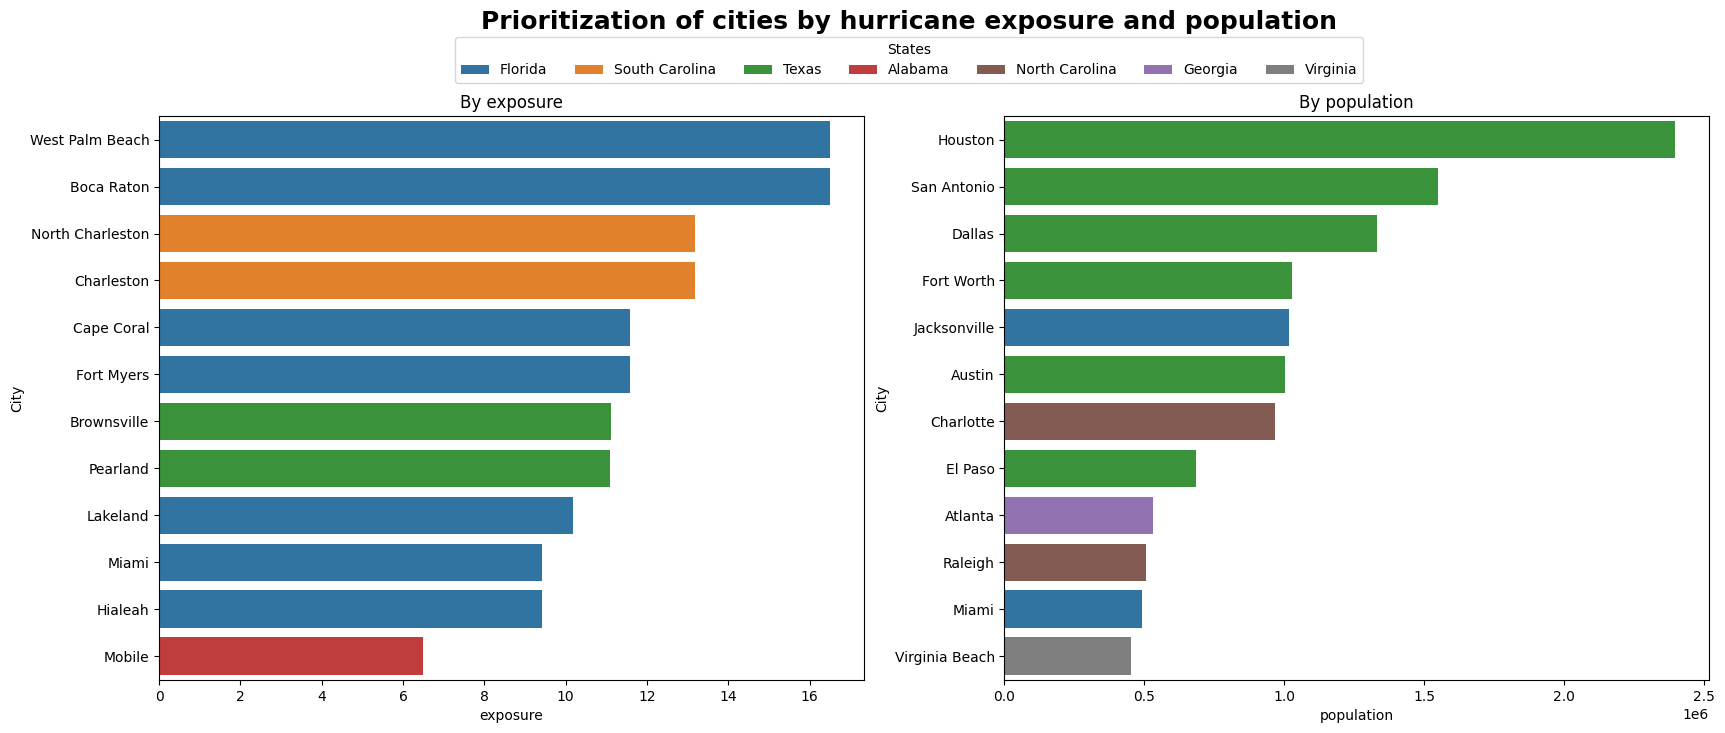

In [ ]:
# Retrieving th edata
chart_2 = cities_index.copy()
chart_2 = chart_2.rename(columns={'Census 2025':'population'})
labels = []

# Creating and formatting the chart
fig, ax = plt.subplots(1,2, figsize=(20, 8))
regions = chart_2['State'].dropna().unique()
palette = dict(zip(regions, sns.color_palette('tab10', n_colors=len(regions))))

#Ax 0
sns.barplot(x='exposure', y='City',hue='State',palette=palette,data=chart_2.sort_values(by='exposure',ascending=False).head(12), orient='h',ax=ax[0])
ax[0].set_title('By exposure')
ax[0].get_legend().remove()

#Ax 1
sns.barplot(x='population', y='City',hue='State',palette=palette, data=chart_2.sort_values(by='population',ascending=False).head(12), orient='h',ax=ax[1])
ax[1].set_title('By population')
ax[1].get_legend().remove()

# Figure
for a in ax:
    a.set_box_aspect(0.8)
h0, l0 = ax[0].get_legend_handles_labels()
h1, l1 = ax[1].get_legend_handles_labels()
by_label = dict(zip(l0 + l1, h0 + h1))
fig.legend(by_label.values(), by_label.keys(), title='States', loc='upper center', ncol=9, bbox_to_anchor=(0.5, 0.955))

fig.suptitle('Prioritization of cities by hurricane exposure and population', fontsize=18, fontweight='bold');

**Takeaway:** Population and the historical storm-center county proxy measure different things. The latter is not a verified measure of city-level wind exposure, and counties shared by multiple cities receive identical values. Rankings should be considered exploratory until storm wind fields, missing geographic matches, and observation-era coverage are validated.


,City,State,county,exposure
Rank,,,,
1,West Palm Beach,Florida,Palm Beach County,16.50
2,Boca Raton,Florida,Palm Beach County,16.50
3,North Charleston,South Carolina,Charleston County,13.17
4,Charleston,South Carolina,Charleston County,13.17
5,Cape Coral,Florida,Lee County,11.58


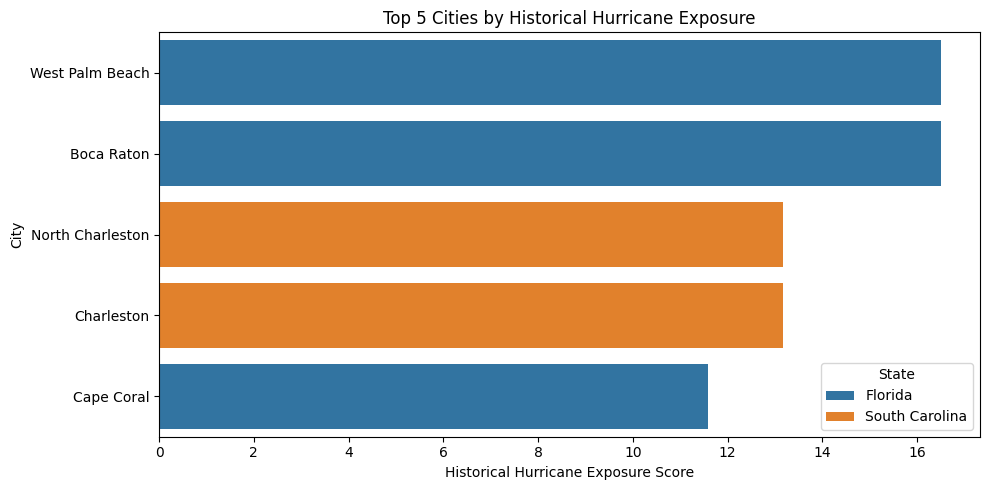

In [ ]:
# Top 5 cities by historical hurricane exposure
top_5 = ( cities_index[['City', 'State', 'county', 'exposure']] .dropna(subset=['exposure'])
    .sort_values('exposure', ascending=False, kind='stable') .head(5) .reset_index(drop=True) )

top_5.index = top_5.index + 1
top_5.index.name = 'Rank'

display(top_5.round(2))

plt.figure(figsize=(10, 5))

sns.barplot( data=top_5, x='exposure', y='City', hue='State', dodge=False )

plt.title('Top 5 Cities by Historical Hurricane Exposure')
plt.xlabel('Historical Hurricane Exposure Score')
plt.ylabel('City')
plt.tight_layout()
plt.show()

In [ ]:
# Hurricane/weather validation audit — does not modify transportation data or models.

# Verify the corrected time-weighted storm-center exposure formula independently.
_track = hurricanes_hours.sort_values(['storm_id', 'time_stamp']).copy()
_prev_status = _track.groupby('storm_id')['status'].shift()
_prev_wind = _track.groupby('storm_id')['max_wind_knots'].shift()
_delta = _track.groupby('storm_id')['time_stamp'].diff().dt.total_seconds().div(3600)
_valid = (_track['status'].eq('HU') & _prev_status.eq('HU') & _delta.gt(0) & _delta.le(6))
_category = pd.cut(_prev_wind, bins=[0,64,83,96,113,137,np.inf],
                   labels=[0,1,2,3,4,5], right=False).astype(float).fillna(0)
_expected = (_category * (_delta.where(_valid, 0).fillna(0) / 6)).where(_valid, 0)
assert np.allclose(_track['exposure'].to_numpy(dtype=float),
                   _expected.to_numpy(dtype=float), equal_nan=False), 'Exposure calculation differs from independent formula'
assert not ((_track['exposure'] > 0) & ~_valid).any(), 'Positive exposure outside eligible HU intervals'
assert not ((_track['exposure'] > 0) & _delta.gt(6)).any(), 'Long interval contributes exposure'
assert not ((_track['exposure'] > 0) & _track['status'].ne('HU')).any(), 'Non-HU contribution'
assert not temperature_lookup.duplicated(['year','month']).any(), 'Duplicate SST calendar months'
assert storm_data_impute[['year','month']].notna().all(axis=1).all(), 'Missing storm calendar keys'
assert cities_index['exposure'].dropna().ge(0).all(), 'Negative city exposure'

_sst_start = (int(temperature_lookup['year'].min()), int(temperature_lookup['month'].min()))
_sst_end = (int(temperature_lookup['year'].max()), int(temperature_lookup['month'].max()))
_storm_keys = storm_data_impute[['year','month']]
_coverage = storm_data_impute['N-Atl-Temp'].notna().mean()
_in_range = ((_storm_keys['year']*12+_storm_keys['month']) >= (_sst_start[0]*12+_sst_start[1])) & ((_storm_keys['year']*12+_storm_keys['month']) <= (_sst_end[0]*12+_sst_end[1]))
print('PASS: HU-to-HU, <=6-hour exposure formula independently reproduced')
print('PASS: non-HU and >6-hour intervals contribute no exposure')
print(f'SST available calendar range: {_sst_start} to {_sst_end}')
print(f'SST match coverage, all historical storm observations: {_coverage:.1%}')
print(f'SST match coverage, storm observations within source calendar range: {storm_data_impute.loc[_in_range,"N-Atl-Temp"].notna().mean():.1%}' if _in_range.any() else 'No storm observations in SST calendar range')
print('Cities without matched county exposure:', int(cities_index['exposure'].isna().sum()))
print('Unique counties among top five:', int(top_5[['State','county']].drop_duplicates().shape[0]))
print('IMPORTANT: county storm-center exposure is a screening proxy; geographic wind-field impacts are NOT validated.')
print('IMPORTANT: this cell does not establish independent NOAA source-file or city-level physical validation.')

PASS: HU-to-HU, <=6-hour exposure formula independently reproduced
PASS: non-HU and >6-hour intervals contribute no exposure
SST available calendar range: (1982, 1) to (2026, 12)
SST match coverage, all historical storm observations: 36.7%
SST match coverage, storm observations within source calendar range: 100.0%
Cities without matched county exposure: 31
Unique counties among top five: 3
IMPORTANT: county storm-center exposure is a screening proxy; geographic wind-field impacts are NOT validated.
IMPORTANT: this cell does not establish independent NOAA source-file or city-level physical validation.


### Question 3: Where is historical hurricane exposure concentrated along the coastal relief-service area?

**Decision supported:** Identify coastal counties that deserve further consideration for advance planning, inventory positioning, and network coverage. The map displays the notebook's corrected county-level historical exposure index, allowing geographic comparison across the service area. It is a **historical screening indicator**, not a forecast, a verified wind-impact map, or a measurement of transportation disruption.


In [ ]:
# Retrieve corrected county hurricane exposure scores
chart_map = hurricane_index[ ["region", "county", "exposure"] ].copy()

coast = coast_df.copy()

# Load US county boundaries
counties_geoid = gpd.read_file(
    "https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_county_500k.zip" ).to_crs("EPSG:4326")

# Match county names to Census GEOIDs
counties_df = ( pd.read_csv( os.path.join( os.path.dirname(rg.__file__), "rg_cities1000.csv" ) ) .query("cc == 'US'")
    .rename(columns={ "admin1": "region", "admin2": "county" }) [["region", "county", "lat", "lon"]] .dropna() )

points = gpd.GeoDataFrame(
    counties_df, geometry=gpd.points_from_xy( counties_df["lon"], counties_df["lat"] ), crs="EPSG:4326" )

points = gpd.sjoin(
    points, counties_geoid[["GEOID", "geometry"]], how="left", predicate="within" ).dropna(subset=["GEOID"])

county_geoid = ( points.groupby( ["region", "county"], as_index=False )["GEOID"] .agg(lambda s: s.mode().iloc[0]) )

# Match corrected exposure scores to coastal counties
chart_map = chart_map.merge( county_geoid, on=["region", "county"], how="left" )

coast = coast.merge( county_geoid, on=["region", "county"], how="left" )

coastal_geoids = coast["GEOID"].dropna().unique()

poly_map1 = counties_geoid[ counties_geoid["GEOID"].isin(coastal_geoids) ].copy()

geojson_map1 = json.loads( poly_map1[["GEOID", "geometry"]].to_json() )

# Keep only coastal counties with valid corrected exposure
chart_map = chart_map[ chart_map["GEOID"].isin(coastal_geoids) ].copy()

chart_map["exposure"] = pd.to_numeric( chart_map["exposure"], errors="coerce" )

chart_map = chart_map.dropna( subset=["GEOID", "exposure"] )

chart_map = chart_map.drop_duplicates( subset=["GEOID"] )

# Create corrected hurricane exposure map
fig_map1 = px.choropleth_map( chart_map, geojson=geojson_map1, locations="GEOID", featureidkey="properties.GEOID",
    color="exposure", hover_name="county", hover_data={ "region": True, "GEOID": False, "exposure": ":.2f"
    }, color_continuous_scale="YlOrRd", range_color=[ 0, chart_map["exposure"].max() ], center={ "lat": 32, "lon": -85
    }, map_style="carto-positron", zoom=3.7, opacity=0.85, labels={ "exposure": "Historical exposure score" } )

fig_map1.update_traces( marker_line_width=0.4, marker_line_color="gray" )

fig_map1.update_layout(
    title=dict( text="<b>Historical Hurricane Exposure by Coastal County</b>", x=0.5, xanchor="center", y=0.97,
        yanchor="top", font=dict( size=18, color="black" ) ), height=520, margin=dict( l=40, r=40, t=110, b=40 ),
    coloraxis_colorbar=dict( title=dict( text="Corrected exposure score", side="top", font=dict( size=12, color="black"
            ) ), orientation="h", x=0.5, xanchor="center", y=1.1, yanchor="middle", len=0.6, thickness=15,
        bgcolor="white", bordercolor="lightgray", borderwidth=1, tickfont=dict( size=10, color="black" ) ) )

fig_map1.show( config={ "scrollZoom": False, "doubleClick": False, "displayModeBar": False } )

### Question 4: When should the relief network complete seasonal hurricane-readiness preparations?

**Decision supported:** Inform the **timing** of pre-season capacity checks, carrier arrangements, and inventory-readiness reviews. The graph shows the historical month in which each distinct Atlantic storm first reached hurricane status during 1990–2025, together with the cumulative percentage through the year. Basin-wide timing is a preparedness reference; it cannot predict the date or location of the next damaging event.


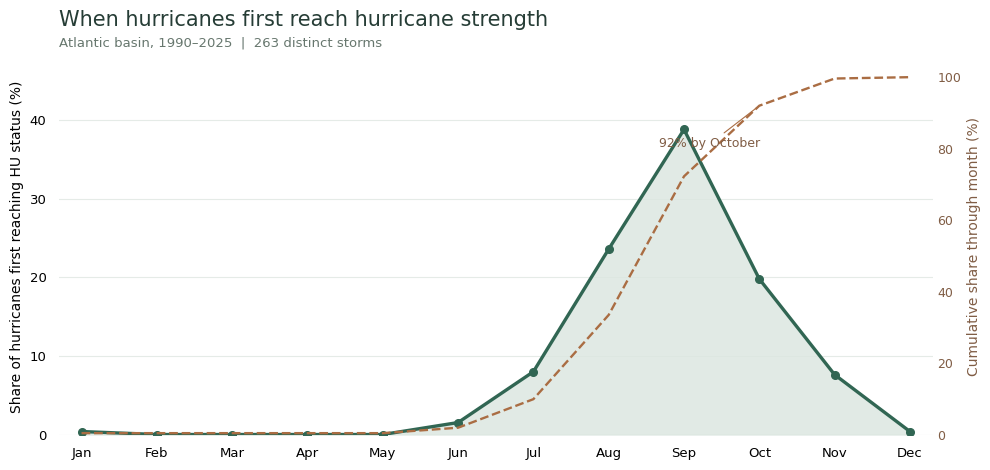

In [ ]:
# Historical timing of first hurricane-status occurrence, 1990–2025

hu_start = ( storm_data_clean.loc[ storm_data_clean["status"].eq("HU")
        & storm_data_clean["year"].between(1990, 2025), ["storm_id", "year", "month"]
    ] .dropna() .sort_values(["year", "month"]) .drop_duplicates("storm_id", keep="first") )
if hu_start.empty:
    raise ValueError("No Atlantic hurricane-status records found for 1990–2025.")

monthly_counts = hu_start["month"].astype(int).value_counts().reindex(range(1, 13), fill_value=0)
monthly_pct = monthly_counts / monthly_counts.sum() * 100
cumulative_pct = monthly_pct.cumsum()
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
x = np.arange(12)

fig, ax = plt.subplots(figsize=(11.2, 5.6), facecolor="white")
ax.set_facecolor("white")
ax.fill_between(x, monthly_pct.values, color="#DCE7E1", alpha=0.85, zorder=1)
ax.plot(x, monthly_pct.values, color="#316653", linewidth=2.4, marker="o",
        markersize=5.5, zorder=3)
ax.set_xticks(x, months)
ax.set_xlim(-0.3, 11.3)
ax.set_ylim(0, max(monthly_pct.max() * 1.23, 10))
ax.set_ylabel("Share of hurricanes first reaching HU status (%)", fontsize=10)
ax.set_title("When hurricanes first reach hurricane strength", loc="left",
             fontsize=15, fontweight="regular", pad=24, color="#263D36")
ax.text(0, 1.035, f"Atlantic basin, 1990–2025  |  {len(hu_start):,} distinct storms",
        transform=ax.transAxes, fontsize=9.5, color="#67776E")
ax.grid(axis="y", color="#E5EBE7", linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, pad=9, labelsize=9.5)
for spine in ax.spines.values(): spine.set_visible(False)

ax2 = ax.twinx()
ax2.plot(x, cumulative_pct.values, color="#AA6D43", linewidth=1.7,
         linestyle="--", zorder=2)
ax2.set_ylim(0, 105)
ax2.set_ylabel("Cumulative share through month (%)", fontsize=10, color="#805D45")
ax2.tick_params(axis="y", colors="#805D45", length=0, labelsize=9)
for spine in ax2.spines.values(): spine.set_visible(False)
ax2.annotate(f"{cumulative_pct.iloc[9]:.0f}% by October", xy=(9, cumulative_pct.iloc[9]), xytext=(-72, -30),
             textcoords="offset points", fontsize=9, color="#805D45",
             arrowprops={"arrowstyle":"-", "color":"#AA6D43", "lw":0.8})
fig.subplots_adjust(left=.10, right=.88, top=.82, bottom=.15)
plt.show()

**Takeaway:** The monthly distribution identifies when storms have historically first reached hurricane strength, helping justify the timing of seasonal readiness and inventory staging. The cumulative line shows how much of that historical activity has occurred by each month. These basin-wide counts do not predict local landfalls or prove that supplies should be deployed on a particular date.


### Question 5: Is tropical Atlantic sea-surface temperature anomaly a useful contextual indicator of observed hurricane intensity?

**Decision supported:** Assess whether the available SST anomaly series provides useful **environmental context** for interpreting historical hurricane severity. Each point represents a distinct hurricane, with its mean tropical Atlantic monthly SST anomaly during hurricane-status months and maximum observed wind speed. The relationship is descriptive, may be confounded by other atmospheric factors, and must **not** be used as a standalone intensity forecast or routing trigger.


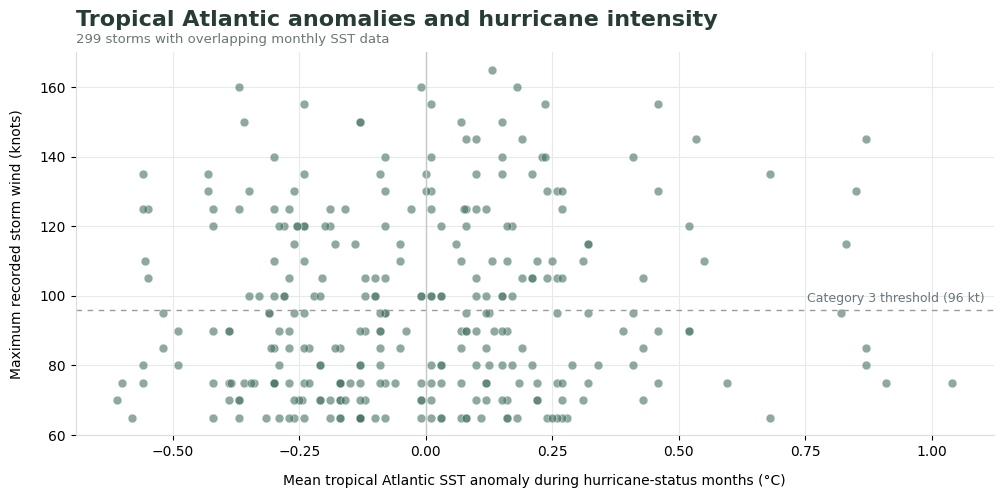

In [ ]:
# Storm-level relationship between tropical Atlantic SST anomalies and peak wind
sst_monthly = temperature_df[["Year", "Month", "Trop-Atl-Anom"]].copy()
sst_monthly.columns = ["year", "month", "sst_anomaly"]
sst_monthly["sst_anomaly"] = pd.to_numeric(sst_monthly["sst_anomaly"], errors="coerce")

hu_months = (storm_data_clean.loc[storm_data_clean["status"].eq("HU"),
                                   ["storm_id", "year", "month"]] .drop_duplicates())
storm_sst = hu_months.merge(sst_monthly, on=["year", "month"], how="inner")
storm_sst = storm_sst.groupby("storm_id", as_index=False).agg( sst_anomaly=("sst_anomaly", "mean"))
storm_peaks = (storm_data_clean.groupby("storm_id", as_index=False) .agg(peak_wind_knots=("max_wind_knots", "max")))
relationship = storm_sst.merge(storm_peaks, on="storm_id").dropna()
relationship = relationship[np.isfinite(relationship["sst_anomaly"]) & np.isfinite(relationship["peak_wind_knots"])]
if len(relationship) < 3:
    raise ValueError("Not enough overlapping storm and SST observations for this plot.")

fig, ax = plt.subplots(figsize=(10.8, 5.8), facecolor="white")
ax.scatter(relationship["sst_anomaly"], relationship["peak_wind_knots"],
           s=40, alpha=.62, color="#477765", edgecolors="white", linewidth=.45)
ax.axhline(96, color="#9B9D94", lw=1, ls=(0,(4,4)))
ax.text(.99, 96+1.5, "Category 3 threshold (96 kt)", transform=ax.get_yaxis_transform(),
        ha="right", va="bottom", fontsize=9, color="#687781")
ax.axvline(0, color="#C3CAC4", lw=1)
ax.set_xlabel("Mean tropical Atlantic SST anomaly during hurricane-status months (°C)", labelpad=11)
ax.set_ylabel("Maximum recorded storm wind (knots)", labelpad=11)
ax.set_title("Tropical Atlantic anomalies and hurricane intensity", loc="left",
             fontsize=16, fontweight="semibold", pad=19, color="#263D36")
ax.text(0, 1.025, f"{len(relationship):,} storms with overlapping monthly SST data",
        transform=ax.transAxes, fontsize=9.5, color="#68796F")
ax.grid(color="#E5EBE7", linewidth=.8)
ax.set_axisbelow(True)
for spine in ["top","right"]: ax.spines[spine].set_visible(False)
for spine in ["bottom","left"]: ax.spines[spine].set_color("#D7DFD8")
fig.subplots_adjust(left=.11, right=.96, top=.84, bottom=.18)
plt.show()

**Takeaway:** The point cloud provides a storm-level descriptive comparison, avoiding the false precision of treating repeated six-hour observations as independent storms. Any visible association is not evidence that SST anomalies alone caused a storm's peak intensity; atmospheric conditions, track, and observational coverage also matter.


### Question 6: Is the historical exposure of priority coastal counties concentrated in a few decades or spread across the record?

**Decision supported:** Test whether cumulative county exposure rankings are driven primarily by isolated historical periods, which affects how cautiously those rankings should be interpreted in long-term network planning. The bubble matrix decomposes the corrected historical storm-center exposure index by decade for the twelve highest-scoring counties. It does not measure actual county-wide losses, landfall counts, or future probabilities.


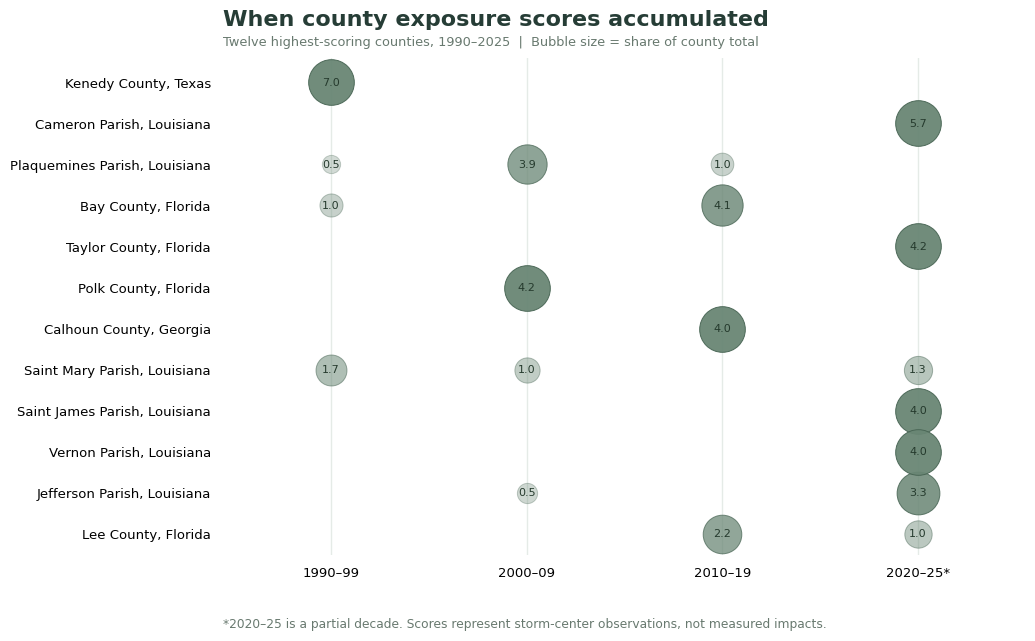

In [ ]:
# Decade-by-decade decomposition of the corrected county storm-center exposure proxy
county_history = hurricanes_in_US[["region", "county", "year", "exposure"]].copy()
county_history["exposure"] = pd.to_numeric(county_history["exposure"], errors="coerce")
county_history = county_history.dropna(subset=["region", "county", "year", "exposure"])
county_history = county_history[county_history["year"].between(1990, 2025)].copy()
county_history["decade"] = (county_history["year"].astype(int) // 10) * 10
county_history["county_label"] = county_history["county"].astype(str) + ", " + county_history["region"].astype(str)
by_decade = county_history.groupby(["county_label", "decade"], as_index=False)["exposure"].sum()
leaders = (by_decade.groupby("county_label")["exposure"].sum() .sort_values(ascending=False).head(12))
if leaders.empty or leaders.max() <= 0:
    raise ValueError("No positive county exposure scores for 1990–2025.")
selected = by_decade[by_decade["county_label"].isin(leaders.index)].copy()
selected["county_label"] = pd.Categorical(selected["county_label"], categories=leaders.index, ordered=True)
selected["share"] = selected["exposure"] / selected["county_label"].map(leaders).astype(float)

fig, ax = plt.subplots(figsize=(11.8, 7.0), facecolor="white")
for _, row in selected.iterrows():
    if row["exposure"] <= 0: continue
    x = [1990,2000,2010,2020].index(int(row["decade"]))
    y = list(leaders.index).index(str(row["county_label"]))
    ax.scatter(x, y, s=80 + 1000 * row["share"], color="#698674",
               alpha=.23 + .72 * row["share"], edgecolor="#486554", linewidth=.7)
    ax.text(x, y, f"{row['exposure']:.1f}", ha="center", va="center",
            fontsize=8, color="#253A2D")
ax.set_xticks(range(4), ["1990–99", "2000–09", "2010–19", "2020–25*"])
ax.set_yticks(range(len(leaders)), leaders.index)
ax.invert_yaxis()
ax.set_xlim(-.55, 3.55)
ax.set_ylim(len(leaders)-.5, -.6)
ax.tick_params(length=0, labelsize=9.5, pad=9)
ax.set_axisbelow(True)
ax.grid(axis="x", color="#E5EBE7", linewidth=1)
for spine in ax.spines.values(): spine.set_visible(False)
ax.set_title("When county exposure scores accumulated", loc="left",
             fontsize=16, fontweight="semibold", pad=23, color="#263D36")
ax.text(0, 1.025, "Twelve highest-scoring counties, 1990–2025  |  Bubble size = share of county total",
        transform=ax.transAxes, fontsize=9.3, color="#68796F")
fig.text(.28, .035, "*2020–25 is a partial decade. Scores represent storm-center observations, not measured impacts.",
         fontsize=8.8, color="#68796F")
fig.subplots_adjust(left=.28, right=.96, top=.85, bottom=.14)
plt.show()

**Takeaway:** The bubble matrix separates *when* each county accumulated its historical storm-center index from *how large* the cumulative index is. Because the source is based on sampled storm-center locations and six-hour-equivalent intervals, the scores should not be interpreted as observed wind fields, property damage, or forecasts.


### Question 7: How much routing error would result from using straight-line distance instead of modeled truck-road distance?

**Decision supported:** Determine whether straight-line distance is sufficiently accurate for initial hub screening or whether the project should rely on routed road distance. The graph compares both measures for the **1,446 modeled hub–destination pairs**. Its purpose is to validate the network-distance assumption used in the relief optimization—not to estimate storm-related road closures.


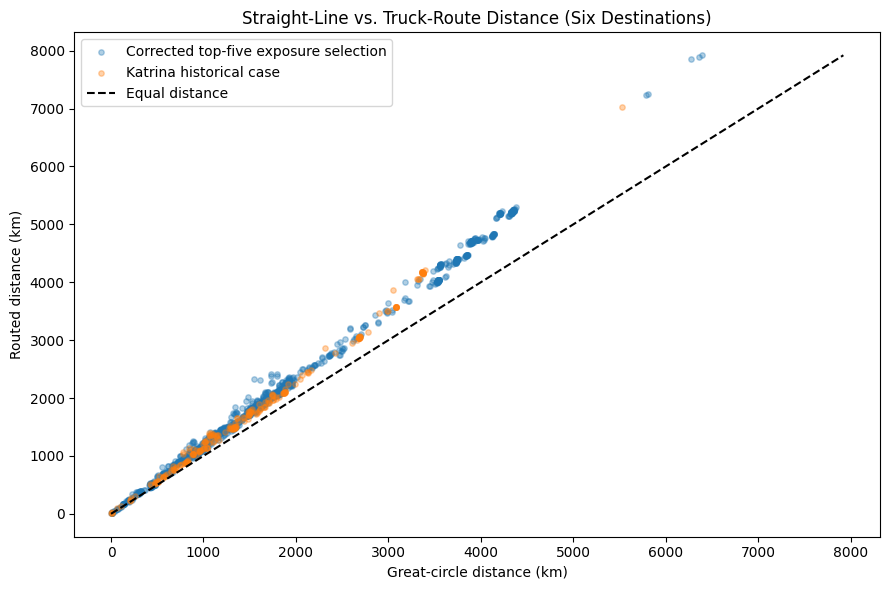

Median road / straight-line ratio: 1.176
Mean additional routed distance (km): 325.6


In [ ]:
# Compare great-circle distance with routed distance for all six selected destinations.
route_compare = truck_routes.copy()
lat1 = np.radians(route_compare["hub_latitude"].astype(float))
lon1 = np.radians(route_compare["hub_longitude"].astype(float))
lat2 = np.radians(route_compare["destination_latitude"].astype(float))
lon2 = np.radians(route_compare["destination_longitude"].astype(float))
a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
route_compare["straight_line_km"] = 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
route_compare["road_straight_ratio"] = route_compare["distance_km"] / route_compare["straight_line_km"]

plt.figure(figsize=(9, 6))
for name, group in route_compare.groupby("analysis_role"):
    plt.scatter(group["straight_line_km"], group["distance_km"], alpha=0.35, s=15, label=name)
max_distance = max(route_compare["straight_line_km"].max(), route_compare["distance_km"].max())
plt.plot([0, max_distance], [0, max_distance], linestyle="--", color="black", label="Equal distance")
plt.title("Straight-Line vs. Truck-Route Distance (Six Destinations)")
plt.xlabel("Great-circle distance (km)")
plt.ylabel("Routed distance (km)")
plt.legend()
plt.tight_layout()
plt.show()

print("Median road / straight-line ratio:", round(route_compare["road_straight_ratio"].median(), 3))
print("Mean additional routed distance (km):", round((route_compare["distance_km"] - route_compare["straight_line_km"]).mean(), 1))

**Takeaway:** The scatterplot compares the actual road-route distance against the great-circle distance for each of the 1,446 selected connections. Points above the dashed equality line require more road travel than their straight-line separation suggests. The printed statistics quantify that difference from the updated workbooks rather than reusing the old 545-route results.

**Limitation:** These are normal-condition road estimates. The Palm Beach destination is a proxy for West Palm Beach, and ordinary-driving fallbacks do not establish HGV restriction compliance.


### Question 8: Which intermodal origins offer the shortest modeled trucking time to each relief destination?

**Decision supported:** Produce an initial **primary-origin shortlist** for Palm Beach, Boca Raton, North Charleston, Charleston, and Cape Coral, plus the separate New Orleans historical case study. The graph shows minimum modeled normal-condition travel times across 241 candidate hubs per destination. A shortest-time route is a screening result, **not** confirmation of terminal capacity, freight availability, or post-storm accessibility.


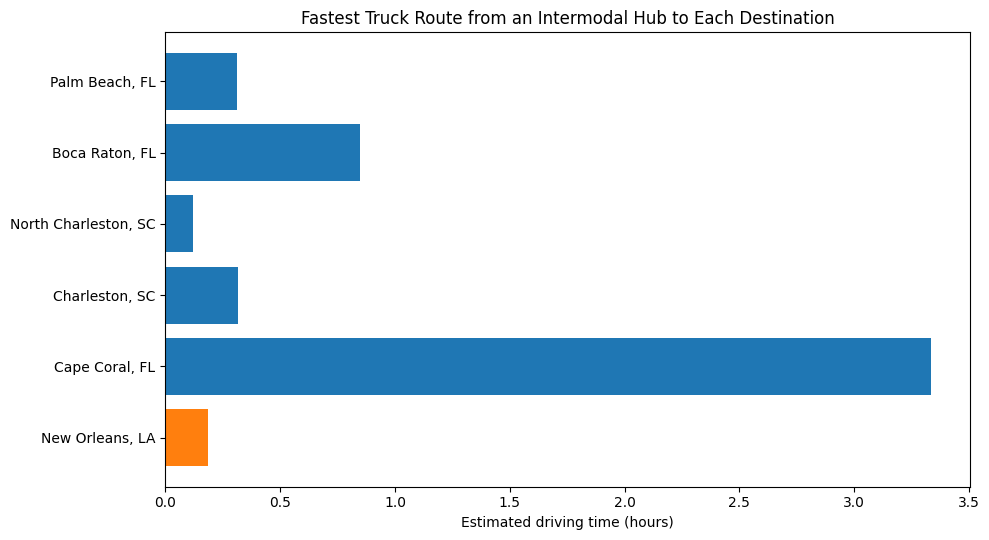

Median of the six fastest-route times (hours): 0.32


,city_display,analysis_role,Fastest hub,distance_km,duration_hours,route_status
0,"Palm Beach, FL",Corrected top-five exposure selection,"Palm Beach Terminal — Riviera Beach, FL",10.605,0.313,routed
1,"Boca Raton, FL",Corrected top-five exposure selection,"Fort Lauderdale, FL — Ft. Lauderdale, FL",41.673,0.846,routed
2,"North Charleston, SC",Corrected top-five exposure selection,"Charleston, SC — North Charleston, SC",5.872,0.122,routed
3,"Charleston, SC",Corrected top-five exposure selection,"Charleston, SC — North Charleston, SC",14.690,0.318,routed
4,"Cape Coral, FL",Corrected top-five exposure selection,"Winter Haven, FL - Central Florida Intermodal ...",189.405,3.336,routed
5,"New Orleans, LA",Katrina historical case,"New Orleans, LA — New Orleans, LA",6.826,0.186,routed


In [ ]:
# Find the fastest route among 241 candidate intermodal origins for each destination.
fastest_truck = (
    truck_routes.sort_values(["duration_hours", "distance_km"]) .groupby("destination", as_index=False).first() )
plot_order = ["Palm Beach, FL", "Boca Raton, FL", "North Charleston, SC", "Charleston, SC", "Cape Coral, FL", "New Orleans, LA"]
fastest_truck = fastest_truck.set_index("destination").loc[plot_order].reset_index()

plt.figure(figsize=(10, 5.5))
colors = ["tab:orange" if city == "New Orleans, LA" else "tab:blue" for city in fastest_truck["destination"]]
plt.barh(fastest_truck["city_display"], fastest_truck["duration_hours"], color=colors)
plt.gca().invert_yaxis()
plt.title("Fastest Truck Route from an Intermodal Hub to Each Destination")
plt.xlabel("Estimated driving time (hours)")
plt.tight_layout()
plt.show()

print("Median of the six fastest-route times (hours):", round(fastest_truck["duration_hours"].median(), 2))
display(fastest_truck[["city_display", "analysis_role", "hub_label", "distance_km", "duration_hours", "route_status"]].rename(columns={"hub_label": "Fastest hub"}))

**Takeaway:** The chart identifies the minimum modeled truck driving time among the 241 intermodal hubs for each destination. The accompanying table identifies the corresponding facility and routing status. New Orleans is included only as a historical Katrina comparison. The West Palm Beach result uses the Palm Beach routing proxy.

**Limitation:** A fastest route is not necessarily a feasible relief origin: inventory, road closures, flooding, terminal capacity, loading/unloading, and driver constraints are not modeled in these times.


### Question 9: How much additional travel time separates the three quickest candidate routes for each destination?

**Decision supported:** Determine whether the relief network has several similarly fast **route candidates** or depends heavily on a single fastest option. The graph compares the three lowest modeled travel times for each destination, expressed as minutes beyond the fastest route. These are route-level candidates; the chart does **not** establish that they represent independent terminals, road corridors, or operators.


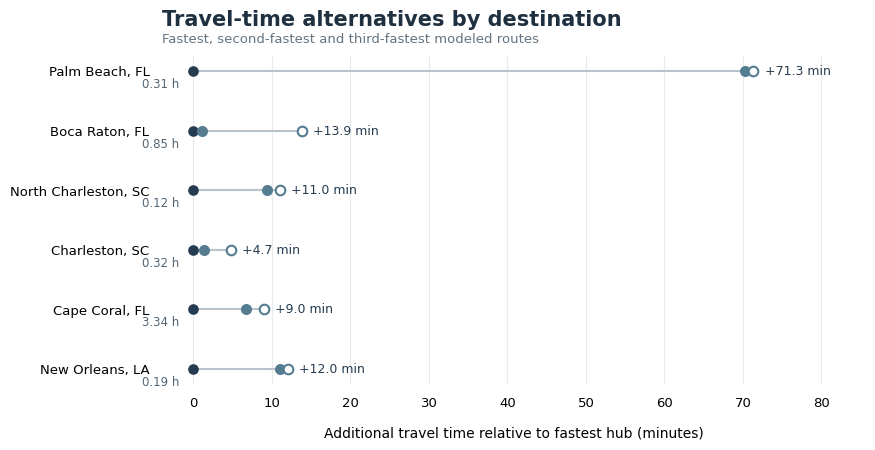

,city_display,rank,hub_label,duration_hours,route_status
645,"Boca Raton, FL",1,"Fort Lauderdale, FL — Ft. Lauderdale, FL",0.846,routed
650,"Boca Raton, FL",2,"Fort Lauderdale, FL - Intermodal Container Tra...",0.865,routed
155,"Boca Raton, FL",3,"Palm Beach Terminal — Riviera Beach, FL",1.077,routed
1681,"Cape Coral, FL",1,"Winter Haven, FL - Central Florida Intermodal ...",3.336,routed
1259,"Cape Coral, FL",2,"Hooker's Point Container Terminal — Tampa, FL",3.447,routed
1663,"Cape Coral, FL",3,"Tampa, FL — Tampa, FL",3.486,routed
401,"Charleston, SC",1,"Charleston, SC — North Charleston, SC",0.318,routed
101,"Charleston, SC",2,Hugh K. Leatherman Terminal — North Charleston...,0.340,routed
96,"Charleston, SC",3,"Wando Welch Terminal — Mt. Pleasant, SC",0.397,routed_osrm_driving_fallback
1578,"New Orleans, LA",1,"New Orleans, LA — New Orleans, LA",0.186,routed


In [ ]:
# Question 5: travel-time trade-off across the three quickest candidate hubs
top_three = ( truck_routes.sort_values(["duration_hours", "distance_km"])
    .groupby("destination", group_keys=False).head(3).copy() )
top_three["rank"] = top_three.groupby("destination").cumcount() + 1
wide = top_three.pivot(index="destination", columns="rank", values="duration_hours").loc[plot_order]
wide.index = [ truck_routes.loc[truck_routes["destination"].eq(city), "city_display"].iloc[0] for city in wide.index ]

minutes_over_fastest = wide.sub(wide[1], axis=0) * 60
fig, ax = plt.subplots(figsize=(10.5, 5.2))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
y = np.arange(len(wide))
for i, city in enumerate(wide.index):
    vals = minutes_over_fastest.iloc[i, [0, 1, 2]].to_numpy()
    ax.plot(vals, [i] * 3, color="#B9C3CC", lw=1.5, zorder=1)
    ax.scatter(vals[0], i, s=44, color="#253B50", zorder=3)
    ax.scatter(vals[1], i, s=48, color="#557C91", zorder=3)
    ax.scatter(vals[2], i, s=48, facecolors="white",
               edgecolors="#557C91", linewidth=1.5, zorder=3)
    ax.annotate(f"{wide.iloc[i,0]:.2f} h", (0, i), xytext=(-10, -12), textcoords="offset points",
                ha="right", fontsize=8.5, color="#526575")
    ax.annotate(f"+{vals[2]:.1f} min", (vals[2], i), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=9, color="#253B50")
ax.set_yticks(y, wide.index)
ax.invert_yaxis()
ax.set_xlim(-4, max(80, minutes_over_fastest[3].max() * 1.2))
ax.set_xlabel("Additional travel time relative to fastest hub (minutes)", labelpad=12, fontsize=10)
ax.set_title("Travel-time alternatives by destination", loc="left",
             fontsize=15, fontweight="semibold", pad=22, color="#1F3040")
ax.text(0, 1.04, "Fastest, second-fastest and third-fastest modeled routes",
        transform=ax.transAxes, fontsize=9.5, color="#647482")
ax.grid(axis="x", color="#E7EAED", linewidth=.8)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, labelsize=9.5, pad=9)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.subplots_adjust(left=.25, right=.92, top=.80, bottom=.17)
plt.show()
display(top_three.sort_values(["destination", "rank"])[
    ["city_display", "rank", "hub_label", "duration_hours", "route_status"] ])

**Takeaway:** The three fastest routes reveal whether there are close alternatives to each destination's fastest hub. The results are candidates for further resilience screening, not a guarantee that any hub will remain usable after a storm. The Palm Beach proxy and any non-HGV fallback qualifications still apply.


### Question 10: What is the normal-condition time penalty of substituting the next-fastest route if the preferred route cannot be used?

**Decision supported:** Quantify a **baseline switching penalty** for contingency planning and identify destinations where the next-fastest modeled option is relatively costly. The graph reports the extra minutes for the second-fastest route versus the fastest route. This is a route-ranking sensitivity test, **not** a simulation of hurricane-damaged roads or proof that the alternative origin remains operational.


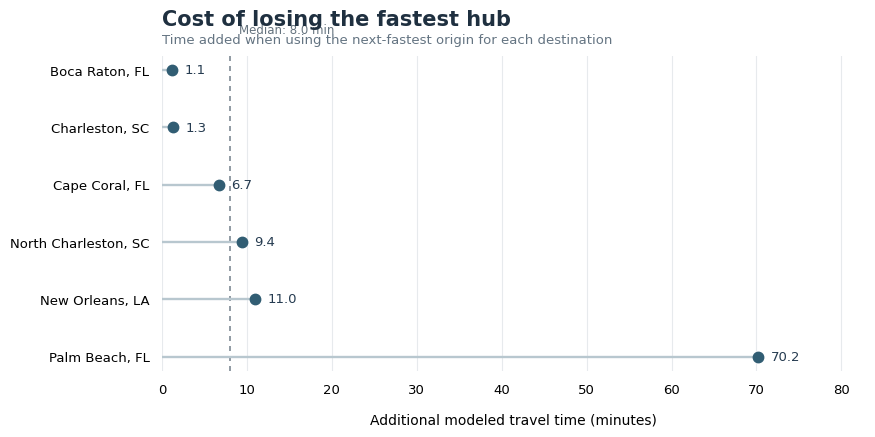

Median second-choice penalty (minutes): 8.0


rank,Fastest (hr),Second-fastest (hr),Additional minutes
"Palm Beach, FL",0.313,1.483,70.20
"Boca Raton, FL",0.846,0.865,1.14
"North Charleston, SC",0.122,0.279,9.42
"Charleston, SC",0.318,0.340,1.32
"Cape Coral, FL",3.336,3.447,6.66
"New Orleans, LA",0.186,0.369,10.98


In [ ]:
# Question 6: penalty for substituting the second-fastest hub
backup = wide.copy()
backup["extra_hours"] = backup[2] - backup[1]
backup["extra_minutes"] = backup["extra_hours"] * 60
penalties = backup["extra_minutes"].sort_values(ascending=True)
median_penalty = float(penalties.median())

fig, ax = plt.subplots(figsize=(10.5, 5.0))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
y = np.arange(len(penalties))
ax.hlines(y, 0, penalties.values, color="#B8C7CF", linewidth=1.7)
ax.scatter(penalties.values, y, s=56, color="#315D73", zorder=3)
ax.axvline(median_penalty, color="#7D8993", linestyle=(0, (3, 3)),
           linewidth=1.2, zorder=1)
for i, value in enumerate(penalties.values):
    ax.annotate(f"{value:.1f}", (value, i), xytext=(9, 0), textcoords="offset points", va="center",
                fontsize=9.5, color="#253B50")
ax.set_yticks(y, penalties.index)
ax.invert_yaxis()
ax.set_xlim(0, max(80, penalties.max() * 1.18))
ax.set_xlabel("Additional modeled travel time (minutes)", fontsize=10, labelpad=12)
ax.set_title("Cost of losing the fastest hub", loc="left",
             fontsize=15, fontweight="semibold", pad=22, color="#1F3040")
ax.text(0, 1.04, "Time added when using the next-fastest origin for each destination",
        transform=ax.transAxes, fontsize=9.5, color="#647482")
ax.text(median_penalty + 1, -0.65, f"Median: {median_penalty:.1f} min",
        fontsize=8.5, color="#65737E")
ax.grid(axis="x", color="#E7EAED", linewidth=.8)
ax.set_axisbelow(True)
ax.tick_params(axis="both", length=0, labelsize=9.5, pad=9)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.subplots_adjust(left=.25, right=.92, top=.80, bottom=.17)
plt.show()
print("Median second-choice penalty (minutes):", round(median_penalty, 1))
display(backup[[1, 2, "extra_minutes"]].rename(
    columns={1: "Fastest (hr)", 2: "Second-fastest (hr)", "extra_minutes": "Additional minutes"}))

**Takeaway:** The time penalty quantifies how much slower the next-best *modeled* truck route would be if the fastest hub were unavailable. This is a single-hub substitution scenario, not a hurricane disruption simulation. It does not assess whether either hub has supplies, operating capacity, or passable roads.


### Question 11: How is track mileage owned by six major railroads distributed across the nine hurricane-relevant states?

**Decision supported:** Identify where rail-operator coordination and track inspections may require the most planning. Ownership mileage measures network footprint, not confirmed hurricane damage or operational availability.


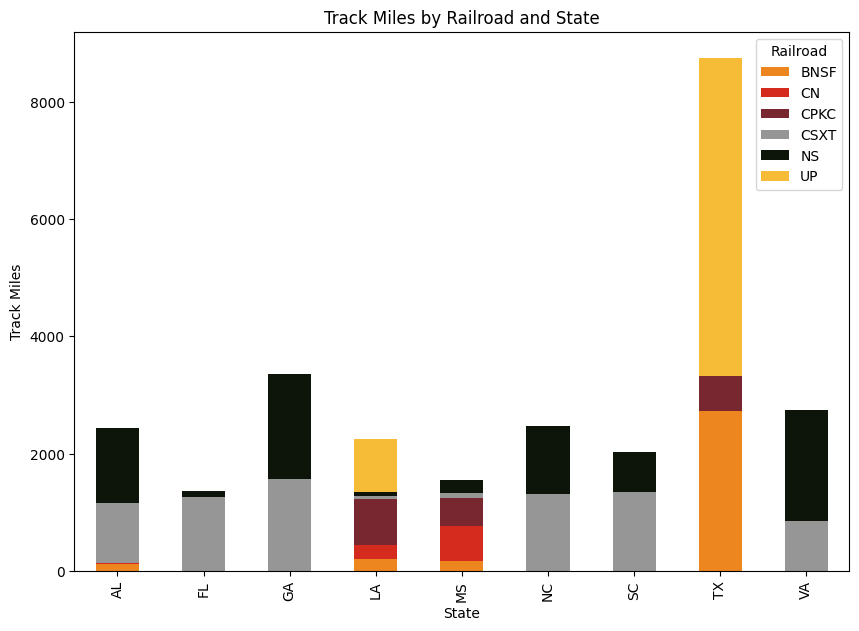

In [ ]:
#Read in the tracks master file
tracks = pd.read_excel(FILE_URLS["Master Sheet"])

#List of 9 highly impacted states to mask for new DataFrame
state_nine = ['TX', 'LA', 'MS', 'AL', 'GA', 'FL', 'SC', 'NC', 'VA']

nine_tracks = tracks[tracks['STATEAB_T'].isin(state_nine)]

# Inspect the track owners # Commented out to not disrupt chart
# print(nine_tracks[['RROWNER1_T','RROWNER2_T', 'RROWNER3_T']].nunique())
# print(tracks['RROWNER1_T'].value_counts()[:10])
# print(tracks['RROWNER2_T'].value_counts()[:10])
# print(tracks['RROWNER2_T'].value_counts()[:10])

#Note: Top companies are UP, BNSF, CSX(T is listed here), NS, CN, and CPKC
top_6 = ['UP', 'BNSF', 'CSXT', 'NS', 'CN', 'CPKC']

# Calculate miles by state and railroad
mileage = []

for state in state_nine:
    for rr in top_6:
        miles = nine_tracks[(nine_tracks['STATEAB_T'] == state) & (nine_tracks['RROWNER1_T'] == rr)]['MILES_T'].sum()
        mileage.append({'State': state, 'Railroad': rr, 'Miles': miles})

#Build a DataFrame from those results
miles_df = pd.DataFrame(mileage)

#Pivot table of miles_df where railroads are columns
plot_data = miles_df.pivot(index='State', columns='Railroad', values='Miles').fillna(0)

#Color codes for railroads as per http://www.railsimstuff.com/colors.html
rr_colors = {
    'UP': '#F7BC37',      # Union Pacific Armour Yellow
    'BNSF': '#ED861F',    # BNSF Orange
    'CSXT': '#969696',    # CSX Grey
    'NS': '#0D140A',      # Norfolk Southern Black
    'CN': '#D52B1E',      # Canadian National Red
    'CPKC': '#782730'     # Canadian Pacific Tuscan
}

colors = plot_data.columns.map(rr_colors)
# Stacked bar chart
plot_data.plot(kind='bar', stacked=True, color=colors, figsize=(10,7))

plt.xlabel('State')
plt.ylabel('Track Miles')
plt.title('Track Miles by Railroad and State')
plt.legend(title='Railroad')
plt.show()

**Takeaway:** The absolute-mileage chart shows how the selected railroad operators' mapped track ownership varies across the nine states. Texas contributes substantial mileage in this selection, but mileage alone does **not** establish that tracks would be damaged or that relief must be rerouted from a particular region.

**Limitation:** The segment dataset does not fully represent rail-yard ownership or post-storm accessibility.


### Question 12: How does each railroad's share of mapped track mileage differ within each state?

**Decision supported:** Compare the relative mix of rail operators within states without allowing larger states to dominate the visualization. This complements Question 11's absolute mileage rather than repeating the same comparison.


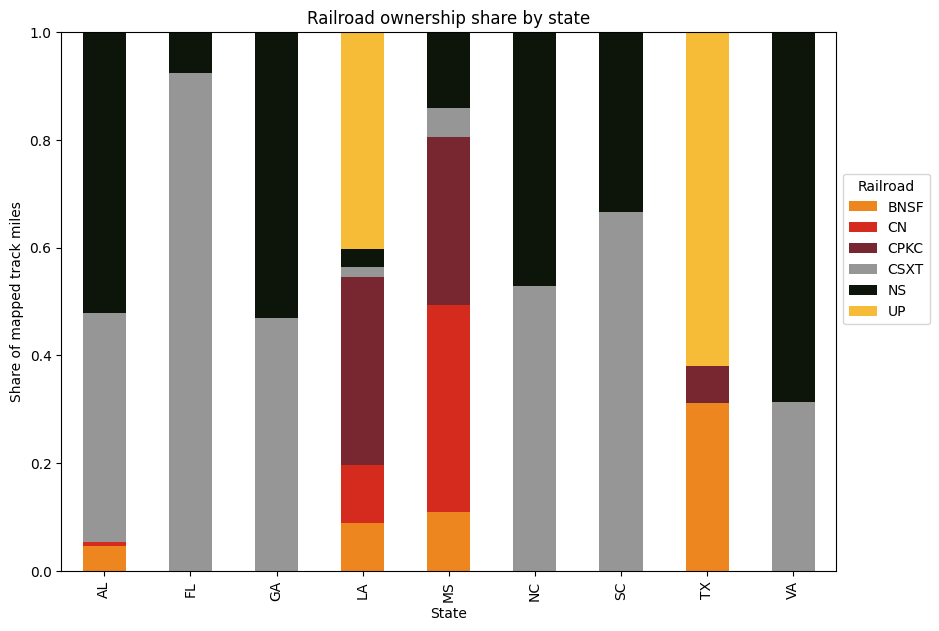

In [ ]:
#%Bar Chart
plot_data.div(plot_data.sum(axis=1), axis=0).plot(kind='bar',stacked=True,color=colors, figsize=(10,7))

plt.ylabel('Share of mapped track miles')
plt.ylim(0, 1)
plt.xlabel('State')
plt.title('Railroad ownership share by state')
plt.legend(title='Railroad', bbox_to_anchor=(1, 0.75))
plt.show()

**Takeaway:** Normalizing each state's mapped track mileage reveals the relative share associated with each operator. This helps compare coordination needs within states; it does not indicate the probability of track damage or disruption.

**Limitation:** Rail-yard ownership and some network infrastructure are not fully captured by the segment data.


## 6. Integrated Rail–Truck Optimization

The following steps follow Julian's original processing sequence: population eligibility → intermodal/QGIS merge → rail-network preparation → bird's-eye distances → trucking-data preparation → main route optimization → optional single-hub sensitivity. Section 3 summarizes the core cleaning for the broader analysis; Section 6 retains the executable modeling pipeline needed to reproduce Julian's transportation results. **Do not treat the two independently defined `opt_route` functions as interchangeable.**


In [ ]:
from pathlib import Path
import zipfile

JULIAN_FOLDER_URL = "https://drive.google.com/drive/folders/1-oxozRTcCUi_9fZU2rn63qkyjGqpIQfk?usp=sharing"
JULIAN_ROOT = Path("/content/julian_submission" if Path("/content").exists() else "./julian_submission").resolve()
JULIAN_ROOT.mkdir(parents=True, exist_ok=True)

try:
    import gdown
except ImportError:
    %pip -q install gdown
    import gdown

# Include all source workbooks required by Julian's analysis and route plotting
required = ["Population.xlsx", "Intermodal.xlsx", "Rail_Network.xlsx", "Top4of5_Trucking.xlsx", "CapeCoral_NewOrleans.xlsx", "Mapping/Facilities.xlsx", "Mapping/Segment Locs.xlsx", "Top Impact Optimization.xlsx", "Master Track Sheet.xlsx"]

def _find_file(name):
    hits = [p for p in JULIAN_ROOT.rglob(name) if "__MACOSX" not in p.parts and "generated" not in p.parts]
    return hits[0] if hits else None

if any(_find_file(Path(p).name) is None for p in required):
    try:
        gdown.download_folder(url=JULIAN_FOLDER_URL, output=str(JULIAN_ROOT), quiet=False, remaining_ok=True)
    except Exception as exc:
        print("Drive folder download could not complete:", exc)

if any(_find_file(Path(p).name) is None for p in required):
    from google.colab import files
    print("Required workbooks are missing. Upload Final Files for Submission.zip or another ZIP containing the missing files.")
    uploaded = files.upload()
    zip_name = next((k for k in uploaded if k.lower().endswith(".zip")), None)
    if zip_name is None:
        raise FileNotFoundError("Required input workbooks are missing; upload the source ZIP.")
    with zipfile.ZipFile(zip_name) as archive:
        for item in archive.infolist():
            if not item.is_dir() and not item.filename.startswith(("__MACOSX/", ".")):
                archive.extract(item, JULIAN_ROOT)

# Resolve source filenames regardless of folder nesting
def julian_file(name):
    target = Path(name)
    direct = JULIAN_ROOT / target
    if direct.is_file():
        return str(direct)
    matches = [p for p in JULIAN_ROOT.rglob(target.name) if p.is_file() and "__MACOSX" not in p.parts and "generated" not in p.parts]
    if not matches:
        raise FileNotFoundError(f"Julian input missing: {name}; check shared folder or uploaded ZIP.")
    if len(matches) > 1:
        exact = [p for p in matches if p.as_posix().endswith(str(target).replace("\\", "/"))]
        if len(exact) != 1:
            raise ValueError(f"Ambiguous source filename {name}: {matches}")
        return str(exact[0])
    return str(matches[0])

# Keep generated outputs separate from original source files
JULIAN_OUTPUT = JULIAN_ROOT / "generated"
JULIAN_OUTPUT.mkdir(exist_ok=True)

def julian_output(name):
    return str(JULIAN_OUTPUT / Path(name).name)

def julian_generated_or_source(name):
    generated = JULIAN_OUTPUT / Path(name).name
    return str(generated) if generated.exists() else julian_file(name)

# Confirm which files are available
print("Julian source directory:", JULIAN_ROOT)
print("Found required inputs:", sum(_find_file(Path(p).name) is not None for p in required), "/", len(required))
print("Missing files:", [p for p in required if _find_file(Path(p).name) is None])


Retrieving folder contents


Retrieving folder 1315JvrYviWeiybnnD307jQP5We1kXcPN Mapping
Retrieving folder 1IEKt0tXhtjtqtp8iB8JqtpCzabV044Ow NTAD_Intermodal_Freight_Facilities_Rail_TOFC_COFC_-4998192062626080357
Processing file 1yYfmBknR_MkQhkumJuqb41YjEqxksw7i Intermodal_Freight_Facilities_Rail_TOFC_COFC.cpg
Processing file 1BaXRkxNgmJBeuGEtM9-yDuZjfTnpOZTP Intermodal_Freight_Facilities_Rail_TOFC_COFC.dbf
Processing file 1Zw-_f5J75KCDTJVFKjokvpGA7F4gbunL Intermodal_Freight_Facilities_Rail_TOFC_COFC.prj
Processing file 12r7T0IEiWy97ojJ3sMaFtrr36atfC20X Intermodal_Freight_Facilities_Rail_TOFC_COFC.shp
Processing file 1aadi9-ROlKYWnFEMsQjQTxxsx91TWscW Intermodal_Freight_Facilities_Rail_TOFC_COFC.shp.xml
Processing file 1BgAUTHCb80GA_47VEfueCzIS7E80MePM Intermodal_Freight_Facilities_Rail_TOFC_COFC.shx
Retrieving folder 10O5lgMpYhzOAA9S1Wb6UzVRFbnXCmbWz NTAD_North_American_Rail_Network_Lines_Class_I_Railroads_-7451788436851299783
Processing file 1kF4xXTJBq0NWjQUiAAGNGunLZar4t9FM North_American_Rail_Network_Lines.cpg
P

Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1yYfmBknR_MkQhkumJuqb41YjEqxksw7i
To: /content/julian_submission/Mapping/NTAD_Intermodal_Freight_Facilities_Rail_TOFC_COFC_-4998192062626080357/Intermodal_Freight_Facilities_Rail_TOFC_COFC.cpg
100%|██████████| 5.00/5.00 [00:00<00:00, 8.84kB/s]
Downloading...
From: https://drive.google.com/uc?id=1BaXRkxNgmJBeuGEtM9-yDuZjfTnpOZTP
To: /content/julian_submission/Mapping/NTAD_Intermodal_Freight_Facilities_Rail_TOFC_COFC_-4998192062626080357/Intermodal_Freight_Facilities_Rail_TOFC_COFC.dbf
100%|██████████| 622k/622k [00:00<00:00, 80.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Zw-_f5J75KCDTJVFKjokvpGA7F4gbunL
To: /content/julian_submission/Mapping/NTAD_Intermodal_Freight_Facilities_Rail_TOFC_COFC_-4998192062626080357/Intermodal_Freight_Facilities_Rail_TOFC_COFC.prj
100%|██████████| 147/147 [00:00<00:00, 236kB/s]
Downloadin

Drive folder download could not complete: Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to change
	the permission to 'Anyone with the link', or have had many accesses.
	Check FAQ in https://github.com/wkentaro/gdown?tab=readme-ov-file#faq.

You may still be able to access the file from the browser:

	https://drive.google.com/uc?id=1ygxbHP1NbJexFFeYP2XcN3OKnebZZ4N3

but Gdown can't. Please check connections and permissions.
Required workbooks are missing. Upload Final Files for Submission.zip or another ZIP containing the missing files.


### 6.1 Population eligibility screening

Cleaning the population data and creating a new xlsx workbook of cities who are eligiable to give aid (population >= 500,000) and cities eligabile to get relief (population >= 100,000 & in the 9 affected states).


In [ ]:
#Read in out Population Excel file
population = pd.read_excel(julian_file('Population.xlsx'))

#Create a copy of the dataframe that we will work in. Preserve the old. Slice value is so that we eliminate the notes below the data.
filter_pop = pd.DataFrame(population[:1959])

#Split the Location column into city name and state (based on ,)
filter_pop[['City', 'State']] = filter_pop['Location'].str.split(',', expand=True)
filter_pop['City'] = filter_pop['City'].str.strip()
filter_pop['State'] = filter_pop['State'].str.strip()

#Remove columns we will not need
#Dropping the generated ID (which was just a row number + 1), Base 2020 population estimate, Location, and Census from 2020-2024
filter_pop = filter_pop.drop(filter_pop.columns[0:8], axis=1)

#Clean up the population to be int not float
filter_pop[2025] = filter_pop[2025].astype(int)

#Change state names to codes as to match other sets
state_abrv = {
    'Alabama': 'AL', 'Alaska': 'AK', 'Arizona': 'AZ', 'Arkansas': 'AR', 'California': 'CA', 'Colorado': 'CO', 'Connecticut': 'CT', 'Delaware': 'DE',
    'Florida': 'FL', 'Georgia': 'GA', 'Hawaii': 'HI', 'Idaho': 'ID', 'Illinois': 'IL', 'Indiana': 'IN', 'Iowa': 'IA', 'Kansas': 'KS', 'Kentucky': 'KY',
    'Louisiana': 'LA', 'Maine': 'ME', 'Maryland': 'MD', 'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN', 'Mississippi': 'MS',
    'Missouri': 'MO', 'Montana': 'MT', 'Nebraska': 'NE', 'Nevada': 'NV', 'New Hampshire': 'NH', 'New Jersey': 'NJ', 'New Mexico': 'NM',
    'New York': 'NY', 'North Carolina': 'NC', 'North Dakota': 'ND', 'Ohio': 'OH', 'Oklahoma': 'OK', 'Oregon': 'OR', 'Pennsylvania': 'PA',
    'Rhode Island': 'RI', 'South Carolina': 'SC', 'South Dakota': 'SD', 'Tennessee': 'TN', 'Texas': 'TX', 'Utah': 'UT', 'Vermont': 'VT',
    'Virginia': 'VA', 'Washington': 'WA', 'West Virginia': 'WV', 'Wisconsin': 'WI', 'Wyoming': 'WY', 'District of Columbia': 'DC'}

filter_pop['State'] = filter_pop['State'].map(state_abrv)

#Remove city from the City column except for New York, Oklahoma City, Kansas City both MO & KS, Salt Lake City, Jersey City
keep_city_city = ['New York City', 'Oklahoma City', 'Kansas City', 'Salt Lake City', 'Jersey City']

filter_pop['City'] = filter_pop['City'].str.title()
for index, row in filter_pop.iterrows():
    if row['City'] not in keep_city_city:
        filter_pop.at[index, 'City'] = row['City'].replace('City', "")

#Rename 2025 to be more readable
filter_pop = filter_pop.rename(columns={2025 : 'Census 2025'})

#Create a column denoting relief eligable city if >=100k population & in our 9 hurricane risk states
nine_risk_states = ['VA', 'NC', 'SC', 'GA', 'FL', 'AL', 'MS', 'LA', 'TX']
filter_pop['Receive Relief'] = None

for index, row in filter_pop.iterrows():
    if row['State'] in nine_risk_states and row['Census 2025'] >= 100000:
        filter_pop.at[index, 'Receive Relief'] = True
    else:
        filter_pop.at[index, 'Receive Relief'] = False

#Create a column denoting cities who have the capacity to give aid based on population >=500k
filter_pop['Give Aid'] = None

for index, row in filter_pop.iterrows():
    if row['Census 2025'] >= 500000:
        filter_pop.at[index, 'Give Aid'] = True
    else:
        filter_pop.at[index, 'Give Aid'] = False

#We don't need any cities that can't give or receive aid & clean column names
filter_pop = filter_pop[(filter_pop['Receive Relief'] != False) | (filter_pop['Give Aid'] != False)]
filter_pop.columns = filter_pop.columns.str.strip()

#Ensure there are no duplicates
doubles = filter_pop[filter_pop.duplicated(keep=False)]
if doubles.empty:
    print('Duplicate check passed: No doubles')
else:
    print(f'WARNING: {len(doubles)} DUPLICATE ROWS | {len(filter_pop[filter_pop.duplicated(keep='first')])} DUPLICATE RECORDS')

#Correct datatypes
filter_pop['Receive Relief'] = filter_pop['Receive Relief'].astype(bool)
filter_pop['Give Aid'] = filter_pop['Give Aid'].astype(bool)

#City needs .strip
filter_pop['City'] = filter_pop['City'].str.strip()

#Rename cities with extra info
for name in ['Indianapolis', 'Nashville', 'Louisville', 'Augusta', 'Athens']:
    filter_pop.loc[filter_pop['City'].str.startswith(name), 'City'] = name

#Save this to a new xlsx file
filter_pop.to_excel(julian_output('Eligible Locations.xlsx'), index=False, sheet_name='Possible Aid Network')

Duplicate check passed: No doubles


### 6.2 Intermodal terminal and QGIS distance merge


Rail segments do not connect directly to the intermodal facilities, as yard data is often sparce or incomplete. I used QGIS to create a data set of matches between facilities, and the closest rail segment to them, with the distance measured in meters. Refer to "Centroid to Hub Min.xlsx". I also gathered the longitude and latitude of the center points of each segment, as that later would be needed to ensure train routes did not enter the rail exclusion zone (definded by the radius input in the optimization function).

This section will serve as the merging and cleaning of all files related to intermodal facilities, their distances from the main tracks, and if each facility resides in a city in which it is qualified to give aid. It also serves as the cleaning from these merges, too. First, I merged the intermodal facility data and the QGIS data. This will aid in finding which intermodals can be used via rail in the optimization, and calculate the time spent in yards. Then I cleaned from that merge. Finally, merge the Eligible Locations set in order to get Give Aid cities. I cleaned up after the merge & save to a new file.


In [ ]:
#Read in files of intermodal facility data and QGIS distances
intermodal = pd.read_excel(julian_file('Intermodal.xlsx'))
qgis_centroid_dist = pd.read_excel(julian_file('Mapping/Facilities.xlsx'))

#Create a new DataFrame that includes our desired variables from each file
nearest_neighbour_seg = pd.merge(intermodal, qgis_centroid_dist, left_on='TERM_ADDRESS', right_on='InputID', how='left')
nearest_neighbour_seg = nearest_neighbour_seg.drop(columns='InputID')

#Check that DataFrame info is as expected
print(nearest_neighbour_seg.info()) #We have 2 more rows than we started with

#Drop the duplicates
nearest_neighbour_seg = nearest_neighbour_seg.drop_duplicates(subset=['TERM_ADDRESS', 'Distance'])

#Drop OBJECTID column as we do not need it
nearest_neighbour_seg = nearest_neighbour_seg.drop(columns=['OBJECTID','x', 'y'])

#Correct/Standardize column name formatting & remane to be descriptive
nearest_neighbour_seg.columns = nearest_neighbour_seg.columns.str.title().where((nearest_neighbour_seg.columns != 'SPLC') & (nearest_neighbour_seg.columns != 'Nearest_FRAARCID'), nearest_neighbour_seg.columns)
nearest_neighbour_seg = nearest_neighbour_seg.rename(columns={'Targetid' : 'Nearest_FRAARCID',
                                                              'Lat' : 'Latitude', 'Lon' : 'Longitude'})
nearest_neighbour_seg.columns = nearest_neighbour_seg.columns.str.strip()

#Fix incorrect datatypes
nearest_neighbour_seg['Zip_Code'] = nearest_neighbour_seg['Zip_Code'].astype(str)
nearest_neighbour_seg['SPLC'] = nearest_neighbour_seg['SPLC'].astype(str)
nearest_neighbour_seg['Nearest_FRAARCID'] = nearest_neighbour_seg['Nearest_FRAARCID'].astype(str)

#Make columns for equiptment type
nearest_neighbour_seg['TOFC'] = None
nearest_neighbour_seg['COFC'] = None

for index, row in nearest_neighbour_seg.iterrows():
    if 'TOFC' in row['Equipment']:
        nearest_neighbour_seg.at[index, 'TOFC'] = 'Yes'
    else:
        nearest_neighbour_seg.at[index, 'TOFC'] = 'No'
    if 'COFC' in row['Equipment']:
        nearest_neighbour_seg.at[index, 'COFC'] = 'Yes'
    else:
        nearest_neighbour_seg.at[index, 'COFC'] = 'No'

nearest_neighbour_seg['TOFC'] = nearest_neighbour_seg['TOFC'].astype(str)
nearest_neighbour_seg['COFC'] = nearest_neighbour_seg['COFC'].astype(str)

#Drop the old Equipment column
nearest_neighbour_seg = nearest_neighbour_seg.drop(columns='Equipment')

#Reorder to make it easy on the eye to spot the most critical variables
cols_at_front = ['Term_Address', 'Nearest_FRAARCID', 'Distance', 'Terminal', 'Latitude', 'Longitude']
other_cols = [columns for columns in nearest_neighbour_seg if columns not in cols_at_front]

nearest_neighbour_seg = nearest_neighbour_seg[cols_at_front + other_cols]

#Read in the Eligible Locations data set
give_aid = pd.read_excel(julian_generated_or_source('Eligible Locations.xlsx'))
give_aid['City'] = give_aid['City'].str.strip()

#Merge info on what cities can give aid and drop columns that are not needed
Intermodal_Final = nearest_neighbour_seg.merge(give_aid, on=['City', 'State'], how='left', suffixes=('', '_Location'))

#Drop columns we do not need
Intermodal_Final = Intermodal_Final.drop(columns=['Census 2025', 'Receive Relief'])

#Clean the Give Aid column
Intermodal_Final['Give Aid'] = Intermodal_Final['Give Aid'].fillna(0)
Intermodal_Final['Give Aid'] = Intermodal_Final['Give Aid'].replace(1, 'Yes')
Intermodal_Final['Give Aid'] = Intermodal_Final['Give Aid'].replace(0, 'No')
Intermodal_Final['Give Aid'] = Intermodal_Final['Give Aid'].astype(str)

print(Intermodal_Final.info())
#Save to a new xlsx file
Intermodal_Final.to_excel(julian_output('Merged & Cleaned Intermodal Dists.xlsx'), index=False, sheet_name='Dist')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 243 entries, 0 to 242
Data columns (total 18 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   OBJECTID      243 non-null    int64  
 1   TERMINAL      243 non-null    object 
 2   TERM_ADDRESS  243 non-null    object 
 3   CITY          243 non-null    object 
 4   STATE         243 non-null    object 
 5   ZIP_CODE      243 non-null    int64  
 6   PORT          105 non-null    object 
 7   RAIL_CO       243 non-null    object 
 8   EQUIPMENT     243 non-null    object 
 9   ACCESS_RD     66 non-null     object 
 10  SPLC          243 non-null    int64  
 11  LAT           243 non-null    float64
 12  LON           243 non-null    float64
 13  x             243 non-null    float64
 14  y             243 non-null    float64
 15  fid           243 non-null    int64  
 16  TargetID      243 non-null    int64  
 17  Distance      243 non-null    float64
dtypes: float64(5), int64(5), objec

### 6.3 Rail network and segment preparation

This section will serve to create a master data set for all information related to rail, QGIS, and the intermodal facility information prepared above. THe following sections will walk through the merges, cleaning, and filtering for allowed tracks. After reading in files, in the tracks data, ensure only American track segments are left. Ensure abandonded and out of service tracks are not included. Merge the cleaned intermodal facility data to the tracks data, so that segments that connect to the facilities are noted with the facility name and distance to it. Merge will be on FRAARCID. Clean the newly merged master data set. Save to new master file.

In [ ]:
#Read in files
tracks = pd.read_excel(julian_file('Rail_Network.xlsx'))
intermodal = pd.read_excel(julian_generated_or_source('Merged & Cleaned Intermodal Dists.xlsx'))
segment_locs = pd.read_excel(julian_file('Mapping/Segment Locs.xlsx'))

#Remove non-american soil tracks then drop COUNTRY as it is no longer needed
tracks = tracks[tracks['COUNTRY'] == 'US']
tracks = tracks.drop(columns='COUNTRY')

#Remove track segments that are abandoned or out of service
tracks = tracks[(tracks['NET'] != 'A') & (tracks['NET'] != 'R') & (tracks['NET'] != 'X')]

#Remove track segments that are tourist, museum, scenic passenger service, VIA, and Ontario Northland
tracks = tracks[(tracks['PASSNGR'] != 'T') & (tracks['PASSNGR'] != 'O') & (tracks['PASSNGR'] != 'V')]

#Denote columns with _T as from tracks and _I as from intermodal so that we can easily differentiate later
tracks.columns = tracks.columns + '_T'
intermodal.columns = intermodal.columns + '_I'

#Merge on FRACCRID
merged = tracks.merge(intermodal, left_on='FRAARCID_T', right_on='Nearest_FRAARCID_I', how='left')
merged = merged.drop(columns='Nearest_FRAARCID_I')

#Make columns the same format
merged.columns = merged.columns.str.upper()

#Verify that we have all the important IDs for each segment
print('Missing Object IDs:', merged['OBJECTID_T'].isna().sum()) #0 Missing
print('Missing Object IDs:', merged['FRAARCID_T'].isna().sum()) #0 Missing
print('Missing Object IDs:', merged['FRFRANODE_T'].isna().sum()) #0 Missing
print('Missing Object IDs:', merged['TOFRANODE_T'].isna().sum()) #0 Missing

#Fix data types
change_to_str = ['OBJECTID_T', 'FRAARCID_T', 'FRFRANODE_T', 'TOFRANODE_T', 'CNTYFIPS_T', 'STCNTYFIPS_T', 'FRADISTRCT_T', 'ZIP_CODE_I', 'SPLC_I']
merged[change_to_str] = merged[change_to_str].astype(str)

merged['TRACKS_T'] = merged['TRACKS_T'].astype('Int64')

#Now merge the QGIS track segment location data (and convert column used for right_on to str first)
segment_locs['FRAARCID'] = segment_locs['FRAARCID'].astype(str)
merged = merged.merge(segment_locs[['FRAARCID', 'Longitude', 'Latitude']], how='left', left_on='FRAARCID_T', right_on='FRAARCID')

#Rename those columns and drop FRAARCID
merged = merged.rename(columns={'Longitude' : 'LNG_T', 'Latitude' : 'LAT_T'})
merged = merged.drop(columns='FRAARCID')

print(merged.info()) #Check the changes were made | Note: The one less intermodal match is due to the Alaskan one that does not link up to our allowed track

#Save this file to be used as the master
merged.to_excel(julian_output('Master Track Sheet.xlsx'), sheet_name='Master Data', index=False)

Missing Object IDs: 0
Missing Object IDs: 0
Missing Object IDs: 0
Missing Object IDs: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72996 entries, 0 to 72995
Data columns (total 51 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OBJECTID_T       72996 non-null  object 
 1   FRAARCID_T       72996 non-null  object 
 2   FRFRANODE_T      72996 non-null  object 
 3   TOFRANODE_T      72996 non-null  object 
 4   STFIPS_T         72996 non-null  object 
 5   CNTYFIPS_T       72996 non-null  object 
 6   STCNTYFIPS_T     72996 non-null  object 
 7   STATEAB_T        72996 non-null  object 
 8   FRADISTRCT_T     72996 non-null  object 
 9   RROWNER1_T       72996 non-null  object 
 10  RROWNER2_T       1741 non-null   object 
 11  RROWNER3_T       13 non-null     object 
 12  TRKRGHTS1_T      33929 non-null  object 
 13  TRKRGHTS2_T      10862 non-null  object 
 14  TRKRGHTS3_T      2775 non-null   object 
 15  TRKRGHTS4_T     

### 6.4 Bird’s-eye relief-city distances

This section serves to make bird's eye distances from the affected cities to intermodal hubs. This will be used in the optimization model to determine legal freight transfer points, and specifically identify the closest safe points. We use data of US cities and their coordinates to calculate the distance from cities in need of aid to intermodal facilities using the haversine distance formula. This is then saved to its own file which will be called on in the optimization model later.

In [ ]:
#import math

#Read in data
el_cities = pd.read_excel(julian_generated_or_source('Eligible Locations.xlsx'))
hubs = pd.read_excel(julian_file('Intermodal.xlsx'))
all_US_city_data = pd.read_excel(julian_file('US Cities.xlsx'))

#Filter cities to relief cities
rel_cities = el_cities[el_cities['Receive Relief'] == True]

#Merge the all_US_city_data with the rel_cities so that we get coordinates of rel_cities
loc_rel_cities = rel_cities.merge(all_US_city_data[['city', 'state_id', 'lat', 'lng']], how='left', left_on=['City', 'State'], right_on=['city', 'state_id'])

#Function for distance
def haversine_distance(lat1, lon1, lat2, lon2):
    earth_radius_miles = 3958.8

    lat1 = math.radians(lat1)
    lon1 = math.radians(lon1)
    lat2 = math.radians(lat2)
    lon2 = math.radians(lon2)

    lat_difference = lat2 - lat1
    lon_difference = lon2 - lon1

    a = ( math.sin(lat_difference / 2) ** 2 + math.cos(lat1) * math.cos(lat2) * math.sin(lon_difference / 2) ** 2 )

    c = 2 * math.atan2( math.sqrt(a), math.sqrt(1 - a) )

    return earth_radius_miles * c

# Store the distance results
distance_results = []

# Calculate the distance from each supply hub to each affected city
for index, hub in hubs.iterrows():

    for index, affected_city in loc_rel_cities.iterrows():

        # Skip comparisons where the supply hub and affected city are the same place
        if (hub['CITY'] == affected_city['City'] and hub['STATE'] == affected_city['State']):
            continue

        distance = haversine_distance(hub['LAT'], hub['LON'], affected_city['lat'], affected_city['lng'])

        distance_results.append({ 'Hub Address' : hub['TERM_ADDRESS'], 'Hub' : hub['CITY'], 'Hub State' : hub['STATE'],
            'Affected City' : affected_city['City'], 'Affected City State' : affected_city['State'],
            'Affected City Population 2025' : affected_city['Census 2025'],
            'Affected City Latitude' : affected_city['lat'],
            'Affected City Longitude' : affected_city['lng'], "Bird's-Eye Distance (mi)" : distance})

# Create the final distance dataset
be_distances = pd.DataFrame(distance_results)

# Sort by affected city and bird's-eye distance
be_distances = be_distances.sort_values(["Affected City", "Bird's-Eye Distance (mi)"]).reset_index(drop=True)

#Save to a file
be_distances.to_excel(julian_output("Bird's Eye.xlsx"), sheet_name='BEV', index=False)

be_distances.info()
print(be_distances.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26224 entries, 0 to 26223
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Hub Address                    26224 non-null  object 
 1   Hub                            26224 non-null  object 
 2   Hub State                      26224 non-null  object 
 3   Affected City                  26224 non-null  object 
 4   Affected City State            26224 non-null  object 
 5   Affected City Population 2025  26224 non-null  int64  
 6   Affected City Latitude         24778 non-null  float64
 7   Affected City Longitude        24778 non-null  float64
 8   Bird's-Eye Distance (mi)       24778 non-null  float64
dtypes: float64(3), int64(1), object(5)
memory usage: 1.8+ MB
                   Hub Address       Hub Hub State Affected City  \
0      1111 Intermodal Parkway    Haslet        TX       Abilene   
1     3701 South Interstate 45    

### 6.5 Trucking route preparation

This section serves to clean the data from our truck API. There were 2 sheets returned, so they need to be concatenated as well. The resulting file will also be called on in the optimization model.

In [ ]:
#Read in the trucking files
trucking_4_5 = pd.read_excel(julian_file('Top4of5_Trucking.xlsx'))
trucking_edit_and_NO = pd.read_excel(julian_file('CapeCoral_NewOrleans.xlsx'))

#Concatenate the DataFrames
trucking = pd.concat([trucking_4_5, trucking_edit_and_NO])

#Keep only the columns that are needed for the optimization function
trucking =trucking[['hub_city', 'hub_state', 'hub_address', 'destination', 'distance_km', 'duration_hours']]

#Convert distance into miles and drop the km column
trucking['Truck Mileage'] = trucking['distance_km'] / 1.609344
trucking = trucking.drop(columns='distance_km')

#Get destination into city and state columns
trucking['Affected City'] = trucking['destination'].str.split(',', expand= True)[0]
trucking['Affected State'] = trucking['destination'].str.split(',', expand= True)[1]

trucking['Affected City'] = trucking['Affected City'].str.strip()
trucking['Affected State'] = trucking['Affected State'].str.strip()

trucking = trucking.drop(columns='destination')

#Fix Palm Beach to West Palm Beach
for index, row in trucking.iterrows():
    if row['Affected City'] == 'Palm Beach':
        trucking.loc[index, 'Affected City'] = 'West Palm Beach'

#No need for Pearland, TX
trucking = trucking[trucking['Affected City'] != 'Pearland']

trucking.to_excel(julian_output('Truck Clean.xlsx'), sheet_name= 'Routes', index= False)

### 6.6 Rail–truck routing optimization

**Full computational run.** This cell executes Julian's original multi-destination optimization and writes a separate results workbook. It may take several minutes. Do not rerun it when only editing charts or narrative; use the previously generated workbook where appropriate. The modeling code and scenario parameters are preserved.


In [ ]:
# Read in data sets
rail_network = pd.read_excel(julian_generated_or_source('Master Track Sheet.xlsx'))
be_dist = pd.read_excel(julian_generated_or_source("Bird's Eye.xlsx"))
trucking = pd.read_excel(julian_generated_or_source('Truck Clean.xlsx'))

#Intermodal hub to nearest segment distances need to be converted from meters to miles
rail_network['DISTANCE_I'] = rail_network['DISTANCE_I'] / 1609.344

#Ensure terminal address's are str not numeric
rail_network['TERM_ADDRESS_I'] = rail_network['TERM_ADDRESS_I'].astype(str)
be_dist['Hub Address'] = be_dist['Hub Address'].astype(str)

#Optimization function
def opt_route(city, state, radius, rail_df, birds_eye_df, trucking_df, region):

    '''
    This function takes in the affected city, affected state, radius of when the strom drops below 39mph wins (tracks likely unharmed),
    rail data, bird's eye distance between city and hub options data, trucking data, and projected regions the storm will hit
    (Atlantic coast as AC, Gulf coast as GC, Both as B). It will look to find an optimized intermodal shipping route.
    '''

    #Copy DataFrames and use those for manipulation
    rail = rail_df.copy()
    birds_eye = birds_eye_df.copy()
    trucking = trucking_df.copy()

    #Get the list of legal supply hub states
    lower_48 = states_48 = ['AL', 'AZ', 'AR', 'CA', 'CO', 'CT', 'DE', 'FL', 'GA', 'ID', 'IL', 'IN', 'IA', 'KS', 'KY', 'LA', 'ME', 'MD', 'MA', 'MI', 'MN', 'MS', 'MO', 'MT', 'NE', 'NV', 'NH', 'NJ', 'NM', 'NY', 'NC', 'ND', 'OH', 'OK', 'OR', 'PA', 'RI', 'SC', 'SD', 'TN', 'TX', 'UT', 'VT', 'VA', 'WA', 'WV', 'WI', 'WY']
    atlantic_risk = ['FL', 'GA', 'SC', 'NC', 'VA']
    gulf_risk = ['FL', 'MS', 'AL', 'LA', 'TX']
    if region == 'AC':
        possible_supply_states = [st for st in lower_48 if st not in atlantic_risk]
    elif region == 'GC':
        possible_supply_states = [st for st in lower_48 if st not in gulf_risk]
    elif region == 'B':
        possible_supply_states = [st for st in lower_48 if st not in atlantic_risk and st not in gulf_risk]
    else:
        return 'Error: Invalid region input'

    #Find the 3 nearest hubs outside the exculded radius from the city
    eligible_hubs = birds_eye[(birds_eye['Affected City'] == city) & (birds_eye['Affected City State'] == state) & (birds_eye["Bird's-Eye Distance (mi)"] >= radius)].sort_values(by="Bird's-Eye Distance (mi)").head(3)

    #Get the terminal information from those 3
    option_end_terminals = rail[rail['TERM_ADDRESS_I'].isin(eligible_hubs['Hub Address'])]

    #Find the end nodes at the terminals
    end_nodes_top3 = []
    ends = option_end_terminals['TOFRANODE_T']

    for i in ends:
        end_nodes_top3.append(i)

    #Find the relief city's latitude and longitude
    city_info = birds_eye[(birds_eye['Affected City'] == city) & (birds_eye['Affected City State'] == state)].iloc[0]

    city_lat = city_info['Affected City Latitude']
    city_lng = city_info['Affected City Longitude']

    #This function will calculate the distance from the affected city to each rail segment using the Haversine distance formula (same idea as in the bird's eye calculations file)
    def calculate_distance(track, city_lat, city_lng):

        earth_radius_miles = 3958.8

        lat1 = math.radians(city_lat)
        lon1 = math.radians(city_lng)
        lat2 = math.radians(track['LAT_T'])
        lon2 = math.radians(track['LNG_T'])

        lat_difference = lat2 - lat1
        lon_difference = lon2 - lon1

        a = (
            math.sin(lat_difference / 2) ** 2
            + math.cos(lat1)
            * math.cos(lat2)
            * math.sin(lon_difference / 2) ** 2
        )

        c = 2 * math.atan2(
            math.sqrt(a),
            math.sqrt(1 - a)
        )

        return earth_radius_miles * c

    #Make a new column in the rail DataFrame to store the distance each track segment is from the city
    #Calculate all segment distances at once instead of updating the DataFrame row by row
    lat1, lon1 = np.radians(city_lat), np.radians(city_lng)
    lat2 = np.radians(rail['LAT_T'].to_numpy(dtype=float))
    lon2 = np.radians(rail['LNG_T'].to_numpy(dtype=float))
    a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    rail['Distance from City (mi)'] = 3958.8 * 2 * np.arctan2(np.sqrt(a), np.sqrt(1-a))

    #Filter the rail segments to ones outside the storm zone
    rail = rail[rail['Distance from City (mi)'] >= radius]

    #Find legal supply starts
    supply_starts = rail[(rail['GIVE AID_I'] == 'Yes') & (rail['STATE_I'].isin(possible_supply_states))]
    start_id = supply_starts['FRFRANODE_T']

    starts = []

    for id in start_id:
        starts.append(id)

    #Create the rail network graph
    network = nx.Graph()

    for start_node, end_node, miles in rail[['FRFRANODE_T', 'TOFRANODE_T', 'MILES_T']].itertuples(index=False, name=None):
        network.add_edge(start_node, end_node, weight=miles)

    #Storage for possible routes
    routes = []

    #Find the shortest rail route from each supply hub to the options of intermodal facilities
    for start in starts:
        for end in end_nodes_top3:

            #Find the optimal route of track segments based on the shortest mileage
            miles, route = nx.single_source_dijkstra(network, source=start, target=end, weight='weight')

            routes.append({'Start': start, 'End': end, 'Route': route, 'Track Mileage': miles})

    #Find intermodal facilities
    intermodals = rail[rail['TERM_ADDRESS_I'].notna()]

    #Keep the last matching yard distance for each node, as in the original loop
    yard_by_node = dict(zip(intermodals['TOFRANODE_T'], intermodals['DISTANCE_I']))

    #Calculate the total time for each route
    for route in routes:

        #Find the mileage spent in the yard
        start_yard_distance = yard_by_node.get(route['Start'], 0)
        end_yard_distance = yard_by_node.get(route['End'], 0)

        #Add the yard distance to total miles
        yard_miles = start_yard_distance + end_yard_distance
        route['Track Mileage'] += float(yard_miles)
        route['Yard'] = float(yard_miles)

        #Find the time spent on rail (given the estimated freight speed on main cooridors is 70mph and in yards is 10mph)
        route['Rail Time (hr)'] = (route['Track Mileage'] / 70) + (route['Yard'] / 10)

        # Find the destination terminal for this route
        end_terminal_info = option_end_terminals[option_end_terminals['TOFRANODE_T'] == route['End']]
        end_address = end_terminal_info['TERM_ADDRESS_I'].iloc[0]

        #Find the trucking time to the affected city from the intermodal facility
        truck_route = trucking[(trucking['hub_address'] == end_address) & (trucking['Affected City'] == city) & (trucking['Affected State'] == state)]

        #Store the trucking time and distance info
        route['Trucking Mileage'] = truck_route['Truck Mileage'].iloc[0]
        route['Trucking Time (hr)'] = truck_route['duration_hours'].iloc[0]

        #Find the total travel time (add 1 hour for the intermodal transfer)
        route['Total Time (hr)'] = (route['Rail Time (hr)'] + route['Trucking Time (hr)'] + 1)

    #Find the route with the shortest time
    min_route_info = routes[0]

    for route in routes[1:]:
        if route['Total Time (hr)'] < min_route_info['Total Time (hr)']:
            min_route_info = route

    #Count the number of track segments used
    min_route_info['Segments'] = len(min_route_info['Route'])

    #Show how many segments are being used in the route
    min_route_info['Segments'] = len(min_route_info['Route'])

    #Storage for ownership mileage values
    distance_per_owner = {'UP': 0, 'BNSF': 0, 'NS': 0, 'CN': 0, 'CSXT': 0, 'CPKC': 0}

    rr_owners = ['UP', 'BNSF', 'NS', 'CN', 'CSXT', 'CPKC']
    ownership_cols = ['RROWNER1_T', 'RROWNER2_T', 'RROWNER3_T']

    #Find the rail ownership
    min_route = min_route_info['Route']

    for start_node, end_node in zip(min_route[:-1], min_route[1:]):
        segment = rail[((rail['FRFRANODE_T'] == start_node) & (rail['TOFRANODE_T'] == end_node)) | ((rail['FRFRANODE_T'] == end_node) & (rail['TOFRANODE_T'] == start_node))].iloc[0]

        for rr in rr_owners:
            if rr in segment[ownership_cols].values:
                distance_per_owner[rr] += float(segment['MILES_T'])

    #Find destination hub information
    end_terminal_info = option_end_terminals[
    option_end_terminals['TOFRANODE_T'] == min_route_info['End']].iloc[0]

    min_route_info['Trucking Start Terminal Address'] = str(end_terminal_info['TERM_ADDRESS_I']) + ', ' + str(end_terminal_info['CITY_I']) + ', ' + str(end_terminal_info['STATE_I'])
    min_route_info['TOFC'] = end_terminal_info['TOFC_I']
    min_route_info['COFC'] = end_terminal_info['COFC_I']

    #Get that same info for the supply hub
    start = min_route_info['Start']
    start_terminal_info = rail[(rail['FRFRANODE_T'] == start) & (rail['TERM_ADDRESS_I'].notna())].iloc[0] #Must do both to protect against starts at areas where segments fork into eachother

    min_route_info['Rail Start Terminal Address'] = str(start_terminal_info['TERM_ADDRESS_I']) + ', ' + str(start_terminal_info['CITY_I']) + ', ' + str(start_terminal_info['STATE_I'])

    #Add the trucking information to the last leg ouf the route
    truck_route = trucking[(trucking['hub_address'] == end_terminal_info['TERM_ADDRESS_I']) & (trucking['Affected City'] == city) & (trucking['Affected State'] == state)]
    min_route_info['Trucking Mileage'] = truck_route['Truck Mileage'].iloc[0]
    min_route_info['Trucking Time (hr)'] = truck_route['duration_hours'].iloc[0]

    #Caluclate the estimated rail time based on an average of 70mph on the main line and 10mph in the yards
    min_route_info['Rail Time (hr)'] = ((min_route_info['Track Mileage'] - min_route_info['Yard']) / 70) + (min_route_info['Yard'] / 10)

    #Calculate the total transport time (adding 1 hour for the intermodal transfer)
    min_route_info['Total Time (hr)'] = min_route_info['Rail Time (hr)'] + min_route_info['Trucking Time (hr)'] + 1

    #See if a further trucking only hub is more efficient
    birds_eye_limit = birds_eye[(birds_eye['Affected City'] == city) & (birds_eye['Affected City State'] == state) & (birds_eye["Bird's-Eye Distance (mi)"] >= radius)]
    birds_eye_limit_list = []

    for index, row in birds_eye_limit.iterrows():
        birds_eye_limit_list.append(row['Hub Address'])

    legal_supply = rail_network[(rail_network['GIVE AID_I'] == 'Yes') & (rail_network['TERM_ADDRESS_I'].isin(birds_eye_limit_list)) & (rail_network['STATE_I'].isin(possible_supply_states))]
    legal_supply_checks = []
    for index, row in legal_supply.iterrows():
        legal_supply_checks.append(row['TERM_ADDRESS_I'])

    truck_options = trucking[trucking['hub_address'].isin(legal_supply_checks) & (trucking['Affected City'] == city) & (trucking['Affected State'] == state) & trucking['hub_state'].isin(possible_supply_states)]

    if not truck_options.empty:

        truck_options = truck_options.sort_values(by='duration_hours')
        quickest_truck_only_alt = truck_options.iloc[0] #Default is ascending so the first row will have the shortest time

        #If this option is faster than the rail optimizer then output the data for this route instead
        if quickest_truck_only_alt['duration_hours'] < min_route_info['Total Time (hr)']:

            #Store route info
            alt_route_info = {}

            alt_route_info['Affected City'] = city
            alt_route_info['Affected State'] = state

            alt_route_info['Rail Start Terminal Address'] = np.nan
            alt_route_info['Start Segment'] = np.nan

            alt_route_info['Trucking Start Terminal Address'] = str(quickest_truck_only_alt['hub_address']) + ', ' + str(quickest_truck_only_alt['hub_city']) + ', ' + str(quickest_truck_only_alt['hub_state'])

            alt_route_info['End Segment'] = np.nan
            alt_route_info['TOFC'] = np.nan
            alt_route_info['COFC'] = np.nan
            alt_route_info['Route'] = np.nan
            alt_route_info['Num Segments'] = np.nan
            alt_route_info['Track Mileage'] = 0
            alt_route_info['Yard Mileage'] = 0
            alt_route_info['UP'] = 0
            alt_route_info['BNSF'] = 0
            alt_route_info['NS'] = 0
            alt_route_info['CSXT'] = 0
            alt_route_info['CN'] = 0
            alt_route_info['CPKC'] = 0

            alt_route_info['Trucking Mileage'] = quickest_truck_only_alt['Truck Mileage']
            alt_route_info['Trucking Time (hr)'] = quickest_truck_only_alt['duration_hours']

            alt_route_info['Rail Time (hr)'] = 0
            alt_route_info['Total Time (hr)'] = alt_route_info['Trucking Time (hr)']

            #Add the impact region estimate and exclusion radius
            alt_route_info['Impact Region Estimate'] = region
            alt_route_info['Rail Exclusion Zone'] = radius

            #Create a DataFrame
            complete_route_info = pd.DataFrame([alt_route_info])

            #Correct data types
            complete_route_info['Rail Start Terminal Address'] = complete_route_info['Rail Start Terminal Address'].astype(str)
            complete_route_info['Start Segment'] = complete_route_info['Start Segment'].astype(str)
            complete_route_info['End Segment'] = complete_route_info['End Segment'].astype(str)
            complete_route_info['TOFC'] = complete_route_info['TOFC'].astype(str)
            complete_route_info['COFC'] = complete_route_info['COFC'].astype(str)

            return complete_route_info


    #Unpack the two dictionaries in a new one
    all_route_info = {**min_route_info, **distance_per_owner}

    #Convert that to a DataFrame
    complete_route_info = pd.DataFrame([all_route_info])

    #Add the city in need and its state to the DataFrame
    complete_route_info['Affected City'] = city
    complete_route_info['Affected State'] = state

    #Add the impact region estimate and exclusion radius
    complete_route_info['Impact Region Estimate'] = region
    complete_route_info['Rail Exclusion Zone'] = radius

    #Rename columns for readability
    complete_route_info = complete_route_info.rename(columns={'Start' : 'Start Segment',
                                                              'End' : 'End Segment',
                                                              'Segments' : 'Num Segments',
                                                              'Yard' : 'Yard Mileage'})
    #Reorder columns
    complete_route_info = complete_route_info[['Affected City',
                                               'Affected State',
                                               'Rail Start Terminal Address',
                                               'Start Segment',
                                               'Trucking Start Terminal Address',
                                               'End Segment',
                                               'TOFC',
                                               'COFC',
                                               'Route',
                                               'Num Segments',
                                               'Track Mileage',
                                               'Yard Mileage',
                                               'UP',
                                               'BNSF',
                                               'NS',
                                               'CSXT',
                                               'CN',
                                               'CPKC',
                                               'Trucking Mileage',
                                               'Trucking Time (hr)',
                                               'Rail Time (hr)',
                                               'Total Time (hr)',
                                               'Impact Region Estimate',
                                               'Rail Exclusion Zone']]

    #Fix incorrect data types
    complete_route_info['Start Segment'] = complete_route_info['Start Segment'].astype(str)
    complete_route_info['End Segment'] = complete_route_info['End Segment'].astype(str)
    complete_route_info['UP'] = complete_route_info['UP'].astype(float)
    complete_route_info['BNSF'] = complete_route_info['BNSF'].astype(float)
    complete_route_info['NS'] = complete_route_info['UP'].astype(float)
    complete_route_info['CSXT'] = complete_route_info['CSXT'].astype(float)
    complete_route_info['CN'] = complete_route_info['CN'].astype(float)
    complete_route_info['CPKC'] = complete_route_info['CPKC'].astype(float)

    #Return the DataFrame
    return complete_route_info

#Call the top 5 cities plus New Orleans (due to the impact of Katrina) based on their radius once the wind is down to 39mph, the max freight operating wind speed
wpb = (opt_route('West Palm Beach', 'FL', 83.55, rail_network, be_dist, trucking, 'B'))
br = (opt_route('Boca Raton', 'FL', 83.55, rail_network, be_dist, trucking, 'B'))
nchar = (opt_route('North Charleston', 'SC', 221.3, rail_network, be_dist, trucking, 'AC'))
char = (opt_route('Charleston', 'SC', 221.3, rail_network, be_dist, trucking, 'AC'))
cc = (opt_route('Cape Coral', 'FL', 237.5, rail_network, be_dist, trucking, 'B'))
no = (opt_route('New Orleans', 'LA', 230, rail_network, be_dist, trucking, 'GC'))

#Concatenate the DataFrames
top_impact = pd.concat([br, char, nchar, wpb, cc, no], ignore_index=True)

print(top_impact)
top_impact.info()

#Save the file
top_impact.to_excel('Top Impact Optimization.xlsx', sheet_name='Opt', index=False)

      Affected City Affected State Rail Start Terminal Address Start Segment  \
0        Boca Raton             FL               nan, nan, nan        307239   
1        Charleston             SC                         nan           nan   
2  North Charleston             SC                         nan           nan   
3   West Palm Beach             FL               nan, nan, nan        307239   
4        Cape Coral             FL               nan, nan, nan        399198   
5       New Orleans             LA                         nan           nan   

          Trucking Start Terminal Address End Segment TOFC COFC  \
0      317 Rosa L. Jones Drive, Cocoa, FL      453207   No  Yes   
1         3086 Sidco Drive, Nashville, TN         nan  nan  nan   
2         3086 Sidco Drive, Nashville, TN         nan  nan  nan   
3      317 Rosa L. Jones Drive, Cocoa, FL      453207   No  Yes   
4  2700 Talleyrand Ave., Jacksonville, FL      450398  Yes  Yes   
5     3588 Paul R.Lowry Road, Memphis

### 6.7 Submitted and regenerated optimization results

The comparison below loads the submitted workbook and, when present, the newly generated workbook. Matching row counts do not independently establish identical routes or global optimality; review destination labels, inputs, parameters, and route-time components before making that claim.


In [ ]:
# Compare supplied optimization output with a fresh run, if available.
submitted = pd.read_excel(julian_file('Top Impact Optimization.xlsx'), sheet_name='Opt')
print('Submitted optimization scenarios:', len(submitted))
display(submitted)
generated_path = JULIAN_OUTPUT / 'Top Impact Optimization.xlsx'
if generated_path.exists():
    reproduced = pd.read_excel(generated_path, sheet_name='Opt')
    print('Reproduced optimization scenarios:', len(reproduced))
    display(reproduced)
else:
    print('No regenerated optimization workbook yet; execute step 6.6 above.')

Submitted optimization scenarios: 6


,Affected City,Affected State,Rail Start Terminal Address,Start Segment,Trucking Start Terminal Address,End Segment,TOFC,COFC,Route,Num Segments,...,NS,CSXT,CN,CPKC,Trucking Mileage,Trucking Time (hr),Rail Time (hr),Total Time (hr),Impact Region Estimate,Rail Exclusion Zone
0,Boca Raton,FL,"3086 Sidco Drive, Nashville, TN",421934.0,"3935 Intermodal Drive, Winter Haven, FL",449719.0,No,Yes,"[421934, 422047, 422289, 422391, 422500, 42271...",442.0,...,0,568.603567,0,0,177.275337,4.638,11.571070,17.209070,B,83.55
1,Charleston,SC,"4800 East Lombard Street, Baltimore, MD",478883.0,"1105 Merritt Drive, Greensboro, NC",463750.0,Yes,Yes,"[478883, 478900, 478890, 478888, 478869, 47886...",299.0,...,0,50.715185,0,0,257.608690,5.992,4.735621,11.727621,AC,221.30
2,North Charleston,SC,"3086 Sidco Drive, Nashville, TN",421934.0,"173 Boulvard S.E., Atlanta, GA",433351.0,No,Yes,"[421934, 422047, 422289, 422391, 422500, 42271...",206.0,...,0,283.174358,0,0,310.162402,7.188,4.052416,12.240416,AC,221.30
3,West Palm Beach,FL,"3086 Sidco Drive, Nashville, TN",421934.0,"3935 Intermodal Drive, Winter Haven, FL",449719.0,No,Yes,"[421934, 422047, 422289, 422391, 422500, 42271...",442.0,...,0,568.603567,0,0,154.773001,3.992,11.571070,16.563070,B,83.55
4,Cape Coral,FL,"3086 Sidco Drive, Nashville, TN",421934.0,"2700 Talleyrand Ave., Jacksonville, FL",450398.0,Yes,Yes,"[421934, 422047, 422289, 422391, 422500, 42271...",337.0,...,0,377.362545,0,0,316.231334,8.268,8.900952,18.168952,B,237.50
5,New Orleans,LA,NaN,NaN,"3588 Paul R.Lowry Road, Memphis, TN",NaN,NaN,NaN,NaN,NaN,...,0,0.000000,0,0,397.891936,9.326,0.000000,9.326000,GC,230.00


No regenerated optimization workbook yet; execute step 6.6 above.


Optimization plot function:

NOTE: THIS FUNCTION WAS 100% AI GENERATED (VIA CHAT-GPT). IT IS ALSO LISTED IN THE AI DISCLOSURE UNDER JULIAN'S DISCLOSURE.

This function can be called to generate a plot which uses layers to map the outline of US states, the route of rail, the intermodal hubs, a straight line distnace for trucking (a representation, not reality) and the exclusion zone.

In [ ]:
# Import libraries
import ast
import re
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString

# 1. READ INPUT FILES
results = pd.read_excel(julian_generated_or_source('Top Impact Optimization.xlsx'))
master = pd.read_excel(julian_generated_or_source('Master Track Sheet.xlsx'))

# 2. PREPARE INTERMODAL TERMINAL DATA
intermodals = master.dropna(subset=['LATITUDE_I', 'LONGITUDE_I']).copy()
intermodals['LATITUDE_I'] = pd.to_numeric(intermodals['LATITUDE_I'], errors='coerce')
intermodals['LONGITUDE_I'] = pd.to_numeric(intermodals['LONGITUDE_I'], errors='coerce')
intermodals = intermodals.dropna(subset=['LATITUDE_I', 'LONGITUDE_I'])

# 3. LOAD U.S. STATE MAP
states = gpd.read_file('https://www2.census.gov/geo/tiger/GENZ2023/shp/cb_2023_us_state_500k.zip').to_crs('EPSG:4326')

# 4. FIND HUB COORDINATES
def find_hub(address, label):
    if pd.isna(address) or not str(address).strip():
        raise ValueError(f'{label} address is blank.')

    address = str(address).strip()
    parts = [part.strip() for part in address.split(',')]
    street = parts[0] if parts else ''
    city = parts[1] if len(parts) > 1 else ''
    state = parts[2] if len(parts) > 2 else ''

    found = intermodals[intermodals['TERM_ADDRESS_I'].astype(str).str.contains(re.escape(street), case=False, regex=True, na=False)]

    if not found.empty and city and 'CITY_I' in found.columns:
        city_matches = found[found['CITY_I'].astype(str).str.contains(re.escape(city), case=False, regex=True, na=False)]
        if not city_matches.empty:
            found = city_matches

    if not found.empty and state and 'STATE_I' in found.columns:
        state_matches = found[found['STATE_I'].astype(str).str.contains(re.escape(state), case=False, regex=True, na=False)]
        if not state_matches.empty:
            found = state_matches

    if found.empty:
        print(f'\nCould not match {label}: {address}')
        raise ValueError(f'Could not match {label}: {address}')

    if len(found) > 1:
        print(f'Multiple matches for {label}; using the first match:')
        cols = [c for c in ['TERM_ADDRESS_I', 'CITY_I', 'STATE_I'] if c in found.columns]
        print(found[cols].head(10).to_string(index=False))

    hub = found.iloc[0]
    return (float(hub['LONGITUDE_I']), float(hub['LATITUDE_I']))

# 5. MAIN PLOTTING FUNCTION
def plot_transportation_route(destination_city, destination_lat, destination_lon, save_path=None):
    matches = results[results['Affected City'].astype(str).str.strip().str.lower() == destination_city.strip().lower()]

    if matches.empty:
        raise ValueError(f'{destination_city} was not found in the results.')

    result = matches.iloc[0]
    destination = (destination_lon, destination_lat)
    radius = float(result['Rail Exclusion Zone'])

    # Find trucking terminal
    truck_address = result['Trucking Start Terminal Address']
    truck_hub = find_hub(truck_address, 'Trucking terminal')

    # Check whether a rail route exists
    rail_address = result.get('Rail Start Terminal Address')
    route_value = result.get('Route')
    has_rail = pd.notna(rail_address) and bool(str(rail_address).strip()) and pd.notna(route_value) and bool(str(route_value).strip())
    rail_line = None
    rail_mileage = 0.0

    # 6. BUILD RAIL ROUTE IF AVAILABLE
    if has_rail:
        route_nodes = ast.literal_eval(route_value) if isinstance(route_value, str) else route_value

        if not isinstance(route_nodes, (list, tuple)) or len(route_nodes) < 2:
            raise ValueError(f'Invalid rail route for {destination_city}.')

        first_hub = find_hub(rail_address, 'First rail hub')
        rail = master.dropna(subset=['FRFRANODE_T', 'TOFRANODE_T', 'LAT_T', 'LNG_T']).copy()
        rail['LAT_T'] = pd.to_numeric(rail['LAT_T'], errors='coerce')
        rail['LNG_T'] = pd.to_numeric(rail['LNG_T'], errors='coerce')
        rail = rail.dropna(subset=['LAT_T', 'LNG_T'])
        rail_points = [first_hub]
        missing_segments = []

        for start_node, end_node in zip(route_nodes[:-1], route_nodes[1:]):
            segments = rail[((rail['FRFRANODE_T'] == start_node) & (rail['TOFRANODE_T'] == end_node)) | ((rail['FRFRANODE_T'] == end_node) & (rail['TOFRANODE_T'] == start_node))]

            if segments.empty:
                missing_segments.append((start_node, end_node))
                continue

            segment = segments.iloc[0]
            point = (float(segment['LNG_T']), float(segment['LAT_T']))

            if point != rail_points[-1]:
                rail_points.append(point)

        if missing_segments:
            raise ValueError(f'Rail segments not found: {missing_segments}')

        if truck_hub != rail_points[-1]:
            rail_points.append(truck_hub)

        rail_line = LineString(rail_points)
        rail_mileage = float(result['Track Mileage'])

    # 7. BUILD TRUCKING LEG
    # Straight connector, not actual road geometry
    truck_line = LineString([truck_hub, destination])

    # 8. CREATE MAP LAYERS
    truck_hub_gdf = gpd.GeoDataFrame({'Address': [str(truck_address)]}, geometry=[Point(truck_hub)], crs='EPSG:4326')
    destination_gdf = gpd.GeoDataFrame({'Label': [destination_city]}, geometry=[Point(destination)], crs='EPSG:4326')
    truck_gdf = gpd.GeoDataFrame({'Label': ['Trucking leg']}, geometry=[truck_line], crs='EPSG:4326')

    if has_rail:
        first_hub_gdf = gpd.GeoDataFrame({'Address': [str(rail_address)]}, geometry=[Point(first_hub)], crs='EPSG:4326')
        rail_gdf = gpd.GeoDataFrame({'Label': ['Rail Route']}, geometry=[rail_line], crs='EPSG:4326')

    # Create exclusion zone in meters
    destination_projected = destination_gdf.to_crs('EPSG:32617')
    circle_projected = destination_projected.copy()
    circle_projected['geometry'] = destination_projected.geometry.buffer(radius * 1609.344)
    exclusion_circle = circle_projected.to_crs('EPSG:4326')

    # 9. GET MILEAGE AND TIME
    trucking_mileage = float(result['Trucking Mileage'])
    total_mileage = rail_mileage + trucking_mileage
    total_time = float(result['Total Time (hr)'])

    # 10. PLOT ROUTE
    fig, ax = plt.subplots(figsize=(9, 6))
    states.plot(ax=ax, color='whitesmoke', edgecolor='gray', linewidth=0.5)
    exclusion_circle.plot(ax=ax, color='red', alpha=0.15, edgecolor='red', linewidth=1, label=f'Exclusion Zone ({radius:.1f} mi radius)')

    if has_rail:
        rail_gdf.plot(ax=ax, color='blue', linewidth=2, label=f'Rail Route ({rail_mileage:,.1f} mi)')
        first_hub_gdf.plot(ax=ax, color='black', markersize=45, label='Intermodal terminals')
        ax.annotate(str(rail_address), xy=first_hub, xytext=(5, 5), textcoords='offset points', fontsize=7)

    truck_gdf.plot(ax=ax, color='darkorange', linewidth=2, linestyle='--', label=f'Trucking ({trucking_mileage:,.1f} mi)')
    truck_hub_gdf.plot(ax=ax, color='black', markersize=45, label='Trucking terminal' if not has_rail else None)
    destination_gdf.plot(ax=ax, color='red', markersize=65, edgecolor='black', label=destination_city)
    ax.annotate(str(truck_address), xy=truck_hub, xytext=(5, 5), textcoords='offset points', fontsize=7)
    ax.annotate(destination_city, xy=destination, xytext=(5, 5), textcoords='offset points', fontsize=8)

    # Set map bounds
    geometries = [truck_line, exclusion_circle.geometry.iloc[0]]
    if has_rail:
        geometries.append(rail_line)

    bounds = gpd.GeoSeries(geometries, crs='EPSG:4326').total_bounds
    x_pad = max((bounds[2] - bounds[0]) * 0.08, 0.25)
    y_pad = max((bounds[3] - bounds[1]) * 0.08, 0.25)
    ax.set_xlim(bounds[0] - x_pad, bounds[2] + x_pad)
    ax.set_ylim(bounds[1] - y_pad, bounds[3] + y_pad)

    route_type = 'Rail and Trucking' if has_rail else 'Trucking Only'
    ax.set_title(f'{destination_city} Transportation Route ({route_type})', fontsize=12, pad=16)
    ax.text(0.5, 1.01, f'Total Mileage: {total_mileage:,.1f} miles  |  Total Time: {total_time:,.1f} hours', transform=ax.transAxes, ha='center', va='bottom', fontsize=9)
    ax.set_xlabel('Longitude', fontsize=8)
    ax.set_ylabel('Latitude', fontsize=8)
    ax.legend(loc='best', fontsize=7, markerscale=0.8, framealpha=0.9, borderpad=0.5, labelspacing=0.4, handlelength=1.8)
    ax.grid(alpha=0.2)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()


Question 13:

What does our optimal route look like for the most hurricane exposed city, West Palm Beach?

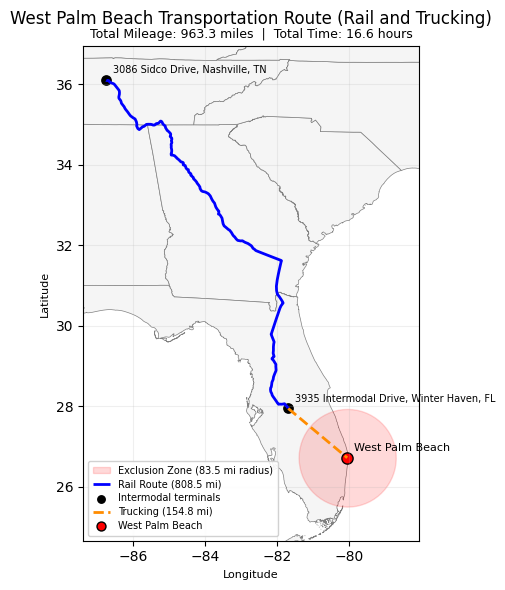

In [ ]:
#Call the plotting function for West Palm Beach
plot_transportation_route('West Palm Beach', 26.7153, -80.0534) #The data being called is our top 5 + New Orleans, so it is usin gthe optimization output data

Response:

We report that for our most affected city, West Palm Beach, the optimal route is in fact intermodal. The supply hub originates from Nashville, TN, and moves long railroads (CSXT and NS) for 808.5 miles. Then it reaches an intermodal facility in Winter Haven, FL, to finish out the trip. Note that the max_wind value for West Palm Beach was only 83.5 miles, so that determines the radius of the exclusion zone in which rail can enter. No track segments within can be allowed, which means no intermodal facilites within can be allowed. In many cases storms grow larger as they move more towards the gulf, so a smaller storm on the East of FL is not obscure (though 83.5mi exclusion is by no means small itself). One thing to note is that the truck segment is not the road route, as we gathered a distance from the API, not points of each bit of road. Note, limitations apply on the exclusion zones/rail, as we do not know the true trajectory of a future storm.

Results for this route:
Rail Mileage - 808.5
Yard Mileage - 0.24
Facility container handling - Container on Flatcar
Rail Owners Used - NS & CSXT
Truck Mileage - 154.8
Total Time - 16.56h

Question 14:

In 2005 hurricane Katrina marked on of the most devistating hurricanes in U.S. history, measured in both economic impact and loss of life. We ran New Orleans in the optimization with a radius of 230mi (the radius of where the winds came down to 39mph, the range where rail roads where likely not harmed) to simulate what post-storm relief would look like. The following is the plot using the same plot function from above, CREATED 100% FROM AI (VIA CHAT-GPT), AS WILL BE DISCLOSED LATER BY JULIAN. Again, limitations apply, as we do not know the true trajectory of a future storm.

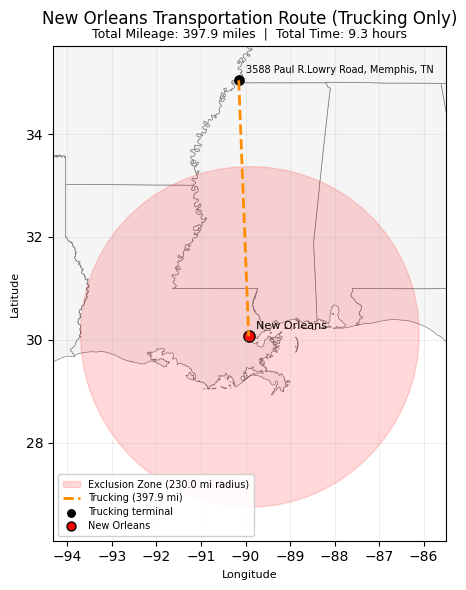

In [ ]:
#Call the plotting function for New Orleans
plot_transportation_route('New Orleans', 30.0687, -89.9288) #The data being called is our top 5 + New Orleans, so it is usin gthe optimization output data

Question 15:

How do the average speeds of the trucking routes compare to the estimated average of 70mph for trains on the main branches?

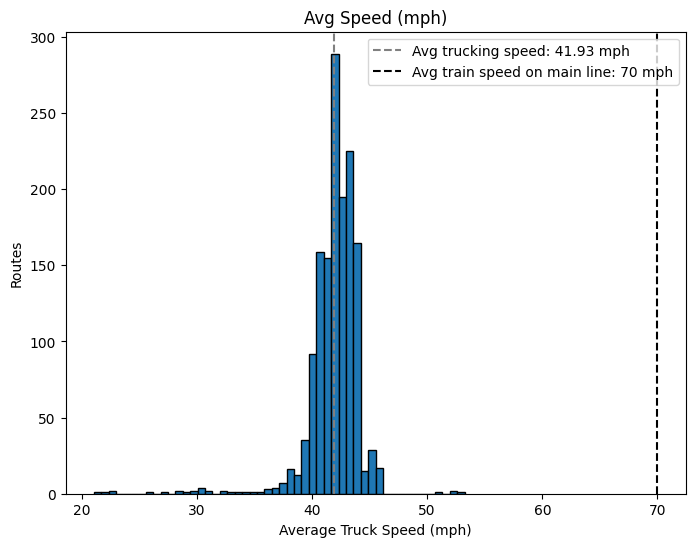

In [ ]:
import matplotlib.pyplot as plt

trucking = pd.read_excel(julian_generated_or_source('Truck Clean.xlsx'))
trucking['Avg Truck Speed (mph)'] = trucking['Truck Mileage'] / trucking['duration_hours']
avg_truck_speed = trucking['Avg Truck Speed (mph)'].mean()

plt.figure(figsize=(8, 6))
plt.hist(trucking['Avg Truck Speed (mph)'], bins=50, edgecolor='black')
plt.axvline(avg_truck_speed, color='grey', linestyle='--', label=f'Avg trucking speed: {avg_truck_speed:.2f} mph')
plt.axvline(70, color='black', linestyle='--', label='Avg train speed on main line: 70 mph')
plt.legend()
plt.xlabel('Average Truck Speed (mph)')
plt.ylabel('Routes')
plt.title('Avg Speed (mph)')
plt.show()


Response:

We report that for New Orleans the optimal route is unimodal, completed by trucking alone. The supply hub originates from Memphis, TN. Memphis has a population such that it can give aid. That, and the facts that it is out of the exclusion zone and produces a quicker delivery than any intermodal option makes it the optimal route. The truck completes the entire 397.9 mile journey. Againm one thing to note is that the truck segment is not the road route, as we gathered a distance from the API, not points of each bit of road.

Results for this route:
Rail Mileage - 0
Yard Mileage - 0
Facility container handling - NA
Rail Owners Used - NA
Truck Mileage - 397.9
Total Time - 9.3h

## 7. Key Insights and Implications

**Hurricane and population screening.** Population and historical storm-center county counts describe different planning dimensions. The latter is not a verified local wind-exposure estimate and should not be used alone to predict damage or landfall probability. Readiness planning should combine both indicators with operational information.

**Trucking access.** The 1,446 modeled hub–destination routes demonstrate why great-circle distance is insufficient for freight routing. The fastest candidate and its next-best alternatives vary by destination. These are normal-condition road estimates; fallback routes that were not generated with truck-specific restrictions must not be described as truck-validated.

**Rail–truck coordination.** Track-mile ownership and the rail graph help identify potential rail partners and connections. Julian's optimization supplies a scenario-based rail–truck comparison, not proof of globally optimal or disaster-resilient routes. In particular, the Palm Beach/West Palm Beach naming and coordinate discrepancy needs resolution before interpreting that destination's result.

**Actionable next steps.** Validate destination coordinates and route modes, independently check the optimization outputs, and model closures, damaged infrastructure, transfer handling, and usable hub capacity before testing the three-day relief target under hurricane conditions.


## 8. Challenges, Limitations, and Next Steps

**Data integration:** Hurricane records require missing-value handling and time standardization; county-level reverse-geocoding and exposure counts introduce geographic approximation. Intermodal and rail datasets require identifier normalization, facility-to-track matching, and duplicate checks. The trucking and optimization workbooks also require consistent destination labels and units.

**Model limitations:** Historical storm-center counts are not validated local wind exposure. Normal-condition routes do not account for closures, flooding, congestion, loading, capacity, or rail-yard accessibility. Some road-routing fallbacks lack confirmed heavy-goods-vehicle restrictions. Rail ownership mileage is not a measure of storm damage. Julian's scenario screening and nearest-hub assumptions do not independently prove global optimality.

**Outstanding checks:** Resolve the Palm Beach versus West Palm Beach coordinate/label mismatch; verify rail-ownership columns and time-component formulas against the original data; rerun NOAA and geography processing from a clean environment; and compare regenerated optimization workbooks with the submitted scenarios before relying on their reported travel times.

**Next step:** Validate inputs and then stress-test candidate routes against plausible hurricane disruptions, with a clear definition of what counts toward the three-day delivery objective.


## 9. Conclusion

The analysis demonstrates why relief planning needs both hazard context and a realistic transportation network. Population and historical hurricane measures highlight different potential priorities; modeled road routes provide a better travel-distance baseline than straight-line estimates; and rail connectivity adds both options and constraints. The combined work identifies candidate supply origins and routes worth investigating, but does not yet establish post-hurricane accessibility or reliable delivery within three days. The strongest recommendation is to validate destination coordinates, optimization outputs, and disruption assumptions before using the results for operational decisions.


## References

- National Hurricane Center. Atlantic Hurricane Database (HURDAT2).
- NOAA Climate Prediction Center. Monthly Atlantic Sea Surface Temperature Indices (North, South and Tropical Atlantic).
- NOAA Climate Prediction Center. Oceanic Niño Index.
- NSF National Center for Atmospheric Research. Climate Data Guide.
- U.S. Census Bureau. Vintage 2025 Population Estimates.
- Federal Railroad Administration / Bureau of Transportation Statistics. North American Rail Network.
- Bureau of Transportation Statistics. Intermodal Freight Facilities Rail TOFC/COFC.
- OpenRouteService (HeiGIT). Truck-routing distance and duration outputs for screened candidate routes; some fallback outputs may use ordinary driving profiles.

Full access links for the public datasets are provided in the Data Sources section at the beginning of the notebook. Project-specific inputs and submitted optimization workbooks are in the shared team folder.


## Generative AI Disclosure

#Alexander Renaud
AI assisted with seeking suggestions for block organization for better flow of the final notebook, and to gather a general idea (without asking for explanations or details) of the kinds of errors, logic, and methodological fixes that needed to happen in order to set aside the amount of hours necessary to ensure a presentable product.

Because of the large number of cells, AI was also used to consolidate repeated package imports (instead of having to go block by block) and to seek assistance in figuring out a much more efficient way to call on Google Drive files without having to copy and paste each and every individual link. Given this notebook is part of a graded assignment, AI was also used to make sure the group met strict rubric requirements. I do want to make it substantially clear that AI was never used to provide an answer.

#Julian LaLonde
AI, specifically ChatGPT (the free version, GPT-5.6 Luna), was used primarily in the optimization model section. It was used mostly for the purposes of debugging, and code runtime reduction ideas (many not taken because they were far too beyond my understanding, even when explained in plain text). It was used heavily in understanding the networkx library (I even prompted several mini lectures on the basics of networkx), and USED 100% IN CREATING THE PLOTS IN QUESTIONS 13 & 14 (but not anything in the markdowns).

As for some of the assistance in the networkx portion of the code, AI helped in fixing calculations of shortest paths between supply locations and eligible intermodal terminals. I also used GPT to help overcome errors in my mileage per ownership loop, so while the original structure was mine, debugging, some logic, and the final result must be credited to GPT. Again, much of debugging towards the latter half of the model was given to GPT to save time (I’d say often my initial fix was right but time inefficient, and thus scrapped).

To be more clear, I first built an optimization model of the ideal rail route based on the nearest legal intermodal hub. This was the vast majority my own work. However, I realized I was being small minded, and saw that perhaps a further intermodal hub could get a shorter route based on time if the supply came from another side (from example, not have to go around the exclusion zone). Thus, a model that integrated multiple hub options and chose the best was needed. I struggled and asked AI for assistance with looping on networkx and gathering our minimum time output. Again, networkx was a situation that usually called for AI and other sources for help.

In instances where a large dictionary or list is made to create abbreviations for states, I used AI for that. The cases are from the population cleaning to make an eligible cities data set, there is a dictionary used a few lines later in .map(), and in this submission it is in the optimization model as the 48 states in mainland USA (used to help filter for what states can go in the region parameter).

As for plotting, AI generated 100% of the code used to produce the project's map visualizations in 13 & 14. It also showed me the attributes/inputs of the vertical axis marker on the trucking v train avg sped plot.

#Alejandra Hurtado
I used AI as a tutor and code reviewer. In some cases, it explained errors, showed how to do specific operations and gave feedback. I did not paste code that I did not understand. In most cases I rewrote the suggestions, and tried to use most of the tools shared in class.

In some cases, AI explained tools we did not cover in class: the reverse_geocoder and os libraries, a spatial join between points and Census county boundaries to obtain county codes, and Plotly map charts. I adapted and tested the code. I asked AI how to add city, county and country columns from latitude and longitude, which was done with reverse_geocoder. I used os with it to build a U.S. only table of cities and counties and used it to standardize names. The same data could have been loaded from a CSV file, but I preferred not to rely on local files.

For charts and visualizations, I followed the Plotly documentation shared in class and used AI to help customize colors, titles, legends, formatting, and geolocation features.

For writing, I used AI to check grammar and correct sentences.
For regression, I wrote all the code from scratch, following the class notebooks. I only asked AI conceptual questions to support decision-making and help with debugging, such as whether I could use a single variable to predict another.

#Sonic Hsu
I used AI to assist with Python code debugging and data cleaning. It helped explain technical concepts and analytical methods, including the Haversine Formula and hurricane movement distances. AI also assisted with troubleshooting data processing and time issues, improving data visualization formatting, and refining EDA descriptions, chart interpretations, and project documentation.

## Team Contributions

Alexander Renaud served as project manager and coordinated the integration of the team's work. Alexander Renaud and Julian LaLonde worked on the population, routing, rail, intermodal, and transportation-network portions of the project. Alejandra Hurtado Burghardt and Chao-Tsun (Sonic) Hsu worked on the hurricane and weather portions of the project.
